# Fidelidade, estabilidade e limitações das explicações LIME — Titanic

Notebook experimental adaptado do exemplo do **Capítulo 04 (*Introduction to LIME for model interpretability*)** de *Applied Machine Learning Explainability Techniques*, de [**Aditya Bhattacharya**](https://www.linkedin.com/in/aditya-bhattacharya-b59155b6/) (Packt). O dataset, a ideia do modelo baseline e parte do código utilitário vêm desse trabalho (ver *Reference*); o desenho experimental e a análise são deste notebook.

### Objetivo

Avaliar o que as explicações do LIME (`LimeTabularExplainer`) permitem concluir sobre um classificador XGBoost treinado no Titanic: **fidelidade** ao modelo (Atividade 2), **estabilidade** face a `num_samples` e à semente (3), efeito da **representação** das features contínuas (4), **cobertura** com SP-LIME (5) e **plausibilidade** das vizinhanças sintéticas (6). A Atividade 7 junta a evidência para responder porque a explicação muda e o que verificar antes de a usar numa decisão. Os pesos LIME são tratados como coeficientes de um substituto linear local, não como importância global nem como efeitos causais.

### Estado do notebook

Implementadas: preparação (dados, modelo baseline, integração com LIME, reprodutibilidade) e **Atividades 1–7**. O relatório final **não** faz parte deste notebook.

O exemplo original (SP-LIME e a discussão dos gráficos) foi retirado desta base: usava o dataset completo como referência do explainer, truncava `Age`/`Fare` para inteiros e interpretava os pesos LIME como percentagens de importância. Está disponível no histórico do git.

### Ambiente e carregamento dos módulos

O ambiente é gerido com `uv` (ver `pyproject.toml`); não se instalam pacotes a partir do notebook.

In [1]:
import platform
from importlib.metadata import version

import numpy as np
import pandas as pd
from lime.lime_tabular import LimeTabularExplainer
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split

### Dados

**Titanic (OpenML, id 40945).** Classificação binária da sobrevivência (`Survived`) com variáveis categóricas, ordinais e contínuas, e alguns identificadores. Fonte: https://www.openml.org/search?type=data&sort=runs&id=40945&status=active. O ficheiro local `titanic.csv` é só lido.

### Configuração experimental

Todos os parâmetros que definem as experiências ficam aqui. `LIME_CONFIG` é a configuração por omissão: cada experiência pode sobrepor apenas o que muda (por exemplo `random_state` ou `num_samples`).

In [2]:
DATA_PATH = 'titanic.csv'
SEED = 123            # split treino/teste e modelo (valores do notebook original)
TEST_SIZE = 0.2
MODEL_PARAMS = dict(n_estimators=300, random_state=SEED)

LIME_CONFIG = dict(
    random_state=123,
    discretize_continuous=True,
    num_samples=5000,   # valor por omissão do LIME
    num_features=5,     # valor usado no notebook original
)
CLASS_NAMES = ['Did not Survive', 'Survived']
TARGET_CLASS = 1        # explicações sempre para Survived = 1

print('python', platform.python_version(), '|', platform.platform())
for pkg in ['numpy', 'pandas', 'scikit-learn', 'xgboost', 'lime']:
    print(f'{pkg:<13}{version(pkg)}')
print('SEED', SEED, '| TEST_SIZE', TEST_SIZE)
print('MODEL_PARAMS', MODEL_PARAMS)
print('LIME_CONFIG ', LIME_CONFIG)

python 3.12.13 | Windows-11-10.0.26200-SP0
numpy        2.5.4
pandas       3.1.0
scikit-learn 1.9.1
xgboost      3.4.1
lime         0.2.0.1
SEED 123 | TEST_SIZE 0.2
MODEL_PARAMS {'n_estimators': 300, 'random_state': 123}
LIME_CONFIG  {'random_state': 123, 'discretize_continuous': True, 'num_samples': 5000, 'num_features': 5}


### Carregamento dos dados

In [3]:
# O CSV original é só lido, nunca escrito
raw = pd.read_csv(DATA_PATH)
raw.head(15)

,PassengerId,Pclass,Survived,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,1,1,"Allen,Miss. Elisabeth Walton",female,29,0,0,24160,211.3375,B5,S
1,2,1,1,"Allison,Master. Hudson Trevor",male,0.9167,1,2,113781,151.55,C22 C26,S
2,3,1,0,"Allison,Miss. Helen Loraine",female,2,1,2,113781,151.55,C22 C26,S
3,4,1,0,"Allison,Mr. Hudson Joshua Creighton",male,30,1,2,113781,151.55,C22 C26,S
4,5,1,0,"Allison,Mrs. Hudson J C (Bessie Waldo Daniels)",female,25,1,2,113781,151.55,C22 C26,S
5,6,1,1,"Anderson,Mr. Harry",male,48,0,0,19952,26.55,E12,S
6,7,1,1,"Andrews,Miss. Kornelia Theodosia",female,63,1,0,13502,77.9583,D7,S
7,8,1,0,"Andrews,Mr. Thomas Jr",male,39,0,0,112050,0,A36,S
8,9,1,1,"Appleton,Mrs. Edward Dale (Charlotte Lamson)",female,53,2,0,11769,51.4792,C101,S
9,10,1,0,"Artagaveytia,Mr. Ramon",male,71,0,0,PC 17609,49.5042,?,C


In [4]:
print('Dimensões antes do pré-processamento:', raw.shape)
raw.info()

Dimensões antes do pré-processamento: (1309, 12)
<class 'pandas.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   PassengerId  1309 non-null   int64
 1   Pclass       1309 non-null   int64
 2   Survived     1309 non-null   int64
 3   Name         1309 non-null   str  
 4   Sex          1309 non-null   str  
 5   Age          1309 non-null   str  
 6   SibSp        1309 non-null   int64
 7   Parch        1309 non-null   int64
 8   Ticket       1309 non-null   str  
 9   Fare         1309 non-null   str  
 10  Cabin        1309 non-null   str  
 11  Embarked     1309 non-null   str  
dtypes: int64(5), str(7)
memory usage: 122.8 KB


**Decisões sobre as variáveis.** `PassengerId`, `Ticket` e `Name` são identificadores sem valor preditivo e saem das features (`PassengerId` fica como índice). `Cabin` é esparsa e exigiria engenharia de features, por isso é removida. O objetivo não é otimizar o modelo (sem ajuste de hiperparâmetros), mas dispor de um classificador fixo cujas explicações LIME se analisam.

### Pré-processamento

Mantém-se o pré-processamento de referência (remover `PassengerId`, `Name`, `Cabin`, `Ticket` das features; `?` = valor em falta; remover registos incompletos; codificar `Sex` e `Embarked`). Duas diferenças face ao original, sem alterar o conteúdo do modelo:

- `PassengerId` passa a ser o **índice** do DataFrame (identificador externo, único). Assim `X_test.loc[id]` é por identificador e `X_test.iloc[k]` por posição, sem ambiguidade.
- Todas as features ficam em `float64`. O XGBoost converte para `float32` internamente, logo o modelo é o mesmo; mas as perturbações do LIME deixam de ser truncadas para inteiro (o original fazia `.astype(int)` e destruía `Age` e `Fare`).

`Sex`: `female=0`, `male=1` (mesma codificação do `LabelEncoder` original, mas explícita).

In [5]:
data = raw.replace('?', np.nan)
assert data['PassengerId'].is_unique
data = data.set_index('PassengerId')
data = data.drop(columns=['Name', 'Cabin', 'Ticket'])
print('Valores em falta por coluna:'); print(data.isna().sum()[lambda s: s > 0].to_string())

data = data.dropna()
data['Age'] = data['Age'].astype(float)
data['Fare'] = data['Fare'].astype(float)
data['Sex'] = data['Sex'].map({'female': 0, 'male': 1})
data = pd.get_dummies(data, columns=['Embarked'], dtype=int)

y = data['Survived'].astype(int)
X = data.drop(columns=['Survived']).astype(float)
FEATURES = list(X.columns)

print('\nDimensões depois do pré-processamento:', data.shape, '| X', X.shape, '| registos removidos:', len(raw) - len(data))
print('Features:', FEATURES)
print('\nDistribuição do target (Survived):')
print(pd.DataFrame({'n': y.value_counts().sort_index(), 'proporção': y.value_counts(normalize=True).sort_index().round(4)}))
X.head()

Valores em falta por coluna:
Age         263
Fare          1
Embarked      2

Dimensões depois do pré-processamento: (1043, 10) | X (1043, 9) | registos removidos: 266
Features: ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked_C', 'Embarked_Q', 'Embarked_S']

Distribuição do target (Survived):
            n  proporção
Survived                
0         618     0.5925
1         425     0.4075


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S
PassengerId,,,,,,,,,
1,1.0,0.0,29.0000,0.0,0.0,211.3375,0.0,0.0,1.0
2,1.0,1.0,0.9167,1.0,2.0,151.5500,0.0,0.0,1.0
3,1.0,0.0,2.0000,1.0,2.0,151.5500,0.0,0.0,1.0
4,1.0,1.0,30.0000,1.0,2.0,151.5500,0.0,0.0,1.0
5,1.0,0.0,25.0000,1.0,2.0,151.5500,0.0,0.0,1.0


### Modelo baseline (XGBoost)

In [6]:
# Sem stratify, sem otimização de hiperparâmetros: configuração do original
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, random_state=SEED)

assert X_train.index.is_unique and X_test.index.is_unique
assert set(X_train.index).isdisjoint(X_test.index), 'treino e teste partilham passageiros'
assert len(X_train) + len(X_test) == len(X)
print('treino', X_train.shape, '| teste', X_test.shape, '| interseção:', len(set(X_train.index) & set(X_test.index)))
print('Target treino:', y_train.value_counts().sort_index().to_dict(), '| teste:', y_test.value_counts().sort_index().to_dict())

model = XGBClassifier(**MODEL_PARAMS)
model.fit(X_train, y_train)
print('\nAccuracy no conjunto de teste: %.4f  (original com versões antigas: 0.7751)' % model.score(X_test, y_test))

treino (834, 9) | teste (209, 9) | interseção: 0
Target treino: {0: 498, 1: 336} | teste: {0: 120, 1: 89}



Accuracy no conjunto de teste: 0.7656  (original com versões antigas: 0.7751)


### Integração com LIME

**Decisões**

- **Dados de referência:** só `X_train`; nenhuma informação do conjunto de teste entra no explainer.
- **Features categóricas** (`categorical_features`): `Sex` (binária), `Pclass` (apenas 3 níveis, tratada como categoria para obter condições do tipo `Pclass=3` em vez de limiares artificiais) e `Embarked_C/Q/S` (indicadores 0/1). `Age`, `Fare`, `SibSp` e `Parch` ficam contínuas e são discretizadas por quartis quando `discretize_continuous=True`.
- **Classe explicada:** `Survived = 1` (`labels=(1,)`), para que o sinal dos pesos tenha sempre o mesmo significado: positivo empurra a previsão local para sobreviver.
- **Aleatoriedade:** `random_state` (inteiro) é passado ao explainer, que cria o seu próprio `RandomState` (amostragem e Ridge). Não depende de `np.random.seed`. Esse estado **avança** a cada explicação, por isso `run_lime` cria um explainer novo em cada chamada: o resultado depende só da configuração e do passageiro, não da ordem das chamadas.
- **`kernel_width`:** valor por omissão do LIME (0,75·√n_features = 2,25 com 9 features); só a Atividade 7 o varia.
- **`predict_fn`:** reconstrói um DataFrame com `FEATURES` na ordem de treino antes de chamar `predict_proba`; a coluna 1 é `P(Survived=1)` (`model.classes_ == [0, 1]` verificado abaixo).

**Limitações (retomadas nas Atividades 3, 4 e 6)**

- O LIME perturba cada indicador de `Embarked` de forma independente, o que gera combinações impossíveis (zero ou duas portas de embarque). O modelo baseline não foi alterado por isto.
- Os pesos LIME são coeficientes de um modelo linear local e dependem da vizinhança (kernel, discretização, `num_samples`, semente). **Não** são percentagens de importância nem efeitos causais.

In [7]:
CAT_FEATURES = ['Sex', 'Pclass', 'Embarked_C', 'Embarked_Q', 'Embarked_S']
CAT_IDX = [FEATURES.index(f) for f in CAT_FEATURES]


def predict_fn(x):
    """Probabilidades (n, 2) na ordem de model.classes_, com as colunas pela ordem de treino."""
    return model.predict_proba(pd.DataFrame(x, columns=FEATURES))


def build_explainer(random_state, discretize_continuous, kernel_width=None):
    """Explainer novo e independente, com X_train como único dado de referência.
    kernel_width=None é o valor por omissão do LIME (só a Atividade 7 o altera)."""
    return LimeTabularExplainer(
        X_train.values,
        mode='classification',
        training_labels=y_train.values,
        feature_names=FEATURES,
        class_names=CLASS_NAMES,
        categorical_features=CAT_IDX,
        categorical_names={FEATURES.index('Sex'): ['female', 'male']},
        discretize_continuous=discretize_continuous,
        kernel_width=kernel_width,
        random_state=random_state,
    )


def explain_passenger(explainer, passenger_id, num_samples, num_features, predict=predict_fn):
    """Explica um passageiro do teste (por PassengerId) para a classe Survived = 1."""
    assert passenger_id in X_test.index, f'PassengerId {passenger_id} não está em X_test'
    return explainer.explain_instance(
        X_test.loc[passenger_id].values, predict,
        labels=(TARGET_CLASS,), num_features=num_features, num_samples=num_samples)


def run_lime(passenger_id, **overrides):
    """Explainer novo + explicação, a partir de LIME_CONFIG com as alterações pedidas."""
    cfg = {**LIME_CONFIG, **overrides}
    explainer = build_explainer(cfg['random_state'], cfg['discretize_continuous'])
    return explain_passenger(explainer, passenger_id, cfg['num_samples'], cfg['num_features'])


def summarize(exp, passenger_id):
    """Números da explicação num dicionário, para comparar configurações no futuro."""
    return dict(
        passenger_id=passenger_id,
        p_model=float(exp.predict_proba[TARGET_CLASS]),
        intercept=float(exp.intercept[TARGET_CLASS]),
        local_pred=float(np.ravel(exp.local_pred)[0]),
        r2=float(exp.score),
        weights=[(FEATURES[i], float(w)) for i, w in exp.local_exp[TARGET_CLASS]],
        rules=exp.as_list(label=TARGET_CLASS),
    )

### Smoke test

Uma única explicação, só para validar a integração (sem interpretação nem gráficos). O passageiro é o primeiro do conjunto de teste, escolhido por `PassengerId`.

In [8]:
SMOKE_ID = int(X_test.index[0])
exp = run_lime(SMOKE_ID)
res = summarize(exp, SMOKE_ID)

print('PassengerId:', SMOKE_ID, '| Survived real:', int(y_test.loc[SMOKE_ID]))
print('Instância:', X_test.loc[SMOKE_ID].to_dict())
print('P(Survived=1) modelo: %.4f | intercept: %.4f | local_pred: %.4f | R² local: %.4f' %
      (res['p_model'], res['intercept'], res['local_pred'], res['r2']))
for rule, w in res['rules']:
    print(f'  {rule:<28}{w:+.4f}')

PassengerId: 360 | Survived real: 1
Instância: {'Pclass': 2.0, 'Sex': 1.0, 'Age': 0.8333, 'SibSp': 0.0, 'Parch': 2.0, 'Fare': 29.0, 'Embarked_C': 0.0, 'Embarked_Q': 0.0, 'Embarked_S': 1.0}
P(Survived=1) modelo: 0.9996 | intercept: 0.7554 | local_pred: 0.2855 | R² local: 0.3865
  Sex=male                    -0.4920
  Age <= 21.00                +0.1313
  Embarked_C=0                -0.1108
  Pclass=2                    +0.0818
  15.02 < Fare <= 34.38       -0.0803


### Verificações

In [9]:
# 1. O passageiro pertence a X_test (e não a X_train); índice por id e por posição coincidem
pos = X_test.index.get_loc(SMOKE_ID)
assert SMOKE_ID in X_test.index and SMOKE_ID not in X_train.index
assert X_test.iloc[pos].equals(X_test.loc[SMOKE_ID])

# 2. Features completas e pela ordem de treino, em todo o lado
explainer = build_explainer(LIME_CONFIG['random_state'], LIME_CONFIG['discretize_continuous'])
assert FEATURES == list(X_train.columns) == list(X_test.columns)
assert FEATURES == list(explainer.feature_names) == list(model.feature_names_in_)
assert not X.isna().any().any() and (X.dtypes == 'float64').all()
# com discretização o LIME marca todas as features como categóricas; as contínuas são as discretizadas
assert {FEATURES[i] for i in range(len(FEATURES)) if i not in explainer.discretizer.lambdas} == set(CAT_FEATURES)
assert build_explainer(123, False).categorical_features == CAT_IDX

# 3. predict_fn: probabilidades válidas, na ordem das classes
assert list(model.classes_) == [0, 1]
p_fn = predict_fn(X_test.values)
assert p_fn.shape == (len(X_test), 2) and np.isfinite(p_fn).all()
assert ((p_fn >= 0) & (p_fn <= 1)).all() and np.allclose(p_fn.sum(axis=1), 1, atol=1e-6)
assert (p_fn.argmax(axis=1) == model.predict(X_test)).all()   # coluna 1 = Survived

# 4. Modelo direto vs predict_fn
p_direct = model.predict_proba(X_test)
assert np.allclose(p_direct, p_fn, rtol=0, atol=1e-6)
assert np.isclose(res['p_model'], p_direct[pos, 1], rtol=0, atol=1e-6)

# 5. Age e Fare sem truncagem: dados do explainer vs X_train e amostras perturbadas vistas pelo modelo
seen = []
def recording_predict(x):
    seen.append(np.array(x))
    return predict_fn(x)
explain_passenger(build_explainer(123, True), SMOKE_ID, 500, 5, predict=recording_predict)
batch = seen[0]
age_i, fare_i = FEATURES.index('Age'), FEATURES.index('Fare')
assert batch.shape == (500, len(FEATURES))
assert np.array_equal(batch[0], X_test.loc[SMOKE_ID].values)             # 1ª linha = instância original
assert (X_train['Age'] % 1 != 0).any() and (X_train['Fare'] % 1 != 0).any()
assert (batch[:, age_i] % 1 != 0).any() and (batch[:, fare_i] % 1 != 0).any()
assert X_test.loc[SMOKE_ID, 'Age'] == float(raw.set_index('PassengerId').loc[SMOKE_ID, 'Age'])

# 6. Explicação válida
w = np.array([x for _, x in res['weights']])
assert len(res['weights']) == LIME_CONFIG['num_features'] and len({n for n, _ in res['weights']}) == len(w)
assert np.isfinite(w).all() and np.isfinite([res['intercept'], res['local_pred'], res['r2']]).all()
assert res['r2'] <= 1
assert set(exp.local_exp) == {TARGET_CLASS}

# 7. Reprodutibilidade: mesma semente (mesmo com outra explicação pelo meio) = mesmo resultado; outra semente = diferente
a = summarize(run_lime(SMOKE_ID), SMOKE_ID)
_ = run_lime(SMOKE_ID, random_state=7)
b = summarize(run_lime(SMOKE_ID), SMOKE_ID)
c = summarize(run_lime(SMOKE_ID, random_state=7), SMOKE_ID)
assert a == b == res
assert a['weights'] != c['weights'] and a['r2'] != c['r2']

print('Todas as verificações passaram.')
print('Seed 123 vs seed 7 -> pesos:')
print(pd.DataFrame({'seed123': dict(a['weights']), 'seed7': dict(c['weights'])}).round(4).to_string())
print('R² local: seed123 %.4f | seed7 %.4f' % (a['r2'], c['r2']))

Todas as verificações passaram.
Seed 123 vs seed 7 -> pesos:
            seed123   seed7
Sex         -0.4920 -0.5120
Age          0.1313  0.1258
Embarked_C  -0.1108 -0.0925
Pclass       0.0818  0.0841
Fare        -0.0803 -0.0790
R² local: seed123 0.3865 | seed7 0.4057


## Atividade 1 — Compare Different Passengers

**Seleção (determinística, sem escolha manual).** 20 passageiros distintos de `X_test`, sem reposição, com `np.random.default_rng(123)` (gerador próprio, independente do estado aleatório do LIME). Ordenam-se por `P(Survived)` prevista pelo XGBoost (crescente) e os **5** do primeiro painel são as posições `round(linspace(0, 19, 5))` = 0, 5, 10, 14, 19 dessa ordenação: os dois extremos e três valores intermédios, todos pertencentes aos 20.

**Configuração LIME:** a de `LIME_CONFIG` (`random_state=123`, `num_samples=5000`, `num_features=5`, `discretize_continuous=True`) e `labels=(1,)`, sem alterações. Cada passageiro é explicado uma vez; as tabelas usam os 3 contributos de maior |peso| dos 5 disponíveis. Pesos positivos empurram a previsão local para `Survived=1`, negativos para `Survived=0`.

In [10]:
N_PASSENGERS = 20


def select_passengers(seed=123):
    rng = np.random.default_rng(seed)
    ids = [int(i) for i in rng.choice(X_test.index.to_numpy(), size=N_PASSENGERS, replace=False)]
    p = pd.Series(predict_fn(X_test.loc[ids].values)[:, TARGET_CLASS], index=ids)
    ids = list(p.sort_values(kind='stable').index)           # P(Survived) crescente
    ids5 = [ids[k] for k in np.linspace(0, N_PASSENGERS - 1, 5).round().astype(int)]
    return ids, ids5


ids20, ids5 = select_passengers()
print('5 passageiros :', ids5)
print('20 passageiros:', ids20)

5 passageiros : [759, 509, 307, 1190, 320]
20 passageiros: [759, 838, 1147, 445, 566, 509, 422, 751, 1184, 1095, 307, 61, 584, 600, 1190, 472, 585, 1224, 592, 320]


In [11]:
exps = {pid: run_lime(pid) for pid in ids20}                 # LIME_CONFIG, explainer novo por passageiro
results = {pid: summarize(exps[pid], pid) for pid in ids20}

# Uma linha por (passageiro, atributo): feature vem do índice estruturado do LIME, condition do as_list
rows = []
for pid in ids20:
    r = results[pid]
    ranked = sorted(zip(r['weights'], r['rules']), key=lambda t: -abs(t[0][1]))
    for rank, ((feat, w), (cond, w_rule)) in enumerate(ranked, 1):
        assert np.isclose(w, w_rule, rtol=0, atol=1e-12) and feat in cond
        rows.append(dict(PassengerId=pid, rank=rank, feature=feat, condition=cond, weight=w))
contrib = pd.DataFrame(rows)
top3 = contrib[contrib['rank'] <= 3]


def top3_table(ids):
    out = []
    for pid in ids:
        r = results[pid]
        row = {'PassengerId': pid, 'P(Survived)': f"{r['p_model']:.6f}"}
        for x in top3[top3['PassengerId'] == pid].itertuples():
            row[f'Top {x.rank}'] = f'{x.condition}  ({x.weight:+.4f})'
        row['Intercept'] = f"{r['intercept']:+.4f}"
        row['Local pred'] = f"{r['local_pred']:+.4f}"
        out.append(row)
    return pd.DataFrame(out).set_index('PassengerId')


pd.set_option('display.max_colwidth', None, 'display.width', 250)
print('Tabela A — 5 passageiros (ordenados por P(Survived))')
table_a = top3_table(ids5)
table_a

Tabela A — 5 passageiros (ordenados por P(Survived))


,P(Survived),Top 1,Top 2,Top 3,Intercept,Local pred
PassengerId,,,,,,
759,0.000423,Sex=male (-0.4941),Pclass=3 (-0.2459),Embarked_C=0 (-0.1128),+0.9508,-0.0423
509,0.003505,Sex=male (-0.5009),Age > 38.00 (-0.1616),Embarked_C=0 (-0.1058),+0.7731,+0.1443
307,0.105204,Sex=male (-0.5077),Pclass=1 (+0.2366),Age > 38.00 (-0.1546),+0.7276,+0.2623
1190,0.934156,Sex=female (+0.4879),Pclass=3 (-0.2634),Age <= 21.00 (+0.1131),+0.4219,+0.5567
320,0.999882,Sex=female (+0.5079),Pclass=1 (+0.2432),Embarked_C=1 (+0.1027),+0.0850,+0.9626


In [12]:
print('Tabela B — 20 passageiros (ordenados por P(Survived))')
table_b = top3_table(ids20)
table_b

Tabela B — 20 passageiros (ordenados por P(Survived))


,P(Survived),Top 1,Top 2,Top 3,Intercept,Local pred
PassengerId,,,,,,
759,0.000423,Sex=male (-0.4941),Pclass=3 (-0.2459),Embarked_C=0 (-0.1128),+0.9508,-0.0423
838,0.000619,Sex=male (-0.5011),Pclass=3 (-0.2366),Embarked_C=0 (-0.1076),+0.8877,+0.0895
1147,0.000744,Sex=female (+0.4905),Pclass=3 (-0.2599),Age > 38.00 (-0.1590),+0.4905,+0.3565
445,0.001886,Sex=male (-0.4981),Age <= 21.00 (+0.1243),Embarked_C=0 (-0.1063),+0.7459,+0.3006
566,0.002917,Sex=male (-0.5004),Embarked_C=0 (-0.1093),Pclass=2 (+0.0746),+0.7601,+0.2561
509,0.003505,Sex=male (-0.5009),Age > 38.00 (-0.1616),Embarked_C=0 (-0.1058),+0.7731,+0.1443
422,0.004998,Sex=male (-0.5004),Embarked_C=0 (-0.1093),Pclass=2 (+0.0746),+0.7601,+0.2561
751,0.006845,Sex=male (-0.5001),Pclass=3 (-0.2369),Embarked_C=0 (-0.1099),+0.8378,+0.1668
1184,0.015634,Sex=male (-0.5006),Pclass=3 (-0.2377),Age > 38.00 (-0.1586),+0.9189,+0.0261


### Frequência dos contributos nas 20 explicações

Frequência = nº de passageiros (em 20) em que a feature está entre os 3 maiores |peso|, contada pelo índice de feature do LIME (não por parsing do texto). Descreve apenas **estas 20 explicações**.

In [13]:
from IPython.display import display


def feature_counts(df):
    g = df.groupby('feature')['weight']
    return (pd.DataFrame({'n': g.size(), 'pesos +': g.apply(lambda s: int((s > 0).sum())),
                          'pesos -': g.apply(lambda s: int((s < 0).sum()))})
            .reset_index().sort_values(['n', 'feature'], ascending=[False, True]).set_index('feature'))


freq3 = feature_counts(top3)
freq5 = feature_counts(contrib)
print('Top 3 por passageiro (total de ocorrências: %d)' % freq3['n'].sum())
display(freq3.join(freq5.add_suffix(' (top5)')).fillna(0).astype(int))

mixed = freq3.index[(freq3['pesos +'] > 0) & (freq3['pesos -'] > 0)]
print('Features com sinais opostos entre passageiros (top 3):', list(mixed))
display(top3[top3['feature'].isin(mixed)].sort_values(['feature', 'weight'])
        [['feature', 'PassengerId', 'condition', 'weight']].set_index('feature'))

# a feature não é a condição: condições concretas que se repetem
cond = top3.groupby(['feature', 'condition'])['weight'].agg(n='size', peso_medio='mean')
print('Condições concretas que aparecem em 2 ou mais passageiros (top 3):')
display(cond[cond['n'] >= 2].sort_values('n', ascending=False).round(4))

Top 3 por passageiro (total de ocorrências: 60)


,n,pesos +,pesos -,n (top5),pesos + (top5),pesos - (top5)
feature,,,,,,
Sex,20,10,10,20,10,10
Embarked_C,15,1,14,20,1,19
Pclass,15,7,8,20,12,8
Age,9,3,6,9,3,6
Fare,1,1,0,12,4,8


Features com sinais opostos entre passageiros (top 3): ['Sex', 'Embarked_C', 'Pclass', 'Age']


,PassengerId,condition,weight
feature,,,
Age,509,Age > 38.00,-0.161624
Age,1147,Age > 38.00,-0.159042
Age,472,Age > 38.00,-0.158894
Age,584,Age > 38.00,-0.158857
Age,1184,Age > 38.00,-0.158589
Age,307,Age > 38.00,-0.154561
Age,1190,Age <= 21.00,0.113077
Age,592,Age <= 21.00,0.121822
Age,445,Age <= 21.00,0.124295


Condições concretas que aparecem em 2 ou mais passageiros (top 3):


n  peso_medio
feature    condition                   
Embarked_C Embarked_C=0  14     -0.1078
Sex        Sex=male      10     -0.5013
           Sex=female    10      0.4976
Pclass     Pclass=3       8     -0.2475
Age        Age > 38.00    6     -0.1586
Pclass     Pclass=2       4      0.0816
           Pclass=1       3      0.2395
Age        Age <= 21.00   3      0.1197

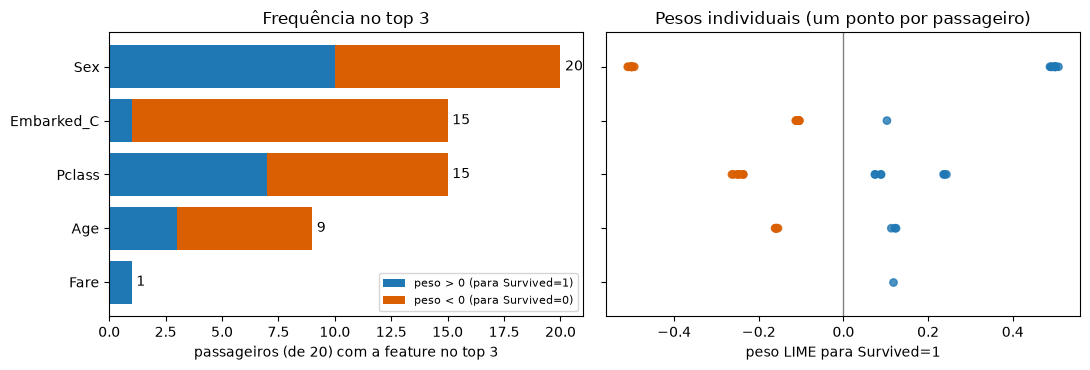

In [14]:
import matplotlib.pyplot as plt

order = list(freq3.index[::-1])
y = np.arange(len(order))
POS, NEG = '#1f77b4', '#d95f02'
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)

ax1.barh(y, freq3.loc[order, 'pesos +'], color=POS, label='peso > 0 (para Survived=1)')
ax1.barh(y, freq3.loc[order, 'pesos -'], left=freq3.loc[order, 'pesos +'], color=NEG, label='peso < 0 (para Survived=0)')
for yi, f in zip(y, order):
    ax1.text(freq3.loc[f, 'n'] + 0.2, yi, int(freq3.loc[f, 'n']), va='center')
ax1.set_yticks(y, order)
ax1.set_xlabel('passageiros (de 20) com a feature no top 3')
ax1.set_title('Frequência no top 3')
ax1.legend(loc='lower right', fontsize=8)

for yi, f in zip(y, order):
    w = top3.loc[top3['feature'] == f, 'weight']
    ax2.scatter(w, np.full(len(w), yi), c=np.where(w > 0, POS, NEG), alpha=.8, s=28)
ax2.axvline(0, color='gray', lw=1)
ax2.set_xlabel('peso LIME para Survived=1')
ax2.set_title('Pesos individuais (um ponto por passageiro)')
plt.tight_layout()
plt.show()

In [15]:
# Validação da Atividade 1
from collections import Counter

assert LIME_CONFIG == dict(random_state=123, discretize_continuous=True, num_samples=5000, num_features=5)

# seleção: únicos, em X_test, 5 dentro dos 20, reprodutível, extremos incluídos
assert len(ids20) == len(set(ids20)) == N_PASSENGERS and set(ids20) <= set(X_test.index) and not set(ids20) & set(X_train.index)
assert len(ids5) == len(set(ids5)) == 5 and set(ids5) <= set(ids20)
assert select_passengers() == (ids20, ids5) == select_passengers(123)
p20 = [results[i]['p_model'] for i in ids20]
assert p20 == sorted(p20) and ids5[0] == ids20[0] and ids5[-1] == ids20[-1]

# tabelas: colunas pedidas, sem duplicados, mesma ordem/ids, linhas dos 5 idênticas nas duas tabelas
cols = ['P(Survived)', 'Top 1', 'Top 2', 'Top 3', 'Intercept', 'Local pred']
assert list(table_a.columns) == cols == list(table_b.columns)
assert list(table_a.index) == ids5 and list(table_b.index) == ids20 and table_b.index.is_unique
assert not table_a.isna().any().any() and not table_b.isna().any().any()
assert table_a.equals(table_b.loc[ids5])

# classe Survived=1: probabilidades, intercept, local_pred e pesos vêm das explicações geradas para a classe 1
for pid in ids20:
    e, r = exps[pid], results[pid]
    assert set(e.local_exp) == {TARGET_CLASS} == set(e.intercept)
    assert np.isclose(r['p_model'], predict_fn(X_test.loc[[pid]].values)[0, TARGET_CLASS], rtol=0, atol=1e-6)
    assert r['intercept'] == e.intercept[TARGET_CLASS] and r['local_pred'] == float(np.ravel(e.local_pred)[0])
    assert [(FEATURES[i], w) for i, w in e.local_exp[TARGET_CLASS]] == r['weights']

# frequências: recontadas de forma independente a partir das explicações
indep = Counter(f for pid in ids20
                for f, _ in sorted(results[pid]['weights'], key=lambda t: -abs(t[1]))[:3])
assert contrib.groupby('PassengerId').size().eq(LIME_CONFIG['num_features']).all()
assert freq3['n'].sum() == len(top3) == 3 * N_PASSENGERS == 60
assert freq3['n'].to_dict() == dict(indep)
assert ((freq3['pesos +'] + freq3['pesos -']) == freq3['n']).all()
print('Validação da Atividade 1: OK')

Validação da Atividade 1: OK


### Observações (Atividade 1)

**1. Que condições contribuem mais?** Em todos os 20 passageiros o maior |peso| é o de `Sex` (≈ ±0,49 a ±0,51): `Sex=male` negativo (10 casos) e `Sex=female` positivo (10 casos). A seguir vêm, quando presentes, `Pclass` (|peso| ≈ 0,07–0,26: `Pclass=3` ≈ −0,24 a −0,26, `Pclass=1` ≈ +0,24, `Pclass=2` ≈ +0,07 a +0,09), `Age` (`Age > 38.00` ≈ −0,16; `Age <= 21.00` ≈ +0,11 a +0,12) e `Embarked_C=0` (≈ −0,10 a −0,11). Nos 5 passageiros da Tabela A, o que varia entre justificações é essencialmente o 2.º e 3.º contributo: 759 (P≈0,0004) é explicado por homem, 3.ª classe e não embarcar em C; 320 (P≈0,9999) por mulher, 1.ª classe e `Embarked_C=1`; 307 (homem, P≈0,11) mostra `Pclass=1` com sinal positivo a contrariar `Sex=male`.

**2. Uma feature ajuda uns e prejudica outros?** Sim, mas por via de **condições diferentes** da mesma feature, não da mesma condição com sinais diferentes: dentro de cada condição o sinal é constante nestas 20 explicações. `Sex` (male −, female +), `Pclass` (3 −; 1 e 2 +), `Age` (> 38 −; ≤ 21 +) e `Embarked_C` (`=0` − em 14 casos; `=1` + só no 320) aparecem com os dois sinais no top 3. `Fare` aparece uma única vez no top 3 (1224, `Fare <= 8.05`, +), mas entra em 12 dos 20 top 5 com sinais mistos (4 +, 8 −), o que o top 3 esconde.

**3. Features mais frequentes (top 3, 60 ocorrências):** `Sex` 20, `Embarked_C` 15, `Pclass` 15, `Age` 9, `Fare` 1; `SibSp`, `Parch`, `Embarked_Q` e `Embarked_S` não aparecem. A condição mais repetida é `Embarked_C=0` (14), que é simplesmente "não ter embarcado em Cherbourg", a situação da maioria dos passageiros.

**Limites.**
- A frequência descreve **estas 20 explicações** (amostra aleatória de 209 passageiros de teste, não estratificada), não a importância global do modelo nem uma estimativa para todos os passageiros. Com n = 20 uma diferença de 1 ou 2 passageiros é ruído.
- Os pesos são coeficientes de um modelo linear local, não percentagens de importância nem efeitos causais, e o corte no top 3 depende de `num_features=5` e da discretização (as condições `Age > 38.00`, `Fare <= 8.05` são intervalos de quartis do treino).
- O ajuste local é irregular: a *local prediction* pode estar longe da probabilidade do modelo, por exemplo 1147 (P≈0,0007 e local ≈ +0,36) e 1095 (P≈0,075 e local ≈ +0,58). Os pesos explicam o modelo linear local e não reproduzem a saída do XGBoost nestes casos; fica para a Atividade 2.
- Passageiros com o mesmo perfil discretizado têm explicações praticamente idênticas (566 e 422 coincidem até à 4.ª casa decimal, com P de 0,0029 e 0,0050): a explicação distingue perfis por intervalo, não por valores exatos.

## Atividade 2 — Check Fidelity

Reutiliza os 20 passageiros e as explicações da Atividade 1 (`ids20`, `exps`, `results`): nada é recalculado nem alterado (modelo, divisão, seleção e `LIME_CONFIG` iguais).

- **Local R²** = `explanation.score`: R² ponderado do modelo linear local, calculado sobre a **vizinhança sintética** gerada pelo LIME (não é accuracy do classificador nem validade causal).
- **Erro absoluto** = `|P(Survived) − local_pred|`, com os valores sem arredondar e `local_pred` sem truncar a [0, 1]. Mede o desacordo da aproximação no próprio ponto explicado.
- As duas métricas medem coisas diferentes (ajuste global na vizinhança vs. erro num ponto) e podem não coincidir.
- **Grupos por probabilidade** (limites explícitos, só descritivos): `Near 0` P ≤ 0,1; `Near 1` P ≥ 0,9; `Uncertain` 0,4 ≤ P ≤ 0,6; `Intermediate` os restantes. "Very confident" = Near 0 + Near 1. Os nomes dos grupos (`Very confident`, `Uncertain`) são rótulos de faixas da **probabilidade prevista**; não pressupõem que o classificador esteja calibrado (a calibração não foi avaliada).

In [16]:
fid = pd.DataFrame({
    'P(Survived)': [results[p]['p_model'] for p in ids20],
    'Local pred': [results[p]['local_pred'] for p in ids20],
    'Local R2': [results[p]['r2'] for p in ids20],
    'Survived (real)': [int(y_test.loc[p]) for p in ids20],
}, index=pd.Index(ids20, name='PassengerId'))
fid['Abs error'] = (fid['P(Survived)'] - fid['Local pred']).abs()      # antes de qualquer arredondamento


def conf_group(p):
    if p <= 0.1:
        return 'Near 0'
    if p >= 0.9:
        return 'Near 1'
    return 'Uncertain' if 0.4 <= p <= 0.6 else 'Intermediate'


GROUPS = ['Near 0', 'Intermediate', 'Uncertain', 'Near 1']
fid['group'] = pd.Categorical([conf_group(p) for p in fid['P(Survived)']], categories=GROUPS, ordered=True)

print('Tabela de fidelidade — 20 passageiros (ordenados por P(Survived))')
display(fid.round(6))
print('local_pred fora de [0, 1]:', fid.index[(fid['Local pred'] < 0) | (fid['Local pred'] > 1)].tolist())

worst_r2 = fid.sort_values('Local R2').head(5)
worst_err = fid.sort_values('Abs error', ascending=False).head(5)
print('5 menores R² locais'); display(worst_r2[['P(Survived)', 'Local R2', 'Abs error']].round(6))
print('5 maiores erros absolutos'); display(worst_err[['P(Survived)', 'Local R2', 'Abs error']].round(6))
print('Em ambos os rankings:', sorted(set(worst_r2.index) & set(worst_err.index)))
print('Spearman R² vs erro absoluto: %.3f | P vs R²: %.3f | P vs erro: %.3f (n=20)' % (
    fid['Local R2'].corr(fid['Abs error'], method='spearman'),
    fid['P(Survived)'].corr(fid['Local R2'], method='spearman'),
    fid['P(Survived)'].corr(fid['Abs error'], method='spearman')))

Tabela de fidelidade — 20 passageiros (ordenados por P(Survived))


,P(Survived),Local pred,Local R2,Survived (real),Abs error,group
PassengerId,,,,,,
759,0.000423,-0.042274,0.454150,1,0.042697,Near 0
838,0.000619,0.089525,0.457754,0,0.088905,Near 0
1147,0.000744,0.356489,0.490643,0,0.355745,Near 0
445,0.001886,0.300574,0.386027,0,0.298688,Near 0
566,0.002917,0.256051,0.376142,0,0.253134,Near 0
509,0.003505,0.144328,0.404456,0,0.140823,Near 0
422,0.004998,0.256054,0.376142,0,0.251056,Near 0
751,0.006845,0.166814,0.462307,0,0.159969,Near 0
1184,0.015634,0.026103,0.485914,0,0.010469,Near 0


local_pred fora de [0, 1]: [759]
5 menores R² locais


,P(Survived),Local R2,Abs error
PassengerId,,,
566,0.002917,0.376142,0.253134
422,0.004998,0.376142,0.251056
600,0.926853,0.384960,0.158683
585,0.984142,0.386013,0.215039
445,0.001886,0.386027,0.298688


5 maiores erros absolutos


,P(Survived),Local R2,Abs error
PassengerId,,,
1095,0.075315,0.457466,0.507721
1190,0.934156,0.473340,0.377486
1147,0.000744,0.490643,0.355745
584,0.897924,0.413786,0.327671
1224,0.992789,0.477373,0.323223


Em ambos os rankings: []
Spearman R² vs erro absoluto: 0.035 | P vs R²: -0.063 | P vs erro: 0.084 (n=20)


### Fidelidade por grupo de probabilidade prevista e cobertura da faixa 0,4–0,6

In [17]:
summary = fid.groupby('group', observed=False).agg(
    n=('Local R2', 'size'), R2_mediana=('Local R2', 'median'), R2_min=('Local R2', 'min'), R2_max=('Local R2', 'max'),
    erro_mediano=('Abs error', 'median'), erro_max=('Abs error', 'max'))
vc = fid[fid['group'].isin(['Near 0', 'Near 1'])]
summary.loc['Very confident (0 + 1)'] = [len(vc), vc['Local R2'].median(), vc['Local R2'].min(), vc['Local R2'].max(),
                                         vc['Abs error'].median(), vc['Abs error'].max()]
summary['n'] = summary['n'].astype(int)
print('Fidelidade nos 20 passageiros, por grupo')
display(summary.round(4))

# Distribuição das probabilidades dos 209 passageiros de teste (sem novas explicações LIME)
p_test = pd.Series(predict_fn(X_test.values)[:, TARGET_CLASS], index=X_test.index)
g_test = pd.Series([conf_group(p) for p in p_test], index=p_test.index)
bins = np.linspace(0, 1, 11)
dist = pd.DataFrame({
    'teste (209)': pd.cut(p_test, bins, include_lowest=True).value_counts().sort_index(),
    'selecionados (20)': pd.cut(fid['P(Survived)'], bins, include_lowest=True).value_counts().sort_index()})
print('Probabilidades por intervalo de 0,1')
display(dist)
cover = pd.DataFrame({'teste (209)': g_test.value_counts().reindex(GROUPS), 'selecionados (20)': fid['group'].value_counts().reindex(GROUPS)})
print('Grupos de confiança')
display(cover)
print('Passageiros de teste com 0,4 <= P <= 0,6: %d de %d (%d nos 20 selecionados)' % (
    p_test.between(0.4, 0.6).sum(), len(p_test), fid['P(Survived)'].between(0.4, 0.6).sum()))

Fidelidade nos 20 passageiros, por grupo


,n,R2_mediana,R2_min,R2_max,erro_mediano,erro_max
group,,,,,,
Near 0,10,0.4558,0.3761,0.4906,0.2055,0.5077
Intermediate,3,0.4358,0.4138,0.4599,0.1571,0.3277
Uncertain,0,NaN,NaN,NaN,NaN,NaN
Near 1,7,0.4115,0.3850,0.4774,0.2178,0.3775
Very confident (0 + 1),17,0.4431,0.3761,0.4906,0.2178,0.5077


Probabilidades por intervalo de 0,1


,teste (209),selecionados (20)
"(-0.001, 0.1]",93,10
"(0.1, 0.2]",11,1
"(0.2, 0.3]",6,1
"(0.3, 0.4]",8,0
"(0.4, 0.5]",9,0
"(0.5, 0.6]",4,0
"(0.6, 0.7]",8,0
"(0.7, 0.8]",6,0
"(0.8, 0.9]",7,1
"(0.9, 1.0]",57,7


Grupos de confiança


,teste (209),selecionados (20)
Near 0,93,10
Intermediate,46,3
Uncertain,13,0
Near 1,57,7


Passageiros de teste com 0,4 <= P <= 0,6: 13 de 209 (0 nos 20 selecionados)


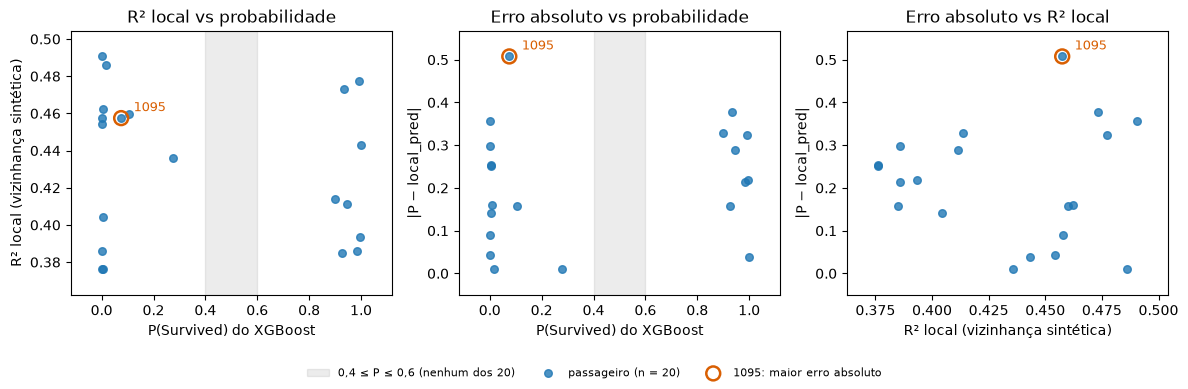

In [18]:
import matplotlib.pyplot as plt

HL = 1095                                                          # maior erro absoluto (ver célula seguinte)
assert HL == fid['Abs error'].idxmax()
panels = [('P(Survived)', 'Local R2', 'P(Survived) do XGBoost', 'R² local (vizinhança sintética)'),
          ('P(Survived)', 'Abs error', 'P(Survived) do XGBoost', '|P − local_pred|'),
          ('Local R2', 'Abs error', 'R² local (vizinhança sintética)', '|P − local_pred|')]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.9))
for ax, (xc, yc, xl, yl) in zip(axes, panels):
    if xc == 'P(Survived)':
        ax.axvspan(0.4, 0.6, color='gray', alpha=.15, label='0,4 ≤ P ≤ 0,6 (nenhum dos 20)')    # região incerta
    ax.scatter(fid[xc], fid[yc], s=30, color='#1f77b4', alpha=.8, label='passageiro (n = 20)')
    ax.scatter(fid.loc[[HL], xc], fid.loc[[HL], yc], s=100, facecolors='none', edgecolors='#d95f02', linewidths=1.8,
               label=f'{HL}: maior erro absoluto')
    ax.annotate(str(HL), (fid.loc[HL, xc], fid.loc[HL, yc]), textcoords='offset points', xytext=(9, 5), fontsize=9, color='#d95f02')
    ax.set_xlabel(xl)
    ax.set_ylabel(yl)
    ax.margins(x=0.12, y=0.12)
axes[0].set_title('R² local vs probabilidade')
axes[1].set_title('Erro absoluto vs probabilidade')
axes[2].set_title('Erro absoluto vs R² local')
fig.legend(*axes[1].get_legend_handles_labels(), loc='lower center', ncol=3, fontsize=8, frameon=False)
plt.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()

In [19]:
worst = int(fid['Abs error'].idxmax())
w = fid.loc[worst]
print(f"Maior erro absoluto: PassengerId {worst} | real Survived={int(w['Survived (real)'])} | grupo {w['group']}")
print('P(Survived) = %.6f | local_pred = %+.6f | R² local = %.4f | |P - local_pred| = %.6f' % (
    w['P(Survived)'], w['Local pred'], w['Local R2'], w['Abs error']))
print('R² local: posição %d de 20 (1 = pior) | erro absoluto: posição 1' % (fid['Local R2'].rank().loc[worst]))
print('Instância:', X_test.loc[worst].to_dict())
print('Intercept: %+.4f' % results[worst]['intercept'])
display(contrib[contrib['PassengerId'] == worst].set_index('rank')[['feature', 'condition', 'weight']].round(4))

Maior erro absoluto: PassengerId 1095 | real Survived=1 | grupo Near 0
P(Survived) = 0.075315 | local_pred = +0.583036 | R² local = 0.4575 | |P - local_pred| = 0.507721
R² local: posição 13 de 20 (1 = pior) | erro absoluto: posição 1
Instância: {'Pclass': 3.0, 'Sex': 0.0, 'Age': 31.0, 'SibSp': 0.0, 'Parch': 0.0, 'Fare': 8.6833, 'Embarked_C': 0.0, 'Embarked_Q': 0.0, 'Embarked_S': 1.0}
Intercept: +0.3093


,feature,condition,weight
rank,,,
1,Sex,Sex=female,0.4964
2,Pclass,Pclass=3,-0.2507
3,Embarked_C,Embarked_C=0,-0.1102
4,Embarked_Q,Embarked_Q=0,0.0695
5,SibSp,SibSp <= 0.00,0.0686


In [20]:
# Validação da Atividade 2
assert list(fid.index) == ids20 == select_passengers()[0] == list(table_b.index) and len(set(fid.index)) == 20

p_direct = predict_fn(X_test.loc[ids20].values)[:, TARGET_CLASS]
loc_pred = np.array([float(np.ravel(exps[p].local_pred)[0]) for p in ids20])
r2 = np.array([float(exps[p].score) for p in ids20])
assert np.allclose(fid['P(Survived)'], p_direct, rtol=0, atol=1e-6)         # probabilidades = XGBoost
assert np.array_equal(fid['Local pred'], loc_pred) and np.array_equal(fid['Local R2'], r2)   # = objetos LIME
assert np.array_equal(fid['Abs error'], np.abs(fid['P(Survived)'].to_numpy() - loc_pred))   # sem arredondar nem truncar
assert np.allclose(fid['Abs error'], np.abs(p_direct - loc_pred), rtol=0, atol=1e-6)
assert [f"{v:.6f}" for v in fid['P(Survived)']] == list(table_b['P(Survived)'])             # coerente com a Tabela B
assert (fid['Survived (real)'].to_numpy() == y_test.loc[ids20].to_numpy()).all()

# rankings corretamente ordenados e com os extremos certos
assert worst_err['Abs error'].is_monotonic_decreasing and worst_r2['Local R2'].is_monotonic_increasing
assert worst_err['Abs error'].iloc[0] == fid['Abs error'].max() and worst_r2['Local R2'].iloc[0] == fid['Local R2'].min()
assert set(worst_err.index) == set(fid['Abs error'].nlargest(5).index) and set(worst_r2.index) == set(fid['Local R2'].nsmallest(5).index)
assert worst == worst_err.index[0]

# grupos: definição independente por máscaras, consistente e sem sobreposição
pf, pt = fid['P(Survived)'], p_test
m = {'Near 0': pf <= 0.1, 'Near 1': pf >= 0.9, 'Uncertain': (pf >= 0.4) & (pf <= 0.6)}
m['Intermediate'] = ~(m['Near 0'] | m['Near 1'] | m['Uncertain'])
assert all((fid['group'] == g).equals(m[g]) for g in GROUPS)
assert sum(int(x.sum()) for x in m.values()) == 20 == summary.loc[GROUPS, 'n'].sum()
assert cover['teste (209)'].sum() == len(X_test) == 209 and cover['selecionados (20)'].sum() == 20
assert np.allclose(p_test.loc[ids20], pf, rtol=0, atol=1e-6) and dist.sum().tolist() == [209, 20]
print('Validação da Atividade 2: OK')

Validação da Atividade 2: OK


### Observações (Atividade 2)

**Três conceitos distintos.** (i) *Probabilidade prevista extrema*: P(Survived) perto de 0 ou 1 (não equivale a confiança calibrada). (ii) *Fidelidade da aproximação LIME*: R² local (na vizinhança sintética) e |P − local_pred| (no ponto). (iii) *Correção face ao real*: `Survived (real)`. Nesta amostra não coincidem: 759 (P≈0,0004, real 1), 1095 (P≈0,075, real 1) e 600 (P≈0,93, real 0) têm probabilidade prevista extrema e classe prevista errada, e têm erros de aproximação muito diferentes (0,04; 0,51; 0,16).

**1. Que passageiros estão mal explicados?** Depende da métrica e as duas listas não coincidem (nenhum passageiro está nos dois top 5; Spearman R² vs erro ≈ 0,04, com n = 20). Maiores erros: 1095 (0,51), 1190 (0,38), 1147 (0,36), 584 (0,33), 1224 (0,32). Menores R²: 566 e 422 (0,376, perfis discretizados idênticos), 600, 585 e 445 (≈ 0,385). Todos os 20 R² ficam entre 0,376 e 0,491: nenhum passageiro tem um ajuste local alto, e os erros absolutos vão de 0,01 a 0,51 (mediana ≈ 0,22). Não se fixa limiar de "fiável"; só se comparam valores.

**2 e 3. Fidelidade perto de 0,5 vs. perto de 0/1.** (Resposta inicial, antes do complemento 2b; a versão atualizada está na secção "Atividade 2b".) **Não é possível responder** com estes dados: 0 dos 20 passageiros está em 0,4 ≤ P ≤ 0,6 (3 em `Intermediate`). No conjunto de teste há 13 de 209 (6,2%) nessa faixa, contra 150 de 209 (72%) com P ≤ 0,1 ou P ≥ 0,9; com 20 sorteados, ver 0 na faixa incerta não surpreende. Explicar esses 13 passageiros seria necessário e não foi feito aqui. O que se observa é só dentro das probabilidades extremas: `Near 0` (n = 10) tem R² mediano 0,456 e erro mediano 0,21; `Near 1` (n = 7) R² mediano 0,412 e erro mediano 0,22; as correlações de Spearman de P com R² (−0,06) e com o erro (0,08) são ≈ 0. Ou seja, **uma probabilidade extrema não garante uma explicação fiel**: os 17 com probabilidade extrema têm erro mediano 0,22 e máximo 0,51. Há também um padrão no sentido do erro: em 9 de 10 casos `Near 0` a local prediction fica acima de P e nos 7 `Near 1` fica abaixo, isto é, o modelo linear local "puxa" os extremos para o meio (consistente com um modelo local que não acompanha a saturação do XGBoost; não testado aqui). Grupos tão pequenos servem para descrever, não para concluir diferenças.

**4. Confiar na explicação do pior passageiro (1095)?** Não como descrição do que o modelo fez nesse ponto. O modelo dá P = 0,075, mas a *local prediction* é +0,583: o substituto linear fica do outro lado de 0,5 e preveria a classe oposta (o único dos 20 em que isso acontece). O R² local (0,457) é o 13.º pior de 20, ou seja, o R² não assinalaria este caso: é o exemplo de as duas métricas medirem coisas diferentes. Os pesos (`Sex=female` +0,50, `Pclass=3` −0,25, `Embarked_C=0` −0,11) descrevem o substituto, que prevê sobrevivência provável, e não a saída do modelo, que prevê o contrário. O facto de este passageiro ter sobrevivido na realidade e de a local prediction estar mais perto disso é coincidência e não prova fidelidade: o LIME explica a previsão do modelo, não o real.

**Limites.** n = 20, amostra aleatória e não estratificada; o R² é sobre vizinhança sintética (com a limitação do `Embarked` one-hot) e depende da semente e do kernel; `local_pred` não foi truncada (759 tem −0,04, fora de [0, 1]); não foi medida a variabilidade com outras sementes (Atividade 3).

### Atividade 2b — Fidelidade com probabilidade prevista próxima de 0,5 (complemento)

A amostra aleatória de 20 não teve nenhum passageiro com 0,4 ≤ P ≤ 0,6. Este complemento explica **todos** os passageiros de `X_test` nessa faixa (inclusive nos limites), identificados só pela probabilidade do XGBoost, **antes** de calcular qualquer métrica LIME. Não é uma amostra aleatória: é uma seleção intencional pela probabilidade prevista. O modelo, o explainer e `LIME_CONFIG` são os de antes (via `run_lime`), e os 20 passageiros e os seus resultados não se alteram.

In [21]:
fid_before = fid.copy()                                    # para verificar que a análise original não muda

# seleção só pela probabilidade do modelo (p_test vem da Atividade 2)
ids13 = [int(i) for i in p_test[p_test.between(0.4, 0.6)].sort_values(kind='stable').index]
print(len(ids13), 'passageiros com 0,4 <= P <= 0,6:', ids13)

exps13 = {pid: run_lime(pid) for pid in ids13}             # mesma configuração das atividades anteriores
results13 = {pid: summarize(exps13[pid], pid) for pid in ids13}


def fidelity_frame(ids, res):
    f = pd.DataFrame({
        'P(Survived)': [res[p]['p_model'] for p in ids],
        'Local pred': [res[p]['local_pred'] for p in ids],
        'Local R2': [res[p]['r2'] for p in ids],
        'Survived (real)': [int(y_test.loc[p]) for p in ids],
    }, index=pd.Index(ids, name='PassengerId'))
    f['Abs error'] = (f['P(Survived)'] - f['Local pred']).abs()
    f['group'] = pd.Categorical([conf_group(p) for p in f['P(Survived)']], categories=GROUPS, ordered=True)
    f['cruza 0,5'] = (f['P(Survived)'] >= 0.5) != (f['Local pred'] >= 0.5)   # local_pred do outro lado de 0,5
    return f


fid13 = fidelity_frame(ids13, results13)
fid20 = fidelity_frame(ids20, results)                     # mesma função aplicada aos 20 originais
fid_vc = fid20[fid20['group'].isin(['Near 0', 'Near 1'])]

print('Tabela de fidelidade — 13 passageiros incertos (ordenados por P(Survived))')
display(fid13.drop(columns='group').round(6))

13 passageiros com 0,4 <= P <= 0,6: [1230, 241, 46, 300, 133, 553, 534, 442, 1166, 225, 748, 390, 152]


Tabela de fidelidade — 13 passageiros incertos (ordenados por P(Survived))


,P(Survived),Local pred,Local R2,Survived (real),Abs error,"cruza 0,5"
PassengerId,,,,,,
1230,0.407483,0.080990,0.444867,0,0.326493,False
241,0.419525,0.184080,0.461277,1,0.235445,False
46,0.419525,0.184080,0.461277,0,0.235445,False
300,0.436309,0.288582,0.462214,0,0.147727,False
133,0.436772,0.451556,0.435741,0,0.014784,False
553,0.454215,0.360947,0.389061,0,0.093269,False
534,0.456921,0.774649,0.393744,1,0.317728,True
442,0.481012,0.568921,0.413720,1,0.087909,True
1166,0.482675,0.273337,0.460971,0,0.209338,False


In [22]:
def stats(f):
    return pd.Series({'n': len(f), 'R2 mediana': f['Local R2'].median(), 'R2 min': f['Local R2'].min(), 'R2 max': f['Local R2'].max(),
                      'erro mediano': f['Abs error'].median(), 'erro min': f['Abs error'].min(), 'erro max': f['Abs error'].max()})


comp = pd.DataFrame({'Uncertain (13, seleção intencional)': stats(fid13),
                     'Very confident (17, amostra aleatória)': stats(fid_vc)})
print('Comparação descritiva')
display(comp.round(4))

print('Maiores discrepâncias entre os 13 incertos')
for pid, r in fid13.sort_values('Abs error', ascending=False).head(5).iterrows():
    conds = ', '.join(f'{c} ({w:+.3f})' for c, w in results13[pid]['rules'][:3])
    print(f"  {pid}: P={r['P(Survived)']:.4f} local={r['Local pred']:+.4f} R²={r['Local R2']:.4f} erro={r['Abs error']:.4f} | {conds}")

all33 = pd.concat([fid20.assign(amostra='aleatória (20)'), fid13.assign(amostra='incertos (13)')])
cross = all33[all33['cruza 0,5']]
print()
print('Local prediction do lado oposto de 0,5 face a P (nos 33 explicados):')
display(cross[['amostra', 'P(Survived)', 'Local pred', 'Local R2', 'Abs error']].round(4))
print('por amostra:', all33.groupby('amostra')['cruza 0,5'].agg(['sum', 'size']).to_dict('index'))

Comparação descritiva


,"Uncertain (13, seleção intencional)","Very confident (17, amostra aleatória)"
n,13.0000,17.0000
R2 mediana,0.4449,0.4431
R2 min,0.3770,0.3761
R2 max,0.4622,0.4906
erro mediano,0.2354,0.2178
erro min,0.0148,0.0105
erro max,0.3624,0.5077


Maiores discrepâncias entre os 13 incertos
  748: P=0.5411 local=+0.1787 R²=0.4565 erro=0.3624 | Sex=male (-0.490), Pclass=3 (-0.242), Age <= 21.00 (+0.125)
  1230: P=0.4075 local=+0.0810 R²=0.4449 erro=0.3265 | Sex=male (-0.496), Pclass=3 (-0.238), Embarked_C=0 (-0.111)
  225: P=0.5100 local=+0.1843 R²=0.4612 erro=0.3257 | Sex=male (-0.505), Pclass=1 (+0.238), Age > 38.00 (-0.153)
  534: P=0.4569 local=+0.7746 R²=0.3937 erro=0.3177 | Sex=female (+0.492), Age <= 21.00 (+0.122), Embarked_C=0 (-0.109)
  390: P=0.5485 local=+0.2567 R²=0.3770 erro=0.2918 | Sex=male (-0.501), Embarked_C=0 (-0.109), Pclass=2 (+0.075)

Local prediction do lado oposto de 0,5 face a P (nos 33 explicados):


,amostra,P(Survived),Local pred,Local R2,Abs error
PassengerId,,,,,
1095,aleatória (20),0.0753,0.5830,0.4575,0.5077
534,incertos (13),0.4569,0.7746,0.3937,0.3177
442,incertos (13),0.4810,0.5689,0.4137,0.0879
225,incertos (13),0.5100,0.1843,0.4612,0.3257
748,incertos (13),0.5411,0.1787,0.4565,0.3624
390,incertos (13),0.5485,0.2567,0.3770,0.2918
152,incertos (13),0.5572,0.4520,0.4357,0.1052


por amostra: {'aleatória (20)': {'sum': 1, 'size': 20}, 'incertos (13)': {'sum': 6, 'size': 13}}


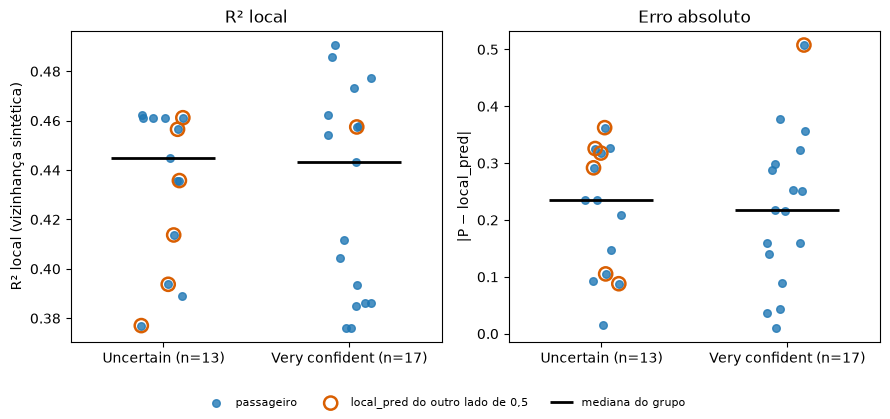

In [23]:
import matplotlib.pyplot as plt

jit = np.random.default_rng(0)                             # só para espalhar os pontos no desenho
groups = [('Uncertain (n=13)', fid13), ('Very confident (n=17)', fid_vc)]
fig, axes = plt.subplots(1, 2, figsize=(9, 4.2))
for ax, col, ylabel, title in zip(axes, ['Local R2', 'Abs error'], ['R² local (vizinhança sintética)', '|P − local_pred|'],
                                  ['R² local', 'Erro absoluto']):
    for x, (_, f) in enumerate(groups):
        xs = x + jit.uniform(-0.12, 0.12, len(f))
        flip = f['cruza 0,5'].to_numpy()
        ax.scatter(xs, f[col], s=30, color='#1f77b4', alpha=.8, label='passageiro' if x == 0 else None)
        ax.scatter(xs[flip], f[col].to_numpy()[flip], s=90, facecolors='none', edgecolors='#d95f02', linewidths=1.8,
                   label='local_pred do outro lado de 0,5' if x == 0 else None)
        ax.hlines(f[col].median(), x - 0.28, x + 0.28, color='black', lw=2, label='mediana do grupo' if x == 0 else None)
    ax.set_xticks([0, 1], [g[0] for g in groups])
    ax.set_xlim(-0.5, 1.5)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
fig.legend(*axes[0].get_legend_handles_labels(), loc='lower center', ncol=3, fontsize=8, frameon=False)
plt.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()

In [24]:
# Validação do complemento
assert len(ids13) == len(set(ids13)) == 13 and set(ids13) <= set(X_test.index) and not set(ids13) & set(X_train.index)
p_chk = pd.Series(model.predict_proba(X_test)[:, TARGET_CLASS], index=X_test.index)       # independente de predict_fn
assert ((p_chk.loc[ids13] >= 0.4) & (p_chk.loc[ids13] <= 0.6)).all()
assert set(ids13) == set(p_chk[(p_chk >= 0.4) & (p_chk <= 0.6)].index)                    # todos, sem omissões
assert not set(ids13) & set(ids20)                                                        # disjuntos dos 20

# configuração e resultados anteriores
assert LIME_CONFIG == dict(random_state=123, discretize_continuous=True, num_samples=5000, num_features=5)
assert summarize(run_lime(ids20[0]), ids20[0]) == results[ids20[0]]                      # mesmo caminho de código, mesmo resultado
assert fid.equals(fid_before) and list(fid.index) == ids20 == select_passengers()[0]
assert fid20.drop(columns='cruza 0,5').equals(fid)                                       # função nova reproduz a tabela original
assert all(set(e.local_exp) == {TARGET_CLASS} == set(e.intercept) for e in exps13.values())

# valores e estatísticas recalculados de forma independente
lp13 = np.array([float(np.ravel(exps13[p].local_pred)[0]) for p in ids13])
r13 = np.array([float(exps13[p].score) for p in ids13])
err13 = np.abs(p_chk.loc[ids13].to_numpy() - lp13)
assert np.array_equal(fid13['Local pred'], lp13) and np.array_equal(fid13['Local R2'], r13)
assert np.allclose(fid13['P(Survived)'], p_chk.loc[ids13], rtol=0, atol=1e-6) and np.allclose(fid13['Abs error'], err13, rtol=0, atol=1e-6)
assert (fid13['group'] == 'Uncertain').all() and len(fid_vc) == 17
for name, f in [('Uncertain (13, seleção intencional)', fid13), ('Very confident (17, amostra aleatória)', fid_vc)]:
    assert comp.loc['n', name] == len(f)
    assert np.isclose(comp.loc['R2 mediana', name], np.median(f['Local R2'])) and np.isclose(comp.loc['erro mediano', name], np.median(f['Abs error']))
    assert comp.loc['R2 min', name] == f['Local R2'].min() and comp.loc['erro max', name] == f['Abs error'].max()
side = ((all33['P(Survived)'] >= 0.5) != (all33['Local pred'] >= 0.5)).to_numpy()
assert len(all33) == 33 and (all33['cruza 0,5'].to_numpy() == side).all() and len(cross) == side.sum()
print('Validação da Atividade 2b: OK')

Validação da Atividade 2b: OK


#### Respostas atualizadas às perguntas 2 e 3 (Atividade 2)

**Duas amostras diferentes.** (a) 20 passageiros sorteados ao acaso, em que 17 têm probabilidade extrema (`Very confident`) e 0 estão em 0,4 ≤ P ≤ 0,6; (b) os 13 passageiros de teste com 0,4 ≤ P ≤ 0,6, escolhidos intencionalmente pela probabilidade prevista (a faixa inteira, não uma amostra). Nenhuma das duas é representativa de "todos os passageiros", e a comparação é descritiva, com n = 13 e n = 17.

**2. A fidelidade é menor perto de 0,5 ou perto de 0 e 1?** Pelas duas métricas, **não há diferença clara**. R² local mediano: 0,445 (incertos; 0,377–0,462) contra 0,443 (`Very confident`; 0,376–0,491). Erro absoluto mediano: 0,235 (0,015–0,362) contra 0,218 (0,011–0,508). Os intervalos sobrepõem-se quase por completo, o erro mediano é ligeiramente maior nos incertos (0,017) e o maior erro individual está no grupo `Very confident` (1095, 0,508), diferenças pequenas face à dispersão e ao n. A fidelidade é apenas moderada nos dois grupos.

**3. O LIME explica pior o modelo quando está indeciso ou muito confiante?** Nestas amostras, nenhum dos dois de forma consistente: o R² e o erro são semelhantes. O que muda é a **consequência para a decisão**: em 6 dos 13 incertos a local prediction fica do outro lado de 0,5 face a P (534, 442, 225, 748, 390, 152), contra 1 dos 17 com probabilidade extrema (1095) e 0 dos 3 intermédios. Isto é em parte mecânico: perto de 0,5 um erro de 0,1–0,3 chega para mudar de lado, enquanto com P ≈ 0,01 ou 0,99 é preciso um erro de ~0,5. Por isso, o substituto linear discorda com mais frequência da **classe** prevista nos casos incertos, sem que o ajuste (R², erro) seja claramente pior. Em 10 dos 13 incertos a local prediction fica abaixo de P.

**Não confundir:** a fidelidade mede a aproximação ao *modelo*, não a correção face ao real. 241 e 46 têm o mesmo perfil, a mesma P (0,4195) e a mesma explicação, mas realidades diferentes (sobreviveu / não sobreviveu); nenhuma métrica de fidelidade distingue os dois casos.

**Limites.** Seleção intencional (não aleatória) dos 13 e aleatória dos 20; amostras pequenas; sem testes de significância (não fariam sentido sobre uma seleção não aleatória); R² medido na vizinhança sintética, que depende da semente; não se mediu variabilidade entre sementes (Atividade 3). Não há prova de uma relação geral entre confiança e fidelidade, nem a ausência dela.

#### Fidelidade por subgrupo `Sex × Pclass` (exploratório)

Reutiliza os 33 passageiros já explicados, com as mesmas explicações (`LIME_CONFIG`, semente 123): os 20 sorteados da Atividade 1 e os 13 selecionados na 2b por 0,4 ≤ P ≤ 0,6. Os 33 **não** são uma amostra aleatória homogénea, por isso a tabela separa as duas origens. Os grupos têm 1 a 6 passageiros, o que só permite descrever; não se fazem testes de significância.


In [25]:
# Erro absoluto por Sex × Pclass nos 33 passageiros já explicados (sem novas explicações LIME)
sub = all33.join(X_test[['Sex', 'Pclass']])
sub['Sex'] = sub['Sex'].map({0.0: 'female', 1.0: 'male'})
sub['Pclass'] = sub['Pclass'].astype(int)
span = lambda s: f'{s.min():.3f}–{s.max():.3f}'
sub_tab = sub.groupby(['Sex', 'Pclass', 'amostra']).agg(
    n=('Abs error', 'size'), erro_mediano=('Abs error', 'median'), erro_max=('Abs error', 'max'),
    R2_mediana=('Local R2', 'median'), P_min_max=('P(Survived)', span), local_pred_min_max=('Local pred', span))
print('Erro absoluto |P − local_pred| por Sex × Pclass e origem (33 passageiros; as duas origens não formam uma amostra homogénea)')
display(sub_tab.round(3))

top5_20 = fid['Abs error'].nlargest(5)
is_f3 = (sub['Sex'] == 'female') & (sub['Pclass'] == 3)
f3 = sorted(sub.index[is_f3 & (sub['amostra'] == 'aleatória (20)')])
print('5 maiores erros dos 20 sorteados:', ', '.join(f"{p} ({sub.loc[p, 'Sex']}, {sub.loc[p, 'Pclass']}.ª, {e:.3f})" for p, e in top5_20.items()))
print('Mulheres de 3.ª classe: %s entre os 20 sorteados | %d entre os 13 da faixa 0,4–0,6' % (f3, (is_f3 & (sub['amostra'] == 'incertos (13)')).sum()))
for p in f3:
    print(f"  {p}: P={results[p]['p_model']:.3f} local={results[p]['local_pred']:+.3f} |",
          ', '.join(f'{c} ({w:+.3f})' for c, w in results[p]['rules']))

# validação: recálculo independente a partir dos resultados LIME já existentes
res33 = {**results, **results13}
assert len(sub) == 33 and sub.index.is_unique and set(sub.index) == set(ids20) | set(ids13) and sub_tab['n'].sum() == 33
assert not sub[['Sex', 'Pclass']].isna().any().any()
for (sx, pc, am), r in sub_tab.iterrows():
    pool = ids20 if am == 'aleatória (20)' else ids13
    g_ids = [p for p in pool if X_test.loc[p, 'Sex'] == (sx == 'male') and X_test.loc[p, 'Pclass'] == pc]
    errs = [abs(res33[p]['p_model'] - res33[p]['local_pred']) for p in g_ids]
    assert r['n'] == len(g_ids) and np.isclose(r['erro_mediano'], np.median(errs)) and np.isclose(r['erro_max'], max(errs))
    assert np.isclose(r['R2_mediana'], np.median([res33[p]['r2'] for p in g_ids]))
assert f3 == [1095, 1147, 1190, 1224] and set(f3) <= set(top5_20.index)      # observação da revisão, confirmada nos dados
print('Validação do subgrupo: OK')


Erro absoluto |P − local_pred| por Sex × Pclass e origem (33 passageiros; as duas origens não formam uma amostra homogénea)


n  erro_mediano  erro_max  R2_mediana    P_min_max local_pred_min_max
Sex    Pclass amostra                                                                              
female 1      aleatória (20)  1         0.037     0.037       0.443  1.000–1.000        0.963–0.963
       2      aleatória (20)  5         0.218     0.328       0.393  0.898–0.995        0.570–0.777
              incertos (13)   2         0.203     0.318       0.404  0.457–0.481        0.569–0.775
       3      aleatória (20)  4         0.367     0.508       0.475  0.001–0.993        0.356–0.670
male   1      aleatória (20)  2         0.083     0.157       0.448  0.105–0.277        0.262–0.286
              incertos (13)   6         0.192     0.326       0.461  0.420–0.557        0.184–0.452
       2      aleatória (20)  4         0.252     0.299       0.381  0.002–0.005        0.144–0.301
              incertos (13)   2         0.193     0.292       0.383  0.454–0.549        0.257–0.361
       3      aleatória (20)  4         0.066     0.160       0.460  0.000–0.016       -0.042–0.167
              incertos (13)   3         0.326     0.362       0.457  0.407–0.541        0.081–0.273

5 maiores erros dos 20 sorteados: 1095 (female, 3.ª, 0.508), 1190 (female, 3.ª, 0.377), 1147 (female, 3.ª, 0.356), 584 (female, 2.ª, 0.328), 1224 (female, 3.ª, 0.323)
Mulheres de 3.ª classe: [1095, 1147, 1190, 1224] entre os 20 sorteados | 0 entre os 13 da faixa 0,4–0,6
  1095: P=0.075 local=+0.583 | Sex=female (+0.496), Pclass=3 (-0.251), Embarked_C=0 (-0.110), Embarked_Q=0 (+0.070), SibSp <= 0.00 (+0.069)
  1147: P=0.001 local=+0.356 | Sex=female (+0.490), Pclass=3 (-0.260), Age > 38.00 (-0.159), Embarked_C=0 (-0.107), 15.02 < Fare <= 34.38 (-0.098)
  1190: P=0.934 local=+0.557 | Sex=female (+0.488), Pclass=3 (-0.263), Age <= 21.00 (+0.113), Embarked_C=0 (-0.112), 15.02 < Fare <= 34.38 (-0.091)
  1224: P=0.993 local=+0.670 | Sex=female (+0.500), Pclass=3 (-0.249), Fare <= 8.05 (+0.118), Embarked_C=0 (-0.109), SibSp <= 0.00 (+0.069)
Validação do subgrupo: OK


**Observado.** A observação da revisão confirma-se: as quatro mulheres de 3.ª classe do sorteio (1095, 1147, 1190, 1224) estão entre os cinco maiores erros dos 20 (o quinto é o 584, mulher de 2.ª classe). Nesse subgrupo o erro mediano é 0,367 (máximo 0,508), o mais alto de todas as combinações. O R² local mediano (0,475) também é o mais alto, por isso o R² não assinalaria estes casos. O XGBoost dá a estas quatro passageiras probabilidades nos dois extremos (0,001 a 0,993), mas as *local predictions* ficam entre 0,36 e 0,67. As quatro explicações têm praticamente os mesmos coeficientes de `Sex=female` (+0,49 a +0,50) e `Pclass=3` (−0,25 a −0,26) e só diferem nas condições secundárias. Nos outros perfis a comparação é confundida pela origem: nos homens de 3.ª classe, por exemplo, a mediana é 0,066 no sorteio (n = 4, todos com P ≤ 0,02) e 0,326 na faixa 0,4–0,6 (n = 3).

**Interpretação (hipótese, não demonstrada).** A concentração é coerente com o complemento de localidade da Atividade 7. Se o coeficiente de cada condição varia pouco entre passageiros, um perfil em que o modelo dá probabilidades muito diferentes a passageiros com as mesmas condições principais gera necessariamente erros grandes nalguns deles. Não se testou se as interações ou a não linearidade do XGBoost são a causa.

**Limites.** Só há quatro mulheres de 3.ª classe, todas do sorteio, e nenhuma entre os 13 da faixa 0,4–0,6. A composição dos 33 resulta de dois critérios de seleção diferentes. Não se conclui que o padrão se mantenha no conjunto de teste, que o LIME falhe sistematicamente neste perfil, nem que exista um problema de fairness, que não foi avaliado.


## Atividade 3 — Check Stability

**Passageiro:** `PassengerId = 1095`, o de maior erro absoluto |P − local_pred| na Atividade 2 (critério anterior a esta experiência). Só se estuda **este** passageiro; nada aqui se generaliza a outros.

**Desenho:** `num_samples ∈ {500, 1000, 5000}` × 10 sementes `[123, 1, 2, ..., 9]` = 30 explicações. O que não é estudado fica igual às atividades anteriores (`discretize_continuous=True`, `num_features=5`, `labels=(1,)`, mesmo modelo e dados). Cada execução usa um **explainer novo** (`build_explainer(seed, True)`), com o estado aleatório reiniciado.

**Tempo:** `time.perf_counter()` à volta de `explain_passenger` apenas (a criação do explainer fica de fora, tal como treino, dados e gráficos); há uma explicação de aquecimento não medida e as execuções alternam sementes e tamanhos para não enviesar por deriva do sistema. Os tempos dependem da máquina e do momento.

**Agregação:** por identificador estruturado de feature (índice LIME → `FEATURES`). Peso médio, mínimo e máximo contam só as execuções em que a feature foi **selecionada**: uma feature fora das 5 não tem peso zero, não foi observada.

In [26]:
import time
from itertools import combinations

STAB_ID = 1095
STAB_SAMPLES = [500, 1000, 5000]
STAB_SEEDS = [123, 1, 2, 3, 4, 5, 6, 7, 8, 9]
assert STAB_ID == int(fid['Abs error'].idxmax())            # critério da Atividade 2
snapshot = [d.copy() for d in (fid, fid13, table_a, table_b, freq3)]   # para verificar no fim que nada anterior mudou

explain_passenger(build_explainer(0, True), STAB_ID, 500, LIME_CONFIG['num_features'])   # aquecimento, não medido

stab_exps, run_rows, weight_rows = {}, [], []
for seed in STAB_SEEDS:
    for ns in STAB_SAMPLES:
        explainer = build_explainer(seed, LIME_CONFIG['discretize_continuous'])   # estado aleatório novo
        t0 = time.perf_counter()
        exp = explain_passenger(explainer, STAB_ID, ns, LIME_CONFIG['num_features'])
        seconds = time.perf_counter() - t0
        s = summarize(exp, STAB_ID)
        stab_exps[(ns, seed)] = exp
        run_rows.append(dict(num_samples=ns, seed=seed, p_model=s['p_model'], local_pred=s['local_pred'], r2=s['r2'],
                             abs_error=abs(s['p_model'] - s['local_pred']), intercept=s['intercept'], seconds=seconds,
                             features=frozenset(f for f, _ in s['weights'])))
        ranked = sorted(zip(s['weights'], s['rules']), key=lambda t: -abs(t[0][1]))
        for rank, ((feat, w), (cond, _)) in enumerate(ranked, 1):
            weight_rows.append(dict(num_samples=ns, seed=seed, rank=rank, feature=feat, condition=cond, weight=w))

runs = pd.DataFrame(run_rows)
wts = pd.DataFrame(weight_rows)
print(len(runs), 'explicações |', 'P(Survived) do passageiro', STAB_ID, '=', round(runs['p_model'].iloc[0], 6))
# a configuração da Atividade 1/2 (5000 amostras, semente 123) é reproduzida exatamente
assert summarize(stab_exps[(5000, 123)], STAB_ID) == results[STAB_ID]
print('(5000, semente 123) reproduz a explicação anterior do passageiro', STAB_ID)

30 explicações | P(Survived) do passageiro 1095 = 0.075315
(5000, semente 123) reproduz a explicação anterior do passageiro 1095


### Seleção e pesos das features, por `num_samples`

In [27]:
from IPython.display import display

N_RUNS = len(STAB_SEEDS)
g = wts.groupby(['num_samples', 'feature'])
stat = g['weight'].agg(n_sel='size', peso_medio='mean', peso_min='min', peso_max='max', desvio='std')
stat['amplitude'] = stat['peso_max'] - stat['peso_min']
stat['n +'] = g['weight'].apply(lambda s: int((s > 0).sum()))
stat['n -'] = g['weight'].apply(lambda s: int((s < 0).sum()))
stat['condições'] = g['condition'].agg(lambda s: ' | '.join(sorted(set(s))))
stat = stat.reindex(pd.MultiIndex.from_product([STAB_SAMPLES, FEATURES], names=['num_samples', 'feature']))
stat['n_sel'] = stat['n_sel'].fillna(0).astype(int)
stat['freq'] = stat['n_sel'] / N_RUNS

shown = stat[stat.groupby('feature')['n_sel'].transform('sum') > 0]
cols = ['n_sel', 'freq', 'peso_medio', 'peso_min', 'peso_max', 'amplitude', 'desvio', 'n +', 'n -', 'condições']
tab = (shown[cols].reset_index().sort_values(['num_samples', 'n_sel', 'feature'], ascending=[True, False, True])
       .set_index(['num_samples', 'feature']))
print('— = feature não selecionada nessa configuração (sem peso observado; não é peso 0)')
display(tab.round(4).astype(object).where(tab.notna(), '—'))
print('Features nunca selecionadas em nenhuma configuração:', [f for f in FEATURES if stat.xs(f, level='feature')['n_sel'].sum() == 0])

signs = stat.dropna(subset=['peso_medio'])
flips = signs[(signs['n +'] > 0) & (signs['n -'] > 0)]
print('Mudanças de sinal (feature com pesos + e − na mesma configuração):', flips.index.tolist() if len(flips) else 'nenhuma')
allw = wts.groupby('feature')['weight'].agg(pos=lambda s: int((s > 0).sum()), neg=lambda s: int((s < 0).sum()))
print('Mudanças de sinal nas 30 execuções:', allw[(allw.pos > 0) & (allw.neg > 0)].index.tolist() or 'nenhuma')

— = feature não selecionada nessa configuração (sem peso observado; não é peso 0)


n_sel freq peso_medio peso_min peso_max amplitude  desvio   n +   n -             condições
num_samples feature                                                                                               
500         Embarked_C    10  1.0    -0.1123  -0.1887  -0.0624    0.1262  0.0416   0.0  10.0          Embarked_C=0
            Pclass        10  1.0    -0.2472  -0.2859  -0.2148    0.0711  0.0238   0.0  10.0              Pclass=3
            Sex           10  1.0     0.4857   0.4409   0.5347    0.0938  0.0313  10.0   0.0            Sex=female
            SibSp         10  1.0     0.0631   0.0447   0.0991    0.0544  0.0156  10.0   0.0         SibSp <= 0.00
            Embarked_Q     3  0.3     0.1132   0.0831   0.1501    0.0669   0.034   3.0   0.0          Embarked_Q=0
            Embarked_S     3  0.3    -0.0388  -0.0748   0.0218    0.0966  0.0528   1.0   2.0          Embarked_S=1
            Fare           2  0.2     0.0227  -0.0447   0.0901    0.1347  0.0953   1.0   1.0  8.05 < Fare <= 15.02
            Parch          2  0.2    -0.0775  -0.0896  -0.0654    0.0242  0.0171   0.0   2.0         Parch <= 0.00
            Age            0  0.0          —        —        —         —       —     —     —                     —
1000        Embarked_C    10  1.0    -0.1156  -0.1648  -0.0756    0.0892  0.0308   0.0  10.0          Embarked_C=0
            Pclass        10  1.0    -0.2614  -0.2772   -0.228    0.0492   0.018   0.0  10.0              Pclass=3
            Sex           10  1.0      0.483   0.4523   0.5097    0.0573  0.0187  10.0   0.0            Sex=female
            SibSp          9  0.9     0.0683    0.035    0.095      0.06  0.0184   9.0   0.0         SibSp <= 0.00
            Parch          6  0.6    -0.0524  -0.1045  -0.0233    0.0812  0.0278   0.0   6.0         Parch <= 0.00
            Fare           2  0.2      0.056   0.0479   0.0641    0.0162  0.0114   2.0   0.0  8.05 < Fare <= 15.02
            Age            1  0.1     0.0644   0.0644   0.0644       0.0       —   1.0   0.0  28.00 < Age <= 38.00
            Embarked_Q     1  0.1     0.1331   0.1331   0.1331       0.0       —   1.0   0.0          Embarked_Q=0
            Embarked_S     1  0.1    -0.0436  -0.0436  -0.0436       0.0       —   0.0   1.0          Embarked_S=1
5000        Embarked_C    10  1.0    -0.1113  -0.1273  -0.0928    0.0345  0.0113   0.0  10.0          Embarked_C=0
            Pclass        10  1.0    -0.2521  -0.2676  -0.2403    0.0273  0.0089   0.0  10.0              Pclass=3
            Sex           10  1.0     0.4891   0.4637   0.5079    0.0442  0.0131  10.0   0.0            Sex=female
            SibSp         10  1.0      0.074   0.0681   0.0821     0.014  0.0042  10.0   0.0         SibSp <= 0.00
            Embarked_Q     6  0.6      0.095   0.0695   0.1221    0.0526  0.0205   6.0   0.0          Embarked_Q=0
            Parch          4  0.4    -0.0498  -0.0527  -0.0442    0.0085   0.004   0.0   4.0         Parch <= 0.00
            Age            0  0.0          —        —        —         —       —     —     —                     —
            Embarked_S     0  0.0          —        —        —         —       —     —     —                     —
            Fare           0  0.0          —        —        —         —       —     —     —                     —

Features nunca selecionadas em nenhuma configuração: []
Mudanças de sinal (feature com pesos + e − na mesma configuração): [(500, 'Fare'), (500, 'Embarked_S')]
Mudanças de sinal nas 30 execuções: ['Embarked_S', 'Fare']


### Estabilidade, custo e fidelidade por `num_samples`

- **Consistência da seleção** = índice de Jaccard médio entre os 45 pares de conjuntos de 5 features das 10 execuções (1 = sempre o mesmo conjunto).
- **Variabilidade dos pesos** = desvio-padrão e amplitude (máx − mín) dos pesos das features selecionadas em pelo menos 5 das 10 execuções (limiar só descritivo). É uma propriedade diferente da consistência da seleção.
- **Custo** = tempo de `explain_instance`; "relativo" = mediana / mediana de 500 amostras.

In [28]:
def mean_jaccard(sets):
    j = [len(a & b) / len(a | b) for a, b in combinations(sets, 2)]
    return float(np.mean(j)), min(j), len(j)


rows = []
for ns in STAB_SAMPLES:
    r, st = runs[runs['num_samples'] == ns], stat.loc[ns]
    jm, jmin, npairs = mean_jaccard(list(r['features']))
    freq_feats = st[st['n_sel'] >= 5]
    rows.append({'num_samples': ns, 'Jaccard médio': jm, 'Jaccard mín': jmin, 'pares': npairs,
                 'conjuntos distintos': r['features'].nunique(),
                 'sempre (10/10)': int((st['n_sel'] == N_RUNS).sum()),
                 'ocasionais (1-9)': int(((st['n_sel'] > 0) & (st['n_sel'] < N_RUNS)).sum()),
                 'desvio peso (média freq.)': freq_feats['desvio'].mean(),
                 'amplitude peso (mediana freq.)': freq_feats['amplitude'].median(),
                 'amplitude peso (máx freq.)': freq_feats['amplitude'].max(),
                 'tempo mediano (s)': r['seconds'].median(), 'tempo mín (s)': r['seconds'].min(), 'tempo máx (s)': r['seconds'].max()})
stab = pd.DataFrame(rows).set_index('num_samples')
stab['tempo relativo (×500)'] = stab['tempo mediano (s)'] / stab.loc[500, 'tempo mediano (s)']
stab['variação do tempo vs 500'] = stab['tempo relativo (×500)'] - 1
print('Estabilidade e custo')
display(stab.T.round(4))

fidr = runs.groupby('num_samples').agg(
    R2_media=('r2', 'mean'), R2_min=('r2', 'min'), R2_max=('r2', 'max'),
    erro_medio=('abs_error', 'mean'), erro_min=('abs_error', 'min'), erro_max=('abs_error', 'max'),
    local_pred_media=('local_pred', 'mean'), local_pred_min=('local_pred', 'min'), local_pred_max=('local_pred', 'max'))
print('Fidelidade nas 10 execuções de cada configuração (P(Survived) = %.6f em todas)' % runs['p_model'].iloc[0])
display(fidr.round(4))

Estabilidade e custo


num_samples,500,1000,5000
Jaccard médio,0.7259,0.7249,0.8222
Jaccard mín,0.6667,0.4286,0.6667
pares,45.0000,45.0000,45.0000
conjuntos distintos,4.0000,6.0000,2.0000
sempre (10/10),4.0000,3.0000,4.0000
ocasionais (1-9),4.0000,6.0000,2.0000
desvio peso (média freq.),0.0281,0.0227,0.0116
amplitude peso (mediana freq.),0.0825,0.0600,0.0345
amplitude peso (máx freq.),0.1262,0.0892,0.0526
tempo mediano (s),0.0801,0.0820,0.0979


Fidelidade nas 10 execuções de cada configuração (P(Survived) = 0.075315 em todas)


,R2_media,R2_min,R2_max,erro_medio,erro_min,erro_max,local_pred_media,local_pred_min,local_pred_max
num_samples,,,,,,,,,
500,0.4666,0.4177,0.5243,0.4812,0.4184,0.5251,0.5565,0.4938,0.6005
1000,0.4657,0.4309,0.4970,0.4942,0.4471,0.5153,0.5695,0.5225,0.5906
5000,0.4595,0.4333,0.4822,0.4918,0.4512,0.5198,0.5671,0.5266,0.5951


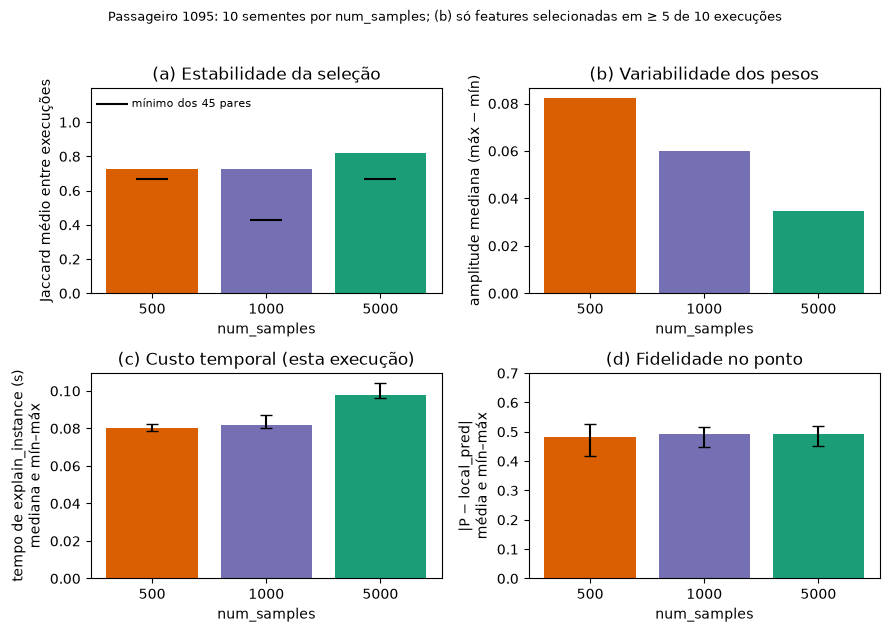

In [29]:
import matplotlib.pyplot as plt

COL = {500: '#d95f02', 1000: '#7570b3', 5000: '#1b9e77'}
cats, colors = [str(ns) for ns in STAB_SAMPLES], [COL[ns] for ns in STAB_SAMPLES]
fig, ((a1, a2), (a3, a4)) = plt.subplots(2, 2, figsize=(9, 6.4))

a1.bar(cats, stab['Jaccard médio'], color=colors)
a1.scatter(cats, stab['Jaccard mín'], marker='_', s=500, color='black', zorder=3, label='mínimo dos 45 pares')
a1.set_ylim(0, 1.2)
a1.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
a1.set_ylabel('Jaccard médio entre execuções')
a1.set_title('(a) Estabilidade da seleção')
a1.legend(fontsize=8, loc='upper left', frameon=False)

a2.bar(cats, stab['amplitude peso (mediana freq.)'], color=colors)
a2.set_ylabel('amplitude mediana (máx − mín)')
a2.set_title('(b) Variabilidade dos pesos')

t_med = stab['tempo mediano (s)']
a3.bar(cats, t_med, yerr=[t_med - stab['tempo mín (s)'], stab['tempo máx (s)'] - t_med], capsize=4, color=colors)
a3.set_ylabel('tempo de explain_instance (s)\nmediana e mín–máx')
a3.set_title('(c) Custo temporal (esta execução)')

e_med = fidr['erro_medio']
a4.bar(cats, e_med, yerr=[e_med - fidr['erro_min'], fidr['erro_max'] - e_med], capsize=4, color=colors)
a4.set_ylim(0, 0.7)
a4.set_ylabel('|P − local_pred|\nmédia e mín–máx')
a4.set_title('(d) Fidelidade no ponto')

for ax in (a1, a2, a3, a4):
    ax.set_xlabel('num_samples')
fig.suptitle(f'Passageiro {STAB_ID}: 10 sementes por num_samples; (b) só features selecionadas em ≥ 5 de 10 execuções', fontsize=9)
plt.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

In [30]:
# Validação da Atividade 3
from collections import Counter, defaultdict

assert len(runs) == len(stab_exps) == len(STAB_SAMPLES) * len(STAB_SEEDS) == 30
assert all(sorted(runs[runs['num_samples'] == ns]['seed']) == sorted(STAB_SEEDS) and runs[runs['num_samples'] == ns]['seed'].nunique() == 10
           for ns in STAB_SAMPLES)
assert STAB_ID in X_test.index and set(wts['seed']) == set(STAB_SEEDS)
assert all(np.array_equal(np.asarray(e.predict_proba), predict_fn(X_test.loc[[STAB_ID]].values)[0]) for e in stab_exps.values())
assert runs['p_model'].nunique() == 1 and np.isclose(runs['p_model'].iloc[0], fid.loc[STAB_ID, 'P(Survived)'], rtol=0, atol=1e-12)
assert np.array_equal(predict_fn(X_test.values)[:, TARGET_CLASS], p_test.to_numpy())          # modelo inalterado
assert all(set(e.local_exp) == {TARGET_CLASS} for e in stab_exps.values())

# frequências, médias e amplitudes recalculadas diretamente dos objetos LIME
by = defaultdict(list)
for (ns, seed), e in stab_exps.items():
    assert len(e.local_exp[TARGET_CLASS]) == LIME_CONFIG['num_features'] == len({i for i, _ in e.local_exp[TARGET_CLASS]})
    for i, w in e.local_exp[TARGET_CLASS]:
        by[(ns, FEATURES[i])].append(w)
for ns in STAB_SAMPLES:
    assert sum(len(v) for (n, _), v in by.items() if n == ns) == 5 * N_RUNS == stat.loc[ns, 'n_sel'].sum()
for (ns, f), v in by.items():
    s = stat.loc[(ns, f)]
    assert s['n_sel'] == len(v) and np.isclose(s['freq'], len(v) / 10)
    assert np.isclose(s['peso_medio'], np.mean(v)) and s['peso_min'] == min(v) and s['peso_max'] == max(v)
    assert s['n +'] == sum(x > 0 for x in v) and s['n -'] == sum(x < 0 for x in v) and s['n +'] + s['n -'] == len(v)
assert (stat.loc[stat['n_sel'] == 0, ['peso_medio', 'peso_min', 'peso_max']].isna()).all().all()   # não selecionada != peso 0

# Jaccard recalculado e dentro de [0, 1]; tempos válidos
for ns in STAB_SAMPLES:
    sets = [frozenset(FEATURES[i] for i, _ in stab_exps[(ns, sd)].local_exp[TARGET_CLASS]) for sd in STAB_SEEDS]
    jj = [len(a & b) / len(a | b) for a, b in combinations(sets, 2)]
    assert len(jj) == 45 and 0 <= min(jj) <= max(jj) <= 1 and np.isclose(stab.loc[ns, 'Jaccard médio'], np.mean(jj))
assert np.isfinite(runs['seconds']).all() and (runs['seconds'] > 0).all()
assert (stab['tempo mín (s)'] <= stab['tempo mediano (s)']).all() and (stab['tempo mediano (s)'] <= stab['tempo máx (s)']).all()

# atividades anteriores inalteradas
assert all(a.equals(b) for a, b in zip(snapshot, (fid, fid13, table_a, table_b, freq3)))
assert results[STAB_ID] == summarize(run_lime(STAB_ID), STAB_ID) and list(fid.index) == ids20 == select_passengers()[0]
print('Validação da Atividade 3: OK')

Validação da Atividade 3: OK


### Observações (Atividade 3, passageiro 1095)

Só um passageiro e 10 sementes por configuração: os resultados descrevem este caso e são descritivos.

**1. As mesmas features são selecionadas sempre?** Só em parte. `Sex`, `Pclass` e `Embarked_C` são selecionadas em 10/10 execuções nas três configurações, e `SibSp` em 10/10 com 500 e 5000 amostras (9/10 com 1000). As restantes posições do top 5 variam: com 500 amostras entram `Embarked_Q` (3/10), `Embarked_S` (3/10), `Fare` (2/10) e `Parch` (2/10); com 1000, `Parch` (6/10), `Fare` (2/10), `Age`, `Embarked_Q` e `Embarked_S` (1/10 cada); com 5000, `Embarked_Q` (6/10) e `Parch` (4/10). Conjuntos distintos de 5 features: 4, 6 e 2; Jaccard médio 0,726, 0,725 e 0,822. A seleção é mais consistente com 5000, mas **não monotonicamente**: 500 e 1000 são equivalentes (1000 tem até o par mais dissemelhante, Jaccard mínimo 0,43).

**2. Pesos e sinais mudam?** Os pesos mudam de semente para semente, mas as features sempre selecionadas mantêm o sinal e a ordem de grandeza em todas as execuções: `Sex=female` ≈ +0,49 (+0,44 a +0,53), `Pclass=3` ≈ −0,25, `Embarked_C=0` ≈ −0,11, `SibSp<=0` ≈ +0,07. As únicas mudanças de sinal ocorrem em features selecionadas ocasionalmente, com 500 amostras: `Embarked_S` (1 positivo, 2 negativos em 3 seleções; pesos de −0,07 a +0,02) e `Fare` (1 positivo, 1 negativo em 2 seleções). Com 2 ou 3 observações isto indica pesos próximos de zero, não uma estimativa de sinal. A variabilidade dos pesos das features selecionadas em pelo menos 5 execuções diminui com `num_samples`: desvio médio 0,028, 0,023 e 0,012, amplitude mediana 0,083, 0,060 e 0,035.

**3. Mais amostras tornam a explicação mais estável?** Neste passageiro, sim para os pesos (amplitudes e desvios caem nas três configurações) e, com 5000, também para a seleção (Jaccard 0,82, 2 conjuntos distintos); mas a seleção não melhora de 500 para 1000. Nenhuma configuração é totalmente estável: com 5000 ainda varia o 5.º elemento do top 5 (`Embarked_Q` 6/10, `Parch` 4/10).

**4. Custo.** O tempo de `explain_instance` cresce pouco com `num_samples`: na execução registada (ver tabela e painel (c) da figura), 5000 amostras custaram algumas dezenas de por cento mais do que 500 (poucas centésimas de segundo em termos absolutos; o valor exato varia entre execuções), e 500 e 1000 pouco se distinguem. Por isso, neste caso, o ganho de estabilidade com 5000 amostras custa pouco. Os tempos absolutos dependem da máquina, da carga e do momento e podem variar bastante entre execuções; só o sentido e a ordem de grandeza do custo relativo são informativos, e não se extrapolam para outros modelos, máquinas ou tamanhos.

**Estabilidade ≠ fidelidade.** P(Survived) = 0,0753 em todas as execuções. O R² local médio é 0,467, 0,466 e 0,460 (intervalos 0,42–0,52, 0,43–0,50, 0,43–0,48) e o erro absoluto médio 0,481, 0,494 e 0,492: mais amostras estreitam os intervalos mas **não melhoram** R² nem erro. A local prediction fica entre 0,49 e 0,60 em todas as execuções (mínimo 0,494 com 500; ≥ 0,52 com 1000 e 5000), ao passo que o modelo dá 0,075, ou seja, a explicação do 1095 é estavelmente desalinhada do modelo: com 5000 amostras é mais reprodutível, mas continua a descrever um substituto que discorda do XGBoost.

**Limites.** Um passageiro (escolhido por ter o maior erro na Atividade 2, logo um caso difícil), 10 sementes por configuração, tempos de uma só máquina, `discretize_continuous=True` e `num_features=5` fixos. O limiar de "frequentemente selecionada" (≥ 5/10) é só descritivo.

## Atividade 4 — Change the Representation

**Passageiro:** `PassengerId = 1095`, como na Atividade 3. **Só muda `discretize_continuous`** (`True` vs `False`); modelo, dados, `random_state=123`, `num_samples=5000`, `labels=(1,)` e features categóricas são os mesmos. `num_features = 9` (todas as features) é específico desta atividade, para que `Age` e `Fare` apareçam sempre; `LIME_CONFIG` não é alterado.

**O que o LIME ajusta em cada caso** (confirmado no código do `lime_tabular`):

- `discretize_continuous=True`: **todas** as features entram na regressão como indicadores binários (1 = o valor amostrado cai no mesmo intervalo/categoria que o da instância; a instância tem sempre 1). O coeficiente de `Age` ou `Fare` refere-se a **um intervalo**, não a uma unidade de idade ou de tarifa.
- `discretize_continuous=False`: as categóricas continuam binárias, mas as contínuas entram **padronizadas**, `z = (valor − média) / escala`, com `explainer.scaler.mean_` e `scale_`. O coeficiente é uma **inclinação por 1 desvio-padrão** e o contributo para a instância é `coeficiente × z`.
- A previsão local reconstrói-se como `intercept + Σ coeficiente_i × representação_i` (representação interna de cada caso, sem misturar as duas).
- Sem discretização, as contínuas são amostradas de uma Normal(média, DP) **do treino** (não à volta da instância). A vizinhança muda além da escala dos coeficientes, por isso as diferenças entre as duas explicações não vêm só da escala.

In [31]:
A4_ID = STAB_ID                                    # 1095
A4_FEATURES = len(FEATURES)                        # 9, só nesta atividade
snapshot4 = [d.copy() for d in (fid, fid13, table_a, table_b, freq3, runs, stat, stab)]

rep = {}                                           # discretize_continuous -> (explainer, explicação)
for flag in (True, False):
    explainer = build_explainer(LIME_CONFIG['random_state'], flag)       # explainer novo por explicação
    rep[flag] = (explainer, explain_passenger(explainer, A4_ID, LIME_CONFIG['num_samples'], A4_FEATURES))
x1095 = X_test.loc[A4_ID].values
print('Instância', A4_ID, dict(zip(FEATURES, x1095)))


def internal_representation(explainer, x):
    """Instância na representação que o LIME usa na regressão: indicador 1 nas features categóricas/discretizadas,
    valor padronizado (com a média e a escala do explainer) nas contínuas sem discretização."""
    z = np.array(x, dtype=float)
    z[list(explainer.categorical_features)] = 1.0
    return (z - explainer.scaler.mean_) / explainer.scaler.scale_


def representation_table(flag):
    explainer, exp = rep[flag]
    z = internal_representation(explainer, x1095)
    rows = []
    for (i, coef), (cond, w_rule) in zip(exp.local_exp[TARGET_CLASS], exp.as_list(label=TARGET_CLASS)):
        assert np.isclose(coef, w_rule, rtol=0, atol=1e-12) and FEATURES[i] in cond
        rows.append(dict(feature=FEATURES[i], condição=cond, valor=x1095[i], média=explainer.scaler.mean_[i],
                         escala=explainer.scaler.scale_[i], z=z[i], coeficiente=coef, contributo=coef * z[i]))
    return pd.DataFrame(rows).set_index('feature').loc[FEATURES]


tabs = {flag: representation_table(flag) for flag in (True, False)}
for flag in (True, False):
    e = rep[flag][1]
    cols = ['condição', 'valor', 'z', 'coeficiente', 'contributo'] if flag else ['condição', 'valor', 'média', 'escala', 'z', 'coeficiente', 'contributo']
    print(f'discretize_continuous={flag}: P(Survived)={e.predict_proba[TARGET_CLASS]:.6f} | intercept={e.intercept[TARGET_CLASS]:+.4f} | '
          f'local_pred={float(np.ravel(e.local_pred)[0]):+.4f} | R²={e.score:.4f}')
    display(tabs[flag][cols].round(4))

Instância 1095 {'Pclass': np.float64(3.0), 'Sex': np.float64(0.0), 'Age': np.float64(31.0), 'SibSp': np.float64(0.0), 'Parch': np.float64(0.0), 'Fare': np.float64(8.6833), 'Embarked_C': np.float64(0.0), 'Embarked_Q': np.float64(0.0), 'Embarked_S': np.float64(1.0)}
discretize_continuous=True: P(Survived)=0.075315 | intercept=+0.3157 | local_pred=+0.6090 | R²=0.4596


,condição,valor,z,coeficiente,contributo
feature,,,,,
Pclass,Pclass=3,3.0000,1.0,-0.2510,-0.2510
Sex,Sex=female,0.0000,1.0,0.4969,0.4969
Age,28.00 < Age <= 38.00,31.0000,1.0,0.0163,0.0163
SibSp,SibSp <= 0.00,0.0000,1.0,0.0682,0.0682
Parch,Parch <= 0.00,0.0000,1.0,-0.0292,-0.0292
Fare,8.05 < Fare <= 15.02,8.6833,1.0,0.0263,0.0263
Embarked_C,Embarked_C=0,0.0000,1.0,-0.1100,-0.1100
Embarked_Q,Embarked_Q=0,0.0000,1.0,0.0676,0.0676
Embarked_S,Embarked_S=1,1.0000,1.0,0.0084,0.0084


discretize_continuous=False: P(Survived)=0.075315 | intercept=+0.2803 | local_pred=+0.6177 | R²=0.5265


,condição,valor,média,escala,z,coeficiente,contributo
feature,,,,,,,
Pclass,Pclass=3,3.0000,0.0000,1.0000,1.0000,-0.2511,-0.2511
Sex,Sex=female,0.0000,0.0000,1.0000,1.0000,0.5227,0.5227
Age,Age,31.0000,29.8082,14.3648,0.0830,-0.0725,-0.0060
SibSp,SibSp,0.0000,0.5204,0.9202,-0.5655,-0.0136,0.0077
Parch,Parch,0.0000,0.4245,0.8395,-0.5056,0.0178,-0.0090
Fare,Fare,8.6833,36.8472,58.0156,-0.4855,-0.0659,0.0320
Embarked_C,Embarked_C=0,0.0000,0.0000,1.0000,1.0000,-0.0683,-0.0683
Embarked_Q,Embarked_Q=0,0.0000,0.0000,1.0000,1.0000,0.1177,0.1177
Embarked_S,Embarked_S=1,1.0000,0.0000,1.0000,1.0000,-0.0082,-0.0082


### Age e Fare nas duas representações, e reconstrução da previsão local

In [32]:
rows = []
for flag in (True, False):
    t = tabs[flag]
    for f in ('Age', 'Fare'):
        r = t.loc[f]
        if flag:
            what = r['condição']
            meaning = 'indicador do intervalo (1 na instância): efeito de estar neste intervalo, no substituto local'
        else:
            what = f"valor {r['valor']:.4g}, z = {r['z']:+.2f} (média {r['média']:.4g}, DP {r['escala']:.4g})"
            same = np.sign(r['coeficiente']) == np.sign(r['contributo'])
            meaning = (f"coeficiente = inclinação por 1 DP; contributo = coef × z; sinal do contributo "
                       f"{'igual ao' if same else 'OPOSTO ao'} do coeficiente")
        rows.append({'discretize': flag, 'feature': f, 'condição / valor': what, 'coeficiente': r['coeficiente'],
                     'contributo efetivo': r['contributo'], 'interpretação': meaning})
age_fare = pd.DataFrame(rows).set_index(['discretize', 'feature'])
pd.set_option('display.max_colwidth', None)
display(age_fare.round(4))

sign_check = tabs[False][['coeficiente', 'z', 'contributo']].copy()
sign_check['sinal coef = sinal contributo'] = np.sign(sign_check['coeficiente']) == np.sign(sign_check['contributo'])
print('discretize_continuous=False — o sinal do coeficiente coincide com o do contributo?')
display(sign_check.loc[['Age', 'SibSp', 'Parch', 'Fare']].round(4))

print('Reconstrução da previsão local: intercept + soma dos contributos (representação interna de cada caso)')
recon = []
for flag in (True, False):
    e = rep[flag][1]
    local = float(np.ravel(e.local_pred)[0])
    rebuilt = e.intercept[TARGET_CLASS] + tabs[flag]['contributo'].sum()
    recon.append({'discretize': flag, 'intercept': e.intercept[TARGET_CLASS], 'soma contributos': tabs[flag]['contributo'].sum(),
                  'reconstruída': rebuilt, 'local_pred (LIME)': local, 'diferença': rebuilt - local})
display(pd.DataFrame(recon).set_index('discretize').round(8))

p1095 = float(rep[True][1].predict_proba[TARGET_CLASS])
fid4 = pd.DataFrame({
    'True, 5 features (Atividades 1–3)': [results[A4_ID]['intercept'], results[A4_ID]['local_pred'], results[A4_ID]['r2']],
    'True, 9 features': [rep[True][1].intercept[TARGET_CLASS], float(np.ravel(rep[True][1].local_pred)[0]), rep[True][1].score],
    'False, 9 features': [rep[False][1].intercept[TARGET_CLASS], float(np.ravel(rep[False][1].local_pred)[0]), rep[False][1].score],
}, index=['intercept', 'local_pred', 'R² local']).T
fid4['P(Survived)'] = p1095
fid4['|P − local_pred|'] = (fid4['P(Survived)'] - fid4['local_pred']).abs()
print('Fidelidade (P(Survived) do XGBoost = %.6f em todas)' % p1095)
display(fid4.round(4))

condição / valor  coeficiente  contributo efetivo                                                                                           interpretação
discretize feature                                                                                                                                                                                         
True       Age                                28.00 < Age <= 38.00       0.0163              0.0163           indicador do intervalo (1 na instância): efeito de estar neste intervalo, no substituto local
           Fare                               8.05 < Fare <= 15.02       0.0263              0.0263           indicador do intervalo (1 na instância): efeito de estar neste intervalo, no substituto local
False      Age         valor 31, z = +0.08 (média 29.81, DP 14.36)      -0.0725             -0.0060   coeficiente = inclinação por 1 DP; contributo = coef × z; sinal do contributo igual ao do coeficiente
           Fare     valor 8.683, z = -0.49 (média 36.85, DP 58.02)      -0.0659              0.0320  coeficiente = inclinação por 1 DP; contributo = coef × z; sinal do contributo OPOSTO ao do coeficiente

discretize_continuous=False — o sinal do coeficiente coincide com o do contributo?


,coeficiente,z,contributo,sinal coef = sinal contributo
feature,,,,
Age,-0.0725,0.0830,-0.0060,True
SibSp,-0.0136,-0.5655,0.0077,False
Parch,0.0178,-0.5056,-0.0090,False
Fare,-0.0659,-0.4855,0.0320,False


Reconstrução da previsão local: intercept + soma dos contributos (representação interna de cada caso)


,intercept,soma contributos,reconstruída,local_pred (LIME),diferença
discretize,,,,,
True,0.315698,0.293336,0.609033,0.609033,0.0
False,0.280297,0.337397,0.617694,0.617694,0.0


Fidelidade (P(Survived) do XGBoost = 0.075315 em todas)


,intercept,local_pred,R² local,P(Survived),|P − local_pred|
"True, 5 features (Atividades 1–3)",0.3093,0.5830,0.4575,0.0753,0.5077
"True, 9 features",0.3157,0.6090,0.4596,0.0753,0.5337
"False, 9 features",0.2803,0.6177,0.5265,0.0753,0.5424


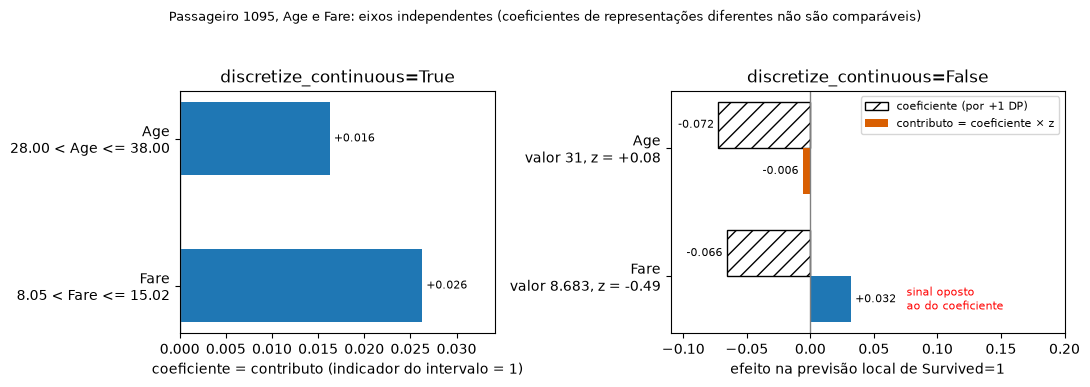

In [33]:
import matplotlib.pyplot as plt

POS, NEG = '#1f77b4', '#d95f02'
SHOW = ['Age', 'Fare']
y = np.arange(len(SHOW))[::-1]
h = 0.36
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.9), gridspec_kw={'width_ratios': [1, 1.25]})

t = tabs[True].loc[SHOW]
bars = ax1.barh(y, t['coeficiente'], height=0.5, color=[POS if v > 0 else NEG for v in t['coeficiente']])
ax1.bar_label(bars, fmt='%+.3f', padding=3, fontsize=8)
ax1.set_yticks(y, [f"{f}\n{c}" for f, c in zip(SHOW, t['condição'])])
ax1.axvline(0, color='gray', lw=1)
ax1.margins(x=0.3)
ax1.set_xlabel('coeficiente = contributo (indicador do intervalo = 1)')
ax1.set_title('discretize_continuous=True')

t = tabs[False].loc[SHOW]
b1 = ax2.barh(y + h / 2, t['coeficiente'], height=h, color='white', edgecolor='black', hatch='//', label='coeficiente (por +1 DP)')
b2 = ax2.barh(y - h / 2, t['contributo'], height=h, color=[POS if v > 0 else NEG for v in t['contributo']],
              label='contributo = coeficiente × z')
ax2.bar_label(b1, fmt='%+.3f', padding=3, fontsize=8)
ax2.bar_label(b2, fmt='%+.3f', padding=3, fontsize=8)
for yi, f in zip(y, SHOW):
    r = t.loc[f]
    if np.sign(r['coeficiente']) != np.sign(r['contributo']):
        ax2.annotate('sinal oposto\nao do coeficiente', (r['contributo'], yi - h / 2), xytext=(40, 0),
                     textcoords='offset points', va='center', fontsize=8, color='red')
ax2.set_yticks(y, [f"{f}\nvalor {r['valor']:.4g}, z = {r['z']:+.2f}" for f, (_, r) in zip(SHOW, t.iterrows())])
ax2.axvline(0, color='gray', lw=1)
ax2.set_xlim(-0.11, 0.2)
ax2.set_xlabel('efeito na previsão local de Survived=1')
ax2.set_title('discretize_continuous=False')
ax2.legend(fontsize=8, loc='upper right')
fig.suptitle(f'Passageiro {A4_ID}, Age e Fare: eixos independentes (coeficientes de representações diferentes não são comparáveis)', fontsize=9)
plt.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

In [34]:
# Validação da Atividade 4
assert A4_ID == 1095 and A4_ID in X_test.index
(expl_t, exp_t), (expl_f, exp_f) = rep[True], rep[False]

# mesmo passageiro nas duas explicações (1ª amostra da vizinhança = instância) e mesma previsão do XGBoost
for flag in (True, False):
    seen = []
    def recording(a):
        seen.append(np.array(a))
        return predict_fn(a)
    explain_passenger(build_explainer(LIME_CONFIG['random_state'], flag), A4_ID, 50, A4_FEATURES, predict=recording)
    assert np.array_equal(seen[0][0], x1095)
p_ref = predict_fn(X_test.loc[[A4_ID]].values)[0]
assert np.array_equal(np.asarray(exp_t.predict_proba), p_ref) and np.array_equal(np.asarray(exp_f.predict_proba), p_ref)
assert np.isclose(p_ref[TARGET_CLASS], fid.loc[A4_ID, 'P(Survived)'], rtol=0, atol=1e-12)
assert np.array_equal(predict_fn(X_test.values)[:, TARGET_CLASS], p_test.to_numpy())                  # modelo inalterado

# só a discretização muda: mesmos argumentos e mesmo explainer, exceto o discretizador
assert expl_t.discretizer is not None and expl_f.discretizer is None
assert expl_t.feature_names == expl_f.feature_names == FEATURES and expl_t.class_names == expl_f.class_names
assert expl_t.categorical_names == expl_f.categorical_names and expl_f.categorical_features == CAT_IDX
assert expl_t.mode == expl_f.mode == 'classification' and expl_t.sample_around_instance == expl_f.sample_around_instance
assert all(set(e.local_exp) == {TARGET_CLASS} and len(e.local_exp[TARGET_CLASS]) == 9 for e in (exp_t, exp_f))

# Age e Fare presentes em ambas
for flag in (True, False):
    assert {'Age', 'Fare'} <= {FEATURES[i] for i, _ in rep[flag][1].local_exp[TARGET_CLASS]} and set(tabs[flag].index) == set(FEATURES)

# média e escala: as do explainer (categóricas 0/1; contínuas = estatísticas de X_train com ddof=0)
cont = [FEATURES.index(f) for f in ('Age', 'SibSp', 'Parch', 'Fare')]
assert np.array_equal(tabs[False].loc[['Age', 'Fare'], 'média'], expl_f.scaler.mean_[[FEATURES.index('Age'), FEATURES.index('Fare')]])
assert np.allclose(expl_f.scaler.mean_[cont], X_train.iloc[:, cont].mean().to_numpy())
assert np.allclose(expl_f.scaler.scale_[cont], X_train.iloc[:, cont].std(ddof=0).to_numpy())
assert (expl_f.scaler.mean_[CAT_IDX] == 0).all() and (expl_f.scaler.scale_[CAT_IDX] == 1).all()
assert (expl_t.scaler.mean_ == 0).all() and (expl_t.scaler.scale_ == 1).all()

# valores padronizados e contributos recalculados de forma independente
for f in ('Age', 'Fare', 'SibSp', 'Parch'):
    zi = (X_test.loc[A4_ID, f] - X_train[f].mean()) / X_train[f].std(ddof=0)
    c = dict((FEATURES[i], w) for i, w in exp_f.local_exp[TARGET_CLASS])[f]
    assert np.isclose(tabs[False].loc[f, 'z'], zi) and np.isclose(tabs[False].loc[f, 'contributo'], c * zi)
assert (tabs[False].loc[CAT_FEATURES, 'z'] == 1).all() and (tabs[True]['z'] == 1).all()
assert np.allclose(tabs[True]['contributo'], tabs[True]['coeficiente'])
for f in ('Age', 'Fare'):
    r = tabs[False].loc[f]
    assert (np.sign(r['coeficiente']) == np.sign(r['contributo'])) == bool(sign_check.loc[f, 'sinal coef = sinal contributo'])

# reconstrução da previsão local
for flag in (True, False):
    e = rep[flag][1]
    assert np.isclose(e.intercept[TARGET_CLASS] + tabs[flag]['contributo'].sum(), float(np.ravel(e.local_pred)[0]), rtol=0, atol=1e-8)

# atividades anteriores inalteradas
assert all(a.equals(b) for a, b in zip(snapshot4, (fid, fid13, table_a, table_b, freq3, runs, stat, stab)))
assert results[A4_ID] == summarize(run_lime(A4_ID), A4_ID) and LIME_CONFIG['num_features'] == 5
print('Validação da Atividade 4: OK')

Validação da Atividade 4: OK


### Observações (Atividade 4, passageiro 1095)

Um só passageiro e uma só semente (123): os números descrevem este caso. Os coeficientes são do substituto linear local, não efeitos causais.

**1. Como muda a explicação de `Age` e `Fare`?** Com `True`, cada uma é uma **condição de intervalo**: `28.00 < Age <= 38.00` (coeficiente +0,016) e `8.05 < Fare <= 15.02` (+0,026). Com `False`, cada uma é um **único número para a variável toda**: `Age` −0,0725 e `Fare` −0,0659, em unidades de desvio-padrão (14,36 anos e 58,02, respetivamente). Em ambos os casos o peso é pequeno face a `Sex=female` (+0,50 / +0,52) e `Pclass=3` (−0,25). O contributo de `Age` muda de sinal entre representações (+0,016 com `True`, −0,006 com `False`), mas ambos são ≈ 0; o de `Fare` é positivo nas duas (+0,026 e +0,032), embora o coeficiente com `False` seja negativo (ver ponto 3). As duas explicações não são a mesma informação em escalas diferentes: a vizinhança também muda (com `False` as contínuas são amostradas de uma Normal com a média e o DP do treino, que para `Fare` dá cerca de 26% de valores negativos), por isso não se deve atribuir a diferença só à escala.

**2. O que significa cada número?** Com `True`: o efeito de **o valor estar naquele intervalo** (indicador 1 vs 0) na previsão local de `Survived=1`; não é uma variação por ano nem por unidade monetária, e o contributo é igual ao coeficiente porque o indicador vale 1 na instância. Com `False`: nas contínuas, a **inclinação por +1 DP** da variável (com as outras fixas, no substituto local); o contributo para este passageiro é `coeficiente × z`, com `z = (valor − média) / escala` e a média e escala do explainer, e mede o efeito face a um valor igual à média do treino (`z = 0`). Nas categóricas (`Sex`, `Pclass`, `Embarked_*`) o indicador vale 1 e o contributo é igual ao coeficiente.

**3. Com `False`, o sinal da barra coincide com o efeito neste passageiro?** Só quando o valor está acima da média (`z > 0`). `Age` (z = +0,08): sim, mas o efeito é −0,006, desprezável. `Fare` (8,68 contra média 36,85, z = −0,49): **não**; coeficiente −0,066, contributo **+0,032**. O mesmo em `SibSp` (−0,014 → +0,008) e `Parch` (+0,018 → −0,009). Quem lesse a barra negativa de `Fare` como "a tarifa deste passageiro reduz a probabilidade de sobreviver" leria o contrário do que o substituto atribui. A reconstrução confirma os números: `intercept + Σ contributos` = 0,280 + 0,337 = 0,618 (`False`) e 0,316 + 0,293 = 0,609 (`True`), iguais à *local prediction* do LIME.

**Fidelidade.** P(Survived) = 0,075 do XGBoost. `True`, 9 features: R² 0,460, erro absoluto 0,534. `False`, 9 features: R² 0,527, erro absoluto 0,542. O R² é maior com `False` mas o erro no ponto não melhora, e as duas *local predictions* (0,609 e 0,618) ficam do lado oposto de 0,5 face ao modelo. Os R² não são diretamente comparáveis (vizinhanças e distâncias diferentes) e há uma só semente. Com `discretize_continuous=True` e 5 features (Atividades 1–3), o R² local era 0,457 e o erro absoluto 0,508; passar de 5 para 9 features, ainda com `True`, pouco mudou (R² 0,457 → 0,460; erro 0,508 → 0,534).

**Risco de leitura.** Um gráfico de coeficientes com `discretize_continuous=False` mostra inclinações, não contributos; um com `True` mostra intervalos, não unidades. Em nenhum dos casos os números são efeitos causais nem percentagens de importância.

## Atividade 5 — Explore SP-LIME

**Candidatos:** 60 passageiros distintos de `X_test`, sem reposição, com `np.random.default_rng(2026)` (independente do LIME), mantendo a ordem sorteada; são os **mesmos** nas quatro execuções.

**SP-LIME** (`lime.submodular_pick.SubmodularPick`, `method='full'` sobre os 60): `num_features=5`, `num_samples=5000`, `discretize_continuous=True`, `num_exps_desired ∈ {3, 5}` e sementes do explainer `{123, 7}`, com um **explainer novo** por execução. O `SubmodularPick` usa `top_labels=1` por omissão e passa os restantes argumentos ao `explain_instance`; aqui `top_labels=0` e `labels=(1,)`, de modo que todas as explicações são só da classe `Survived=1`.

**Como o SP-LIME decide (lido no código instalado):** a matriz `W` tem uma coluna por **condição** (o texto de `as_list`, por exemplo `Sex=male` ou `Age > 38.00`), com o peso LIME de cada explicação; a importância da condição é `I_j = √Σ_i |W_ij|`; escolhe-se de forma *greedy* a explicação que mais aumenta `Σ_j I_j · 1[condição j coberta]`. O critério é cobertura de condições, não representatividade da população.

**Duas notas de comparabilidade.** (i) As 60 explicações de cada execução são geradas em sequência com o **mesmo** explainer, cujo estado aleatório avança; a explicação de um passageiro depende por isso da sua posição na lista e não coincide com a do `run_lime` das atividades anteriores. (ii) "Importância" de uma condição aqui é só o critério do SP-LIME sobre estes 60 candidatos; não é importância global do XGBoost.

In [35]:
from lime.submodular_pick import SubmodularPick

SP_N, SP_CAND_SEED = 60, 2026
SP_SEEDS, SP_K = [123, 7], [3, 5]
cand_ids = [int(i) for i in np.random.default_rng(SP_CAND_SEED).choice(X_test.index.to_numpy(), size=SP_N, replace=False)]
cand_X = X_test.loc[cand_ids].values
assert LIME_CONFIG['num_features'] == 5 and LIME_CONFIG['num_samples'] == 5000 and LIME_CONFIG['discretize_continuous']
snapshot5 = [d.copy() for d in (fid, fid13, table_a, table_b, freq3, runs, stat, stab, age_fare)]


def run_sp(seed, k):
    return SubmodularPick(build_explainer(seed, True), cand_X, predict_fn, method='full', num_exps_desired=k,
                          num_features=LIME_CONFIG['num_features'], top_labels=0, labels=(1,),
                          num_samples=LIME_CONFIG['num_samples'])


sp_runs = {(seed, k): run_sp(seed, k) for seed in SP_SEEDS for k in SP_K}
cand_res = {key: [summarize(e, pid) for e, pid in zip(sp.explanations, cand_ids)] for key, sp in sp_runs.items()}
print('candidatos:', len(cand_ids), '| primeiros:', cand_ids[:8], '...')
for (seed, k), sp in sp_runs.items():
    print(f'semente {seed}, k={k}: índices internos V={sp.V} -> PassengerId {[cand_ids[i] for i in sp.V]}')

candidatos: 60 | primeiros: [656, 815, 530, 824, 1166, 408, 585, 301] ...
semente 123, k=3: índices internos V=[57, 12, 49] -> PassengerId [1184, 45, 583]
semente 123, k=5: índices internos V=[57, 12, 49, 56, 30] -> PassengerId [1184, 45, 583, 215, 310]
semente 7, k=3: índices internos V=[57, 12, 49] -> PassengerId [1184, 45, 583]
semente 7, k=5: índices internos V=[57, 12, 49, 56, 45] -> PassengerId [1184, 45, 583, 215, 441]


### Passageiros selecionados

In [36]:
from IPython.display import display


def passenger_info(pid):
    r = X_test.loc[pid]
    assert r[['Embarked_C', 'Embarked_Q', 'Embarked_S']].sum() == 1
    return dict(Sex='male' if r['Sex'] == 1 else 'female', Pclass=int(r['Pclass']), Age=r['Age'], Fare=r['Fare'],
                Embarked='CQS'[int(np.argmax(r[['Embarked_C', 'Embarked_Q', 'Embarked_S']].to_numpy()))])


rows = []
for (seed, k), sp in sp_runs.items():
    for order, i in enumerate(sp.V, 1):
        pid, r = cand_ids[i], cand_res[(seed, k)][i]
        ranked = sorted(zip(r['weights'], r['rules']), key=lambda t: -abs(t[0][1]))[:3]
        rows.append(dict(seed=seed, k=k, ordem=order, PassengerId=pid, P=r['p_model'], prevista=int(r['p_model'] >= 0.5),
                         real=int(y_test.loc[pid]), top3='; '.join(f'{c} ({w:+.3f})' for _, (c, w) in ranked),
                         **passenger_info(pid), R2=r['r2'], local_pred=r['local_pred'], erro_abs=abs(r['p_model'] - r['local_pred']),
                         cruza_05=(r['p_model'] >= 0.5) != (r['local_pred'] >= 0.5)))
sel = pd.DataFrame(rows)
pd.set_option('display.max_colwidth', None, 'display.width', 250)
print('Passageiros selecionados (k=3 é o prefixo de k=5 na mesma semente)')
display(sel[['seed', 'k', 'ordem', 'PassengerId', 'P', 'prevista', 'real', 'top3']].round(4).set_index(['seed', 'k', 'ordem']))
print('Características dos passageiros selecionados (k=5; os 3 primeiros formam k=3)')
display(sel[sel['k'] == 5][['seed', 'ordem', 'PassengerId', 'Sex', 'Pclass', 'Age', 'Fare', 'Embarked', 'P']].round(4).set_index(['seed', 'ordem']))

Passageiros selecionados (k=3 é o prefixo de k=5 na mesma semente)


PassengerId       P  prevista  real                                                               top3
seed k ordem                                                                                                        
123  3 1             1184  0.0156         0     0         Sex=male (-0.505); Pclass=3 (-0.236); Age > 38.00 (-0.137)
       2               45  0.9999         1     1       Sex=female (+0.501); Pclass=1 (+0.242); Age > 38.00 (-0.152)
       3              583  0.8795         1     1  Sex=female (+0.533); Age <= 21.00 (+0.130); Embarked_C=0 (-0.119)
     5 1             1184  0.0156         0     0         Sex=male (-0.505); Pclass=3 (-0.236); Age > 38.00 (-0.137)
       2               45  0.9999         1     1       Sex=female (+0.501); Pclass=1 (+0.242); Age > 38.00 (-0.152)
       3              583  0.8795         1     1  Sex=female (+0.533); Age <= 21.00 (+0.130); Embarked_C=0 (-0.119)
       4              215  0.9994         1     1      Sex=female (+0.489); Pclass=1 (+0.262); Embarked_C=1 (+0.089)
       5              310  0.9982         1     1      Sex=female (+0.499); Pclass=1 (+0.244); Embarked_C=0 (-0.108)
7    3 1             1184  0.0156         0     0         Sex=male (-0.492); Pclass=3 (-0.247); Age > 38.00 (-0.156)
       2               45  0.9999         1     1       Sex=female (+0.504); Pclass=1 (+0.256); Age > 38.00 (-0.152)
       3              583  0.8795         1     1  Sex=female (+0.486); Age <= 21.00 (+0.119); Embarked_C=0 (-0.117)
     5 1             1184  0.0156         0     0         Sex=male (-0.492); Pclass=3 (-0.247); Age > 38.00 (-0.156)
       2               45  0.9999         1     1       Sex=female (+0.504); Pclass=1 (+0.256); Age > 38.00 (-0.152)
       3              583  0.8795         1     1  Sex=female (+0.486); Age <= 21.00 (+0.119); Embarked_C=0 (-0.117)
       4              215  0.9994         1     1      Sex=female (+0.517); Pclass=1 (+0.214); Embarked_C=1 (+0.108)
       5              441  0.9818         1     1   Sex=female (+0.508); Age > 38.00 (-0.136); Embarked_Q=0 (+0.108)

Características dos passageiros selecionados (k=5; os 3 primeiros formam k=3)


PassengerId     Sex  Pclass   Age      Fare Embarked       P
seed ordem                                                              
123  1             1184    male       3  39.0    7.9250        S  0.0156
     2               45  female       1  41.0  134.5000        C  0.9999
     3              583  female       2  12.0   15.7500        S  0.8795
     4              215  female       1  23.0  113.2750        C  0.9994
     5              310  female       1  31.0  164.8667        S  0.9982
7    1             1184    male       3  39.0    7.9250        S  0.0156
     2               45  female       1  41.0  134.5000        C  0.9999
     3              583  female       2  12.0   15.7500        S  0.8795
     4              215  female       1  23.0  113.2750        C  0.9994
     5              441  female       2  48.0   65.0000        S  0.9818

### Cobertura por feature e por condição

Réplica da matriz `W` do SP-LIME (colunas = condições) para medir a cobertura. **Feature** = índice estruturado do LIME → `FEATURES`; **condição** = texto interpretável (`Age > 38.00` e `Age <= 21.00` são condições diferentes da mesma feature). `Σ|peso|` e `I = √Σ|peso|` descrevem só os 60 candidatos e são o critério do SP-LIME, não importância global do modelo.

In [37]:
def sp_matrix(exps):
    """Réplica da matriz W do SubmodularPick: uma coluna por condição."""
    idx = {}
    for e in exps:
        for lab in e.available_labels():
            for c, _ in e.as_list(label=lab):
                idx.setdefault(c, len(idx))
    W = np.zeros((len(exps), len(idx)))
    for i, e in enumerate(exps):
        for lab in e.available_labels():
            for c, v in e.as_list(lab):
                W[i, idx[c]] += v
    return W, idx


def greedy(W, k):
    imp = np.sum(np.abs(W), axis=0) ** .5
    remaining, V = set(range(len(W))), []
    for _ in range(k):
        best, best_i = 0, None
        for i in remaining:
            cur = np.dot(np.sum(np.abs(W)[V + [i]], axis=0) > 0, imp)
            if cur >= best:
                best, best_i = cur, i
        V.append(best_i)
        remaining -= {best_i}
    return V, imp


def feats_of(e):
    return {FEATURES[i] for i, _ in e.local_exp[TARGET_CLASS]}


def conds_of(e):
    return {c for c, _ in e.as_list(label=TARGET_CLASS)}


cov = {}
for key, sp in sp_runs.items():
    W, idx = sp_matrix(sp.explanations)
    names = sorted(idx, key=idx.get)
    imp = np.sum(np.abs(W), axis=0) ** .5
    covered = np.sum(np.abs(W)[sp.V], axis=0) > 0
    steps = [np.dot(np.sum(np.abs(W)[sp.V[:j]], axis=0) > 0, imp) / imp.sum() for j in range(1, len(sp.V) + 1)]
    sel_exps = sp.sp_explanations
    cov[key] = dict(W=W, names=names, imp=imp, steps=steps, objective=steps[-1],
                    cand_feats=set().union(*map(feats_of, sp.explanations)), cand_conds=set(names),
                    feats=set().union(*map(feats_of, sel_exps)), conds={n for n, c in zip(names, covered) if c},
                    feats_by_step=[set().union(*map(feats_of, sel_exps[:j])) for j in range(1, len(sel_exps) + 1)],
                    conds_by_step=[set().union(*map(conds_of, sel_exps[:j])) for j in range(1, len(sel_exps) + 1)])

rows = []
for (seed, k), c in cov.items():
    rows.append({'seed': seed, 'k': k, 'features cobertas': len(c['feats']), 'features nos 60 candidatos': len(c['cand_feats']),
                 'condições cobertas': len(c['conds']), 'condições nos 60 candidatos': len(c['cand_conds']),
                 'objetivo SP-LIME coberto': c['objective']})
cov_tab = pd.DataFrame(rows).set_index(['seed', 'k'])
print('Cobertura com 3 e 5 explicações')
display(cov_tab.round(3))

print('Informação introduzida passo a passo (k=5): novas features / novas condições / ganho no objetivo')
rows = []
for seed in SP_SEEDS:
    c, sp = cov[(seed, 5)], sp_runs[(seed, 5)]
    for j, i in enumerate(sp.V):
        prev_f = c['feats_by_step'][j - 1] if j else set()
        prev_c = c['conds_by_step'][j - 1] if j else set()
        gain = c['steps'][j] - (c['steps'][j - 1] if j else 0)
        rows.append({'seed': seed, 'ordem': j + 1, 'PassengerId': cand_ids[i], 'novas features': sorted(c['feats_by_step'][j] - prev_f),
                     'novas condições': sorted(c['conds_by_step'][j] - prev_c), 'ganho no objetivo': gain,
                     'condições repetidas das anteriores': len(conds_of(sp.sp_explanations[j]) & prev_c)})
step_tab = pd.DataFrame(rows).set_index(['seed', 'ordem'])
display(step_tab.round(3))

print('Condições mais relevantes nos 60 candidatos (semente 123), por Σ|peso|, e quem as cobre')
c0 = cov[(123, 5)]
n_in = (np.abs(c0['W']) > 0).sum(axis=0)
cond_tab = pd.DataFrame({'condição': c0['names'], 'n explicações': n_in, 'Σ|peso|': np.abs(c0['W']).sum(axis=0), 'I = √Σ|peso|': c0['imp']})
for key in cov:
    cond_tab[f's{key[0]} k={key[1]}'] = [n in cov[key]['conds'] for n in c0['names']]
cond_tab = cond_tab.sort_values('Σ|peso|', ascending=False).set_index('condição')
display(cond_tab.head(12).round(3))
print('Condições dos 60 candidatos não cobertas por s123 k=5:', sorted(c0['cand_conds'] - c0['conds']))

Cobertura com 3 e 5 explicações


features cobertas  features nos 60 candidatos  condições cobertas  condições nos 60 candidatos  objetivo SP-LIME coberto
seed k                                                                                                                          
123  3                  6                           8                  12                           16                     0.908
     5                  8                           8                  15                           16                     0.990
7    3                  6                           8                  12                           16                     0.909
     5                  8                           8                  15                           16                     0.986

Informação introduzida passo a passo (k=5): novas features / novas condições / ganho no objetivo


PassengerId                        novas features                                                novas condições  ganho no objetivo  condições repetidas das anteriores
seed ordem                                                                                                                                                                         
123  1             1184  [Age, Embarked_C, Fare, Pclass, Sex]  [Age > 38.00, Embarked_C=0, Fare <= 8.05, Pclass=3, Sex=male]              0.486                                   0
     2               45                               [SibSp]            [Embarked_C=1, Pclass=1, Sex=female, SibSp <= 0.00]              0.291                                   1
     3              583                                    []                [15.02 < Fare <= 34.38, Age <= 21.00, Pclass=2]              0.131                                   2
     4              215                               [Parch]                          [0.00 < SibSp <= 1.00, Parch <= 0.00]              0.055                                   3
     5              310                          [Embarked_Q]                                                 [Embarked_Q=0]              0.028                                   4
7    1             1184  [Age, Embarked_C, Fare, Pclass, Sex]  [Age > 38.00, Embarked_C=0, Fare <= 8.05, Pclass=3, Sex=male]              0.484                                   0
     2               45                               [SibSp]            [Embarked_C=1, Pclass=1, Sex=female, SibSp <= 0.00]              0.292                                   1
     3              583                                    []                [15.02 < Fare <= 34.38, Age <= 21.00, Pclass=2]              0.133                                   2
     4              215                               [Parch]                          [0.00 < SibSp <= 1.00, Parch <= 0.00]              0.050                                   3
     5              441                          [Embarked_Q]                                                 [Embarked_Q=0]              0.027                                   4

Condições mais relevantes nos 60 candidatos (semente 123), por Σ|peso|, e quem as cobre


,n explicações,Σ|peso|,I = √Σ|peso|,s123 k=3,s123 k=5,s7 k=3,s7 k=5
condição,,,,,,,
Sex=male,39,19.181,4.380,True,True,True,True
Sex=female,21,10.403,3.225,True,True,True,True
Pclass=3,29,6.953,2.637,True,True,True,True
Embarked_C=0,50,5.514,2.348,True,True,True,True
Pclass=1,13,3.198,1.788,True,True,True,True
Age > 38.00,17,2.508,1.584,True,True,True,True
Fare <= 8.05,22,2.441,1.562,True,True,True,True
SibSp <= 0.00,33,2.198,1.483,True,True,True,True
Pclass=2,17,1.508,1.228,True,True,True,True


Condições dos 60 candidatos não cobertas por s123 k=5: ['Fare > 34.38']


### Sensibilidade à semente

In [38]:
rows = []
for k in SP_K:
    a, b = (set(cand_ids[i] for i in sp_runs[(s, k)].V) for s in SP_SEEDS)
    ca, cb = cov[(123, k)], cov[(7, k)]
    rows.append({'k': k, 'passageiros em comum': len(a & b), 'Jaccard passageiros': len(a & b) / len(a | b),
                 'Jaccard features': len(ca['feats'] & cb['feats']) / len(ca['feats'] | cb['feats']),
                 'Jaccard condições': len(ca['conds'] & cb['conds']) / len(ca['conds'] | cb['conds']),
                 'features só em 123': sorted(ca['feats'] - cb['feats']), 'features só em 7': sorted(cb['feats'] - ca['feats']),
                 'condições só em 123': sorted(ca['conds'] - cb['conds']), 'condições só em 7': sorted(cb['conds'] - ca['conds'])})
seed_tab = pd.DataFrame(rows).set_index('k')
display(seed_tab.T)

# mesmos passageiros: a explicação mudou entre sementes?
common = sorted(set(cand_ids[i] for i in sp_runs[(123, 5)].V) & set(cand_ids[i] for i in sp_runs[(7, 5)].V))
print('Passageiros comuns às duas sementes (k=5):', common)
for pid in common:
    i = cand_ids.index(pid)
    d1, d2 = dict(cand_res[(123, 5)][i]['rules']), dict(cand_res[(7, 5)][i]['rules'])
    shared = set(d1) & set(d2)
    print(f"  {pid}: condições iguais={set(d1) == set(d2)}, R² {cand_res[(123, 5)][i]['r2']:.3f} vs {cand_res[(7, 5)][i]['r2']:.3f}, "
          f"maior diferença de peso nas condições comuns {max(abs(d1[c] - d2[c]) for c in shared):.3f}")

same_conds = sum({c for c, _ in cand_res[(123, 5)][i]['rules']} == {c for c, _ in cand_res[(7, 5)][i]['rules']} for i in range(SP_N))
print(f'Entre os 60 candidatos, {same_conds} têm exatamente o mesmo conjunto de 5 condições com as duas sementes')

k,3,5
passageiros em comum,3,4
Jaccard passageiros,1.0,0.666667
Jaccard features,1.0,1.0
Jaccard condições,1.0,1.0
features só em 123,[],[]
features só em 7,[],[]
condições só em 123,[],[]
condições só em 7,[],[]


Passageiros comuns às duas sementes (k=5): [45, 215, 583, 1184]
  45: condições iguais=True, R² 0.473 vs 0.478, maior diferença de peso nas condições comuns 0.025
  215: condições iguais=True, R² 0.439 vs 0.454, maior diferença de peso nas condições comuns 0.048
  583: condições iguais=True, R² 0.447 vs 0.386, maior diferença de peso nas condições comuns 0.047
  1184: condições iguais=True, R² 0.508 vs 0.480, maior diferença de peso nas condições comuns 0.020
Entre os 60 candidatos, 49 têm exatamente o mesmo conjunto de 5 condições com as duas sementes


### Representatividade e fidelidade das explicações selecionadas

In [39]:
def describe(ids, name):
    d = X_test.loc[ids]
    p = p_test.loc[ids]
    g = pd.Series([conf_group(v) for v in p]).value_counts()
    return {'grupo': name, 'n': len(ids), '% male': 100 * d['Sex'].mean(),
            '% Pclass 1': 100 * (d['Pclass'] == 1).mean(), '% Pclass 2': 100 * (d['Pclass'] == 2).mean(), '% Pclass 3': 100 * (d['Pclass'] == 3).mean(),
            'P mediana': p.median(), 'P min': p.min(), 'P max': p.max(),
            'n P<=0,1': int(g.get('Near 0', 0)), 'n P>=0,9': int(g.get('Near 1', 0)), 'n 0,4<=P<=0,6': int(g.get('Uncertain', 0)),
            'Age mediana': d['Age'].median(), 'Fare mediana': d['Fare'].median(), '% Embarked C': 100 * d['Embarked_C'].mean()}


groups = [('teste (209)', list(X_test.index)), ('candidatos (60)', cand_ids)]
for seed in SP_SEEDS:
    for k in SP_K:
        groups.append((f'selec. s{seed} k={k}', [cand_ids[i] for i in sp_runs[(seed, k)].V]))
rep_tab = pd.DataFrame([describe(ids, name) for name, ids in groups]).set_index('grupo')
print('Resumo descritivo (grupos pequenos: sem testes de significância)')
display(rep_tab.round(3).T)

fid_c = pd.DataFrame([dict(seed=s, R2=r['r2'], erro_abs=abs(r['p_model'] - r['local_pred']),
                           cruza_05=(r['p_model'] >= 0.5) != (r['local_pred'] >= 0.5))
                      for s in SP_SEEDS for r in cand_res[(s, 5)]])
print('Fidelidade das explicações selecionadas (k=5) vs. as 60 candidatas da mesma semente')
rows = []
for seed in SP_SEEDS:
    cs = fid_c[fid_c['seed'] == seed]
    ss = sel[(sel['seed'] == seed) & (sel['k'] == 5)]
    rows.append({'seed': seed, 'candidatas R² mediana': cs['R2'].median(), 'candidatas R² min–max': f"{cs['R2'].min():.3f}–{cs['R2'].max():.3f}",
                 'candidatas erro mediano': cs['erro_abs'].median(), 'candidatas erro máx': cs['erro_abs'].max(), 'candidatas cruzam 0,5': int(cs['cruza_05'].sum()),
                 'selec. R² mediana': ss['R2'].median(), 'selec. R² min–max': f"{ss['R2'].min():.3f}–{ss['R2'].max():.3f}",
                 'selec. erro mediano': ss['erro_abs'].median(), 'selec. erro máx': ss['erro_abs'].max(), 'selec. cruzam 0,5': int(ss['cruza_05'].sum())})
display(pd.DataFrame(rows).set_index('seed').round(3).T)
display(sel[sel['k'] == 5][['seed', 'ordem', 'PassengerId', 'P', 'local_pred', 'R2', 'erro_abs', 'cruza_05']].round(4).set_index(['seed', 'ordem']))

Resumo descritivo (grupos pequenos: sem testes de significância)


grupo,teste (209),candidatos (60),selec. s123 k=3,selec. s123 k=5,selec. s7 k=3,selec. s7 k=5
n,209.000,60.000,3.000,5.000,3.000,5.000
% male,67.943,65.000,33.333,20.000,33.333,20.000
% Pclass 1,31.100,21.667,33.333,60.000,33.333,40.000
% Pclass 2,26.316,30.000,33.333,20.000,33.333,40.000
% Pclass 3,42.584,48.333,33.333,20.000,33.333,20.000
P mediana,0.237,0.207,0.880,0.998,0.880,0.982
P min,0.000,0.000,0.016,0.016,0.016,0.016
P max,1.000,1.000,1.000,1.000,1.000,1.000
"n P<=0,1",93.000,26.000,1.000,1.000,1.000,1.000
"n P>=0,9",57.000,16.000,1.000,3.000,1.000,3.000


Fidelidade das explicações selecionadas (k=5) vs. as 60 candidatas da mesma semente


seed,123,7
candidatas R² mediana,0.45,0.452
candidatas R² min–max,0.348–0.508,0.360–0.491
candidatas erro mediano,0.154,0.151
candidatas erro máx,0.772,0.767
"candidatas cruzam 0,5",9,9
selec. R² mediana,0.447,0.454
selec. R² min–max,0.434–0.508,0.386–0.480
selec. erro mediano,0.089,0.112
selec. erro máx,0.148,0.326
"selec. cruzam 0,5",0,0


PassengerId       P  local_pred      R2  erro_abs  cruza_05
seed ordem                                                             
123  1             1184  0.0156      0.0218  0.5078    0.0062     False
     2               45  0.9999      0.8523  0.4727    0.1476     False
     3              583  0.8795      0.8007  0.4468    0.0788     False
     4              215  0.9994      0.9106  0.4392    0.0889     False
     5              310  0.9982      0.8855  0.4336    0.1127     False
7    1             1184  0.0156      0.0292  0.4798    0.0136     False
     2               45  0.9999      0.8868  0.4779    0.1131     False
     3              583  0.8795      0.7671  0.3860    0.1124     False
     4              215  0.9994      0.9159  0.4543    0.0835     False
     5              441  0.9818      0.6563  0.4118    0.3255     False

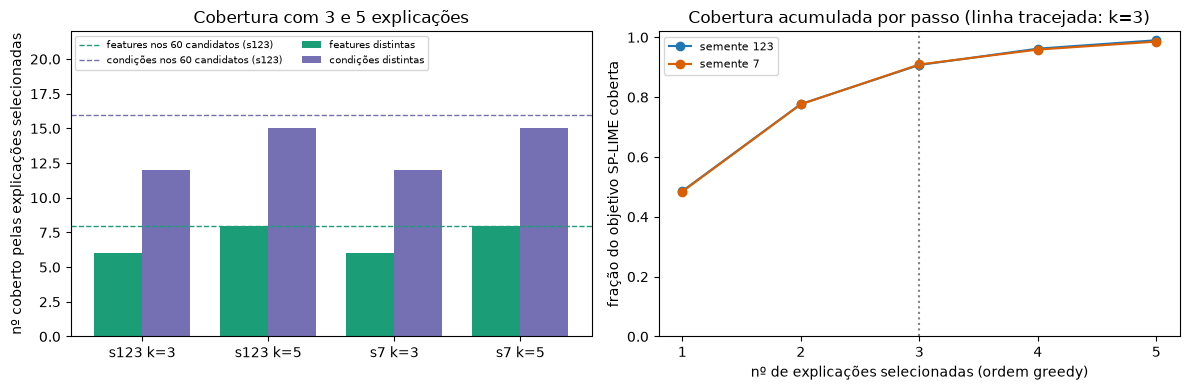

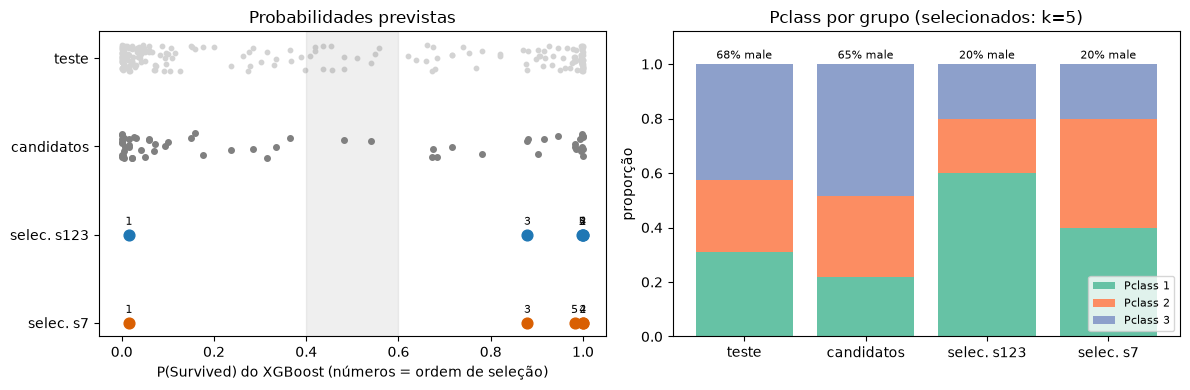

In [40]:
import matplotlib.pyplot as plt

C = {123: '#1f77b4', 7: '#d95f02'}
# --- Figura 1: cobertura
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
keys = list(cov)
x, w = np.arange(len(keys)), 0.38
a1.bar(x - w / 2, [len(cov[k]['feats']) for k in keys], w, label='features distintas', color='#1b9e77')
a1.bar(x + w / 2, [len(cov[k]['conds']) for k in keys], w, label='condições distintas', color='#7570b3')
a1.axhline(len(cov[keys[0]]['cand_feats']), color='#1b9e77', ls='--', lw=1, label='features nos 60 candidatos (s123)')
a1.axhline(len(cov[keys[0]]['cand_conds']), color='#7570b3', ls='--', lw=1, label='condições nos 60 candidatos (s123)')
a1.set_xticks(x, [f's{s} k={k}' for s, k in keys])
a1.set_ylabel('nº coberto pelas explicações selecionadas')
a1.set_title('Cobertura com 3 e 5 explicações')
a1.set_ylim(0, 22)
a1.legend(fontsize=7, loc='upper left', ncol=2)
for seed in SP_SEEDS:
    a2.plot(range(1, 6), cov[(seed, 5)]['steps'], 'o-', color=C[seed], label=f'semente {seed}')
a2.axvline(3, color='gray', ls=':')
a2.set_xticks(range(1, 6))
a2.set_xlabel('nº de explicações selecionadas (ordem greedy)')
a2.set_ylabel('fração do objetivo SP-LIME coberta')
a2.set_ylim(0, 1.02)
a2.set_title('Cobertura acumulada por passo (linha tracejada: k=3)')
a2.legend(fontsize=8)
plt.tight_layout()
plt.show()

# --- Figura 2: representatividade
jit = np.random.default_rng(0)
fig, (b1, b2) = plt.subplots(1, 2, figsize=(12, 4))
b1.scatter(p_test, 3 + jit.uniform(-.15, .15, len(p_test)), s=10, color='lightgray', label='teste (209)')
b1.scatter(p_test.loc[cand_ids], 2 + jit.uniform(-.15, .15, SP_N), s=16, color='gray', label='candidatos (60)')
for yi, seed in zip((1, 0), SP_SEEDS):
    ids = [cand_ids[i] for i in sp_runs[(seed, 5)].V]
    b1.scatter(p_test.loc[ids], np.full(5, yi), s=60, color=C[seed], label=f'selec. s{seed} (k=5)')
    for o, pid in enumerate(ids, 1):
        b1.annotate(str(o), (p_test.loc[pid], yi), textcoords='offset points', xytext=(0, 7), ha='center', fontsize=8)
b1.axvspan(0.4, 0.6, color='gray', alpha=.12)
b1.set_yticks([3, 2, 1, 0], ['teste', 'candidatos', 'selec. s123', 'selec. s7'])
b1.set_xlabel('P(Survived) do XGBoost (números = ordem de seleção)')
b1.set_title('Probabilidades previstas')
bars = [('teste', list(X_test.index)), ('candidatos', cand_ids)] + [(f'selec. s{s}', [cand_ids[i] for i in sp_runs[(s, 5)].V]) for s in SP_SEEDS]
bottom = np.zeros(len(bars))
for cl, col in zip((1, 2, 3), ('#66c2a5', '#fc8d62', '#8da0cb')):
    share = np.array([(X_test.loc[ids, 'Pclass'] == cl).mean() for _, ids in bars])
    b2.bar([n for n, _ in bars], share, bottom=bottom, color=col, label=f'Pclass {cl}')
    bottom += share
for xi, (n, ids) in enumerate(bars):
    b2.text(xi, 1.02, f"{100 * X_test.loc[ids, 'Sex'].mean():.0f}% male", ha='center', fontsize=8)
b2.set_ylim(0, 1.12)
b2.set_ylabel('proporção')
b2.set_title('Pclass por grupo (selecionados: k=5)')
b2.legend(fontsize=8, loc='lower right')
plt.tight_layout()
plt.show()

In [41]:
# Validação da Atividade 5
from collections import Counter

# 1-2. candidatos: únicos, em X_test, e as mesmas posições/ids em todas as execuções (cada explicação é do candidato certo)
assert len(cand_ids) == len(set(cand_ids)) == SP_N and set(cand_ids) <= set(X_test.index)
assert cand_ids == [int(i) for i in np.random.default_rng(SP_CAND_SEED).choice(X_test.index.to_numpy(), size=SP_N, replace=False)]
assert np.array_equal(cand_X, X_test.loc[cand_ids].values)
for key, sp in sp_runs.items():
    assert len(sp.explanations) == SP_N
    for i, e in enumerate(sp.explanations):
        assert np.array_equal(np.asarray(e.predict_proba), predict_fn(cand_X[[i]])[0])

# 3-4. número de selecionados, distintos e dentro dos candidatos
for (seed, k), sp in sp_runs.items():
    assert len(sp.V) == len(set(sp.V)) == k == len(sp.sp_explanations) and set(cand_ids[i] for i in sp.V) <= set(cand_ids)

# 5. só classe Survived=1 em todas as explicações
for sp in sp_runs.values():
    for e in sp.explanations:
        assert e.available_labels() == [TARGET_CLASS] and set(e.local_exp) == {TARGET_CLASS} == set(e.intercept)
        assert not getattr(e, 'top_labels', None)

# 6. reprodutibilidade (mesma semente, explainer novo) e comparabilidade entre k=3 e k=5
again = run_sp(123, 5)
assert again.V == sp_runs[(123, 5)].V and [summarize(e, p) for e, p in zip(again.explanations, cand_ids)] == cand_res[(123, 5)]
for seed in SP_SEEDS:
    assert cand_res[(seed, 3)] == cand_res[(seed, 5)]                                   # explicações candidatas idênticas
    assert sp_runs[(seed, 3)].V == sp_runs[(seed, 5)].V[:3]                              # 3 é o prefixo de 5
assert cand_res[(123, 5)] != cand_res[(7, 5)]                                          # a semente muda as explicações

# 7-9. mapeamento índices -> PassengerId, greedy replicado e métricas de cobertura/Jaccard recalculadas
for key, sp in sp_runs.items():
    assert [e is sp.explanations[i] for e, i in zip(sp.sp_explanations, sp.V)] == [True] * len(sp.V)
    W, _ = sp_matrix(sp.explanations)
    assert greedy(W, key[1])[0] == sp.V
    pids = [cand_ids[i] for i in sp.V]
    assert pids == list(sel[(sel['seed'] == key[0]) & (sel['k'] == key[1])].sort_values('ordem')['PassengerId'])
    for pid, e in zip(pids, sp.sp_explanations):
        assert np.array_equal(np.asarray(e.predict_proba), predict_fn(X_test.loc[[pid]].values)[0])
    fs = set()
    cs = set()
    for e in sp.sp_explanations:
        fs |= {FEATURES[i] for i, _ in e.local_exp[1]}
        cs |= {c for c, _ in e.as_list(label=1)}
    assert (len(fs), len(cs)) == (cov_tab.loc[key, 'features cobertas'], cov_tab.loc[key, 'condições cobertas'])
    imp = Counter()
    for e in sp.explanations:
        for c, v in e.as_list(label=1):
            imp[c] += abs(v)
    obj = sum(np.sqrt(imp[c]) for c in cs) / sum(np.sqrt(v) for v in imp.values())
    assert np.isclose(obj, cov_tab.loc[key, 'objetivo SP-LIME coberto'])
for k in SP_K:
    a, b = (set(cand_ids[i] for i in sp_runs[(s, k)].V) for s in SP_SEEDS)
    assert seed_tab.loc[k, 'passageiros em comum'] == len(a & b) and np.isclose(seed_tab.loc[k, 'Jaccard passageiros'], len(a & b) / len(a | b))
    assert 0 <= seed_tab.loc[k, 'Jaccard passageiros'] <= 1 and 0 <= seed_tab.loc[k, 'Jaccard condições'] <= 1
assert all(0 < v <= 1 for v in cov_tab['objetivo SP-LIME coberto'])
assert all(cov_tab.loc[(s, 3), 'objetivo SP-LIME coberto'] <= cov_tab.loc[(s, 5), 'objetivo SP-LIME coberto'] for s in SP_SEEDS)
assert (rep_tab.loc['teste (209)', 'n'], rep_tab.loc['candidatos (60)', 'n']) == (209, 60)

# 10. atividades anteriores inalteradas
assert all(a.equals(b) for a, b in zip(snapshot5, (fid, fid13, table_a, table_b, freq3, runs, stat, stab, age_fare)))
assert results[1095] == summarize(run_lime(1095), 1095) and list(fid.index) == ids20 == select_passengers()[0]
print('Validação da Atividade 5: OK')

Validação da Atividade 5: OK


### Observações (Atividade 5)

Candidatos: 60 passageiros de teste (2026); duas sementes de explainer (123 e 7); k = 3 e 5. Descrição de uma amostra pequena e de duas sementes, sem generalizar.

**1. Que passageiros são selecionados e como diferem?** Com k = 3, ambas as sementes escolhem **1184, 45, 583**; com k = 5 juntam-se **215** e depois **310** (semente 123) ou **441** (semente 7). Diferem nas **condições** que as suas explicações trazem: 1184 (homem, 3.ª classe, 39 anos, P≈0,016) traz `Sex=male`, `Pclass=3`, `Age > 38.00`, `Embarked_C=0`, `Fare <= 8.05` (ganho de 0,49 do objetivo do SP-LIME); 45 (mulher, 1.ª classe, P≈0,9999) acrescenta `Sex=female`, `Pclass=1`, `Embarked_C=1`, `SibSp <= 0.00` (0,29); 583 (mulher, 2.ª classe, 12 anos) acrescenta `Pclass=2`, `Age <= 21.00` e um intervalo de tarifa (0,13). Diversidade das explicações não é diversidade demográfica: 4 dos 5 selecionados são mulheres e só 1184 é homem.

**2. As explicações selecionadas cobrem as features importantes?** Quase. Em **features**, k = 3 cobre 6 das 8 que aparecem nas 60 explicações candidatas e k = 5 cobre as 8 (o 4.º traz `Parch`, o 5.º `Embarked_Q`); a 9.ª feature do modelo não aparece em nenhuma das 60 explicações. Em **condições**, k = 3 cobre 12 de 16 e k = 5 cobre 15 de 16; fica de fora `Fare > 34.38`, mesmo havendo selecionados com tarifas altas (134, 113, 165), porque essa condição não está entre as 5 das suas explicações. Cobrir uma feature não é cobrir os seus efeitos: `Age`, por exemplo, só entra pelas condições `Age > 38.00` e `Age <= 21.00`. A cobertura é das condições presentes em 5 modelos lineares locais, não do comportamento global do XGBoost.

**3. Com outra semente, os mesmos passageiros?** Para k = 3, sim (Jaccard 1,0). Para k = 5, 4 em 5 (Jaccard 0,67): só o 5.º muda (310 vs 441), e esse passo só acrescenta `Embarked_Q=0` (ganho ≈ 0,03). As features e as condições cobertas são as mesmas (Jaccard 1,0 em ambos os k). Os **mesmos passageiros** têm explicações diferentes entre sementes (diferenças de peso até 0,05; R² de 583: 0,447 vs 0,386), ainda que com as mesmas 5 condições; entre os 60 candidatos, 49 têm o mesmo conjunto de condições nas duas sementes. Com duas sementes não se mede a estabilidade do SP-LIME.

**De 3 para 5 explicações.** O objetivo coberto passa de 0,91 para 0,99 (semente 123: 0,908 → 0,990; semente 7: 0,909 → 0,986): os dois passageiros extra contribuem 0,055 e 0,028, e repetem 3 e 4 das 5 condições já cobertas. Em contagem simples de features (6 → 8) o ganho parece maior do que no objetivo, porque o objetivo pesa as condições por `√Σ|peso|` e as acrescentadas (`Parch`, `Embarked_Q`) têm peso pequeno. Retornos decrescentes, não proporcionais ao nº de passageiros.

**4. Os selecionados são representativos do conjunto?** Não, e não é o objetivo do SP-LIME. Nos k = 5, 20% são homens (teste: 68%), a probabilidade mediana prevista é 0,998 e 0,982 (teste: 0,237), 40–60% são de 1.ª classe (teste: 31%), a tarifa mediana é 113 e 65 (teste: 16,7), só 1 em 5 tem P ≤ 0,1 (teste: 93 de 209) e nenhum tem 0,4 ≤ P ≤ 0,6 (teste: 13). O SP-LIME maximiza a cobertura de condições, escolhendo explicações com muitas condições relevantes e diferentes, o que favorece perfis "típicos" de cada regra e não a distribuição da população. Cobertura explicativa não é representatividade estatística.

**Fidelidade das selecionadas (descritivo).** R² mediano 0,447 e 0,454, semelhante ao das 60 candidatas (0,450 e 0,452); erro absoluto mediano 0,089 e 0,112 contra 0,154 e 0,151; erro máximo 0,148 e 0,326 contra 0,77 em ambas; nenhuma das 5 selecionadas tem a *local prediction* do outro lado de 0,5, contra 9 das 60 candidatas em cada semente. O critério do SP-LIME otimiza a cobertura de condições e **não usa fidelidade**: com 5 explicações por semente, estes valores descrevem esta seleção e não são evidência de que o SP-LIME escolha explicações mais fiéis ou evite as problemáticas (o 441, selecionado com a semente 7, tem erro 0,326). Explicações escolhidas por cobertura continuam a precisar da verificação de fidelidade de cada uma.

**Limites.** (i) Só 5 explicações descrevem condições, não o modelo; (ii) 60 candidatos de 209 e duas sementes; (iii) as explicações das 60 candidatas são geradas em sequência com o mesmo explainer, por isso a de um passageiro difere da obtida com `run_lime` nas atividades anteriores (por exemplo 1184: `Age > 38.00` = −0,137 aqui e −0,159 na Atividade 1); (iv) os pesos são coeficientes do substituto local, não importâncias nem efeitos causais.

## Atividade 6 — Explore Further: plausibilidade das vizinhanças sintéticas do LIME

**Pergunta:** que fração das observações sintéticas que o LIME envia ao XGBoost viola restrições básicas do Titanic, que restrições, e muda isso com `discretize_continuous`? O objetivo é **caracterizar** as perturbações; não se testa nenhuma relação causal com a fidelidade (R²) das explicações.

**Desenho:** passageiros `1095`, `320` e `759` (do teste) × `discretize_continuous ∈ {True, False}` × sementes `[1, 3, 7, 11, 123]` = 30 explicações, com `num_samples=5000`, `num_features=5`, `labels=(1,)` e o mesmo modelo. Cada execução usa um explainer novo.

**Captura:** um *wrapper* de `predict_fn` (interface pública) guarda uma cópia do que recebe e das probabilidades devolvidas, e devolve exatamente o que o `predict_fn` original devolveu. O `explain_instance` chama `predict_fn` uma única vez com as 5000 linhas; a linha 0 é o passageiro original e **fica de fora** das taxas (4999 perturbações por execução).

**Unidade de análise.** O `explain_instance` gera a vizinhança sem usar o passageiro (ver verificação abaixo), pelo que as 30 explicações correspondem a **10 vizinhanças distintas** (2 configurações × 5 sementes). As taxas agregadas usam essas 5 vizinhanças por configuração, e não os 3 passageiros como réplicas.

**Âmbito.** Os resultados descrevem **esta configuração** (XGBoost fixo, `sample_around_instance=False`, `num_samples=5000`, `SibSp` e `Parch` tratadas como contínuas pelo explainer), **este dataset** e **as regras abaixo**. Não se generalizam a outras representações das features nem a outras estratégias de geração de perturbações.

**Regras logicamente inválidas** (as violações podem coexistir na mesma linha): `Embarked_C + Embarked_Q + Embarked_S ≠ 1` (nenhum porto / mais de um), `Age < 0`, `Fare < 0`, e `SibSp`/`Parch` negativos ou **não inteiros** (são contagens; tolerância 1e-6). Fora do intervalo observado no treino é só um diagnóstico à parte: raro ou incomum, não impossível. Taxa "qualquer violação" = união, não soma.

In [42]:
V_PIDS, V_SEEDS, V_FLAGS = [1095, 320, 759], [1, 3, 7, 11, 123], [True, False]
assert all(p in X_test.index for p in V_PIDS)
snapshot6 = [d.copy() for d in (fid, fid13, table_a, table_b, freq3, runs, stat, stab, age_fare, sel)]

IDX = {f: i for i, f in enumerate(FEATURES)}
EMB = [IDX['Embarked_C'], IDX['Embarked_Q'], IDX['Embarked_S']]
CNT = [IDX['SibSp'], IDX['Parch']]


def violations(M):
    """Uma linha por observação, uma coluna booleana por regra (as violações podem coexistir)."""
    M = np.asarray(M, dtype=float)
    emb = M[:, EMB].sum(axis=1)
    cnt = M[:, CNT]
    v = pd.DataFrame({
        'emb_none': emb < 0.5, 'emb_multi': emb > 1.5,
        'age_neg': M[:, IDX['Age']] < 0, 'fare_neg': M[:, IDX['Fare']] < 0,
        'cnt_neg': (cnt < 0).any(axis=1),
        'cnt_frac': (~np.isclose(cnt, np.round(cnt), rtol=0, atol=1e-6)).any(axis=1)})
    v['emb_invalid'] = v['emb_none'] | v['emb_multi']
    v['cnt_invalid'] = v['cnt_neg'] | v['cnt_frac']
    v['any'] = v['emb_invalid'] | v['age_neg'] | v['fare_neg'] | v['cnt_invalid']
    return v


def run_capture(pid, flag, seed):
    store = []

    def recorder(x):
        x = np.array(x)                                   # cópia do que o LIME envia
        p = predict_fn(x)
        store.append((x, np.array(p)))
        return p                                          # devolve exatamente o mesmo resultado

    exp = explain_passenger(build_explainer(seed, flag), pid, LIME_CONFIG['num_samples'], LIME_CONFIG['num_features'], predict=recorder)
    assert len(store) == 1
    return exp, store[0][0], store[0][1]


cap = {}
for pid in V_PIDS:
    for flag in V_FLAGS:
        for seed in V_SEEDS:
            cap[(pid, flag, seed)] = run_capture(pid, flag, seed)
print(len(cap), 'explicações; matriz capturada por execução:', cap[(1095, True, 123)][1].shape)

rows = []
for (pid, flag, seed), (exp, M, P) in cap.items():
    assert np.array_equal(M[0], X_test.loc[pid].values)             # linha 0 = passageiro original
    v = violations(M[1:])                                           # exclui a linha 0
    rows.append(dict(pid=pid, discretize=flag, seed=seed, n_syn=len(v), **v.mean().to_dict()))
rates = pd.DataFrame(rows)

# a vizinhança depende do passageiro explicado?
same = {(flag, seed): all(np.array_equal(cap[(V_PIDS[0], flag, seed)][1][1:], cap[(p, flag, seed)][1][1:]) for p in V_PIDS[1:])
        for flag in V_FLAGS for seed in V_SEEDS}
print('Perturbações (linhas 1..4999) idênticas entre os 3 passageiros, por (discretize, semente):', all(same.values()))
# 30 explicações, mas só 10 vizinhanças distintas: agrega-se por (discretize, semente) e confirma-se que coincidem entre passageiros
rate_cols = [c for c in rates.columns if c not in ('pid', 'discretize', 'seed', 'n_syn')]
by_hood = rates.groupby(['discretize', 'seed'])[rate_cols]
SPREAD = float((by_hood.max() - by_hood.min()).to_numpy().max())     # diferença máxima de taxa entre passageiros
hood = by_hood.first()                                               # 10 linhas: 2 configurações × 5 sementes

30 explicações; matriz capturada por execução: (5000, 9)
Perturbações (linhas 1..4999) idênticas entre os 3 passageiros, por (discretize, semente): True


### Taxas de violação por vizinhança e por configuração

Para a mesma configuração e semente, as perturbações (linhas 1–4999) são idênticas nos três passageiros, pelo que cada `(discretize_continuous, semente)` é **uma** vizinhança. A agregação por configuração usa as **5 vizinhanças** (uma por semente): `mediana (mín–máx)` em %. As violações podem coexistir na mesma linha: `qualquer violação` é a **união** das regras e não a sua soma.

In [43]:
from IPython.display import display

COLS = [('emb_invalid', 'Embarked ≠ 1'), ('emb_none', '  nenhum porto'), ('emb_multi', '  >1 porto'), ('age_neg', 'Age < 0'),
        ('fare_neg', 'Fare < 0'), ('cnt_invalid', 'SibSp/Parch inválido'), ('cnt_neg', '  negativo'), ('cnt_frac', '  não inteiro'), ('any', 'qualquer violação')]


def med_range(s):
    return f'{100 * s.median():.1f} ({100 * s.min():.1f}–{100 * s.max():.1f})'


def rate_table(df, by):
    return df.groupby(by)[[c for c, _ in COLS]].agg(med_range).rename(columns=dict(COLS))


print('Diferença máxima de taxa entre os 3 passageiros, para a mesma (discretize, semente): %.1f p.p.' % (100 * SPREAD))
print('Taxas por vizinhança (%), uma linha por (discretize_continuous, semente)')
display((100 * hood[[c for c, _ in COLS]]).round(1).rename(columns=dict(COLS)))
print('Agregado por configuração: 5 vizinhanças distintas (uma por semente), 4999 perturbações cada; mediana (mín–máx) em %')
display(rate_table(hood.reset_index(), ['discretize']))

# diagnóstico à parte: fora do intervalo do treino (incomum, não necessariamente impossível)
lo, hi = X_train.min().to_numpy(), X_train.max().to_numpy()
oor = []
for (pid, flag, seed), (exp, M, P) in cap.items():
    if pid != V_PIDS[0]:
        continue                                      # vizinhanças idênticas entre passageiros
    S = M[1:]
    oor.append(dict(discretize=flag, **{f'{f} fora do treino': ((S[:, IDX[f]] < lo[IDX[f]]) | (S[:, IDX[f]] > hi[IDX[f]])).mean()
                                         for f in ('Age', 'Fare', 'SibSp', 'Parch')}))
print('Diagnóstico (não classificado como impossível): fração fora de [mín, máx] de X_train, mediana (mín–máx) em %')
display(pd.DataFrame(oor).groupby('discretize').agg(med_range))

types_true = [n.strip() for c, n in COLS if hood.loc[True, c].median() > 0]
types_false = [n.strip() for c, n in COLS if hood.loc[False, c].median() > 0]
print('Regras com violações (mediana > 0) com True :', types_true)
print('Regras com violações (mediana > 0) com False:', types_false)

Diferença máxima de taxa entre os 3 passageiros, para a mesma (discretize, semente): 0.0 p.p.
Taxas por vizinhança (%), uma linha por (discretize_continuous, semente)


Embarked ≠ 1    nenhum porto    >1 porto  Age < 0  Fare < 0  SibSp/Parch inválido    negativo    não inteiro  qualquer violação
discretize seed                                                                                                                                 
False      1             40.0            20.9        19.0      2.0      26.5                 100.0        51.5          100.0              100.0
           3             38.1            18.7        19.4      2.0      26.3                 100.0        50.7          100.0              100.0
           7             38.3            19.7        18.5      2.1      25.7                 100.0        49.7          100.0              100.0
           11            38.6            19.1        19.5      1.6      26.5                 100.0        50.0          100.0              100.0
           123           38.9            19.5        19.4      1.9      26.1                 100.0        49.6          100.0              100.0
True       1             39.4            20.3        19.1      0.0       0.0                  18.9         0.0           18.9               50.8
           3             38.0            19.4        18.6      0.0       0.0                  19.1         0.0           19.1               50.3
           7             39.0            19.8        19.2      0.0       0.0                  18.4         0.0           18.4               50.9
           11            37.9            19.1        18.8      0.0       0.0                  18.4         0.0           18.4               49.8
           123           37.3            18.8        18.5      0.0       0.0                  17.7         0.0           17.7               48.6

Agregado por configuração: 5 vizinhanças distintas (uma por semente), 4999 perturbações cada; mediana (mín–máx) em %


,Embarked ≠ 1,nenhum porto,>1 porto,Age < 0,Fare < 0,SibSp/Parch inválido,negativo,não inteiro,qualquer violação
discretize,,,,,,,,,
False,38.6 (38.1–40.0),19.5 (18.7–20.9),19.4 (18.5–19.5),2.0 (1.6–2.1),26.3 (25.7–26.5),100.0 (100.0–100.0),50.0 (49.6–51.5),100.0 (100.0–100.0),100.0 (100.0–100.0)
True,38.0 (37.3–39.4),19.4 (18.8–20.3),18.8 (18.5–19.2),0.0 (0.0–0.0),0.0 (0.0–0.0),18.4 (17.7–19.1),0.0 (0.0–0.0),18.4 (17.7–19.1),50.3 (48.6–50.9)


Diagnóstico (não classificado como impossível): fração fora de [mín, máx] de X_train, mediana (mín–máx) em %


,Age fora do treino,Fare fora do treino,SibSp fora do treino,Parch fora do treino
discretize,,,,
False,2.0 (1.8–2.1),26.3 (25.7–26.5),29.1 (27.1–29.1),30.5 (29.0–31.0)
True,0.0 (0.0–0.0),0.0 (0.0–0.0),0.0 (0.0–0.0),0.0 (0.0–0.0)


Regras com violações (mediana > 0) com True : ['Embarked ≠ 1', 'nenhum porto', '>1 porto', 'SibSp/Parch inválido', 'não inteiro', 'qualquer violação']
Regras com violações (mediana > 0) com False: ['Embarked ≠ 1', 'nenhum porto', '>1 porto', 'Age < 0', 'Fare < 0', 'SibSp/Parch inválido', 'negativo', 'não inteiro', 'qualquer violação']


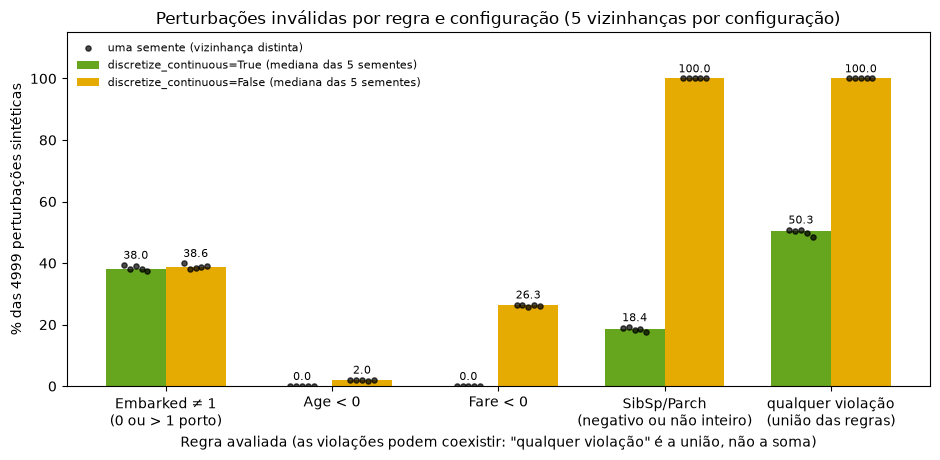

In [44]:
import matplotlib.pyplot as plt

PLOT = [('emb_invalid', 'Embarked ≠ 1\n(0 ou > 1 porto)'), ('age_neg', 'Age < 0'), ('fare_neg', 'Fare < 0'),
        ('cnt_invalid', 'SibSp/Parch\n(negativo ou não inteiro)'), ('any', 'qualquer violação\n(união das regras)')]
CFG = {True: ('#66a61e', 'discretize_continuous=True'), False: ('#e6ab02', 'discretize_continuous=False')}
fig, ax = plt.subplots(figsize=(9.5, 4.7))
w, off = 0.36, np.linspace(-0.07, 0.07, len(V_SEEDS))
for k, flag in enumerate(V_FLAGS):
    sub = hood.loc[flag]                                              # 5 linhas: uma vizinhança por semente
    xs = np.arange(len(PLOT)) + (k - 0.5) * w
    ax.bar(xs, [100 * sub[c].median() for c, _ in PLOT], w, color=CFG[flag][0], label=f'{CFG[flag][1]} (mediana das 5 sementes)')
    for xi, (c, _) in zip(xs, PLOT):
        ax.scatter(xi + off, 100 * sub[c], s=14, color='black', alpha=.7, zorder=3,
                   label='uma semente (vizinhança distinta)' if (k == 0 and c == PLOT[0][0]) else None)
        ax.text(xi, 100 * sub[c].max() + 2, f'{100 * sub[c].median():.1f}', ha='center', fontsize=8)
ax.set_xticks(np.arange(len(PLOT)), [n for _, n in PLOT])
ax.set_ylim(0, 115)
ax.set_ylabel('% das 4999 perturbações sintéticas')
ax.set_xlabel('Regra avaliada (as violações podem coexistir: "qualquer violação" é a união, não a soma)')
ax.set_title('Perturbações inválidas por regra e configuração (5 vizinhanças por configuração)')
ax.legend(fontsize=8, loc='upper left', frameon=False)
plt.tight_layout()
plt.show()

### Exemplos e relação descritiva com as previsões

Descritivo apenas: os grupos diferem em muitas características e uma diferença nas probabilidades não mostra que a invalidade as cause.

In [45]:
FLAGCOLS = ['emb_invalid', 'age_neg', 'fare_neg', 'cnt_neg', 'cnt_frac']
ex = []
for flag, rule in ((True, 'emb_multi'), (False, 'fare_neg')):
    exp, M, P = cap[(1095, flag, 123)]
    v = violations(M[1:])
    i = int(np.flatnonzero(v[rule].to_numpy())[0])                                # 1.ª linha sintética que viola a regra
    ex.append(pd.concat([pd.Series(M[1 + i], index=FEATURES), v.iloc[i][FLAGCOLS], pd.Series({'P(Survived)': P[1 + i, TARGET_CLASS]})])
              .rename(f'discretize={flag}, linha {1 + i}'))
display(pd.DataFrame(ex).round(4))
print('(exemplos do passageiro 1095, semente 123; 1.ª linha sintética que viola a regra indicada)')

# probabilidades do XGBoost nas perturbações (as mesmas probabilidades já obtidas durante as explicações)
pool = V_PIDS if not all(same.values()) else [V_PIDS[0]]          # com vizinhanças idênticas, um passageiro basta
print('Passageiros usados para esta comparação:', pool)
q = lambda s: f'{s.median():.3f} [{s.quantile(.25):.3f}–{s.quantile(.75):.3f}]'
rows_any, rows_type = [], []
for flag in V_FLAGS:
    Ps, Vs = [], []
    for pid in pool:
        for seed in V_SEEDS:
            exp, M, P = cap[(pid, flag, seed)]
            Ps.append(P[1:, TARGET_CLASS])
            Vs.append(violations(M[1:]))
    Pv, V = np.concatenate(Ps), pd.concat(Vs, ignore_index=True)
    rows_any.append({'discretize': flag, 'n total': len(Pv), 'n sem violações': int((~V['any']).sum()), 'n com violação': int(V['any'].sum()),
                     'P mediana [IQR] sem violações': q(pd.Series(Pv[~V['any'].to_numpy()])) if (~V['any']).any() else '— (grupo vazio)',
                     'P mediana [IQR] com violação': q(pd.Series(Pv[V['any'].to_numpy()]))})
    for rule, name in (('emb_invalid', 'Embarked ≠ 1'), ('age_neg', 'Age < 0'), ('fare_neg', 'Fare < 0'), ('cnt_invalid', 'SibSp/Parch inválido')):
        m = V[rule].to_numpy()
        rows_type.append({'discretize': flag, 'regra': name, 'n com': int(m.sum()), 'n sem': int((~m).sum()),
                          'P mediana [IQR] com': q(pd.Series(Pv[m])) if m.any() else '—', 'P mediana [IQR] sem': q(pd.Series(Pv[~m])) if (~m).any() else '—'})
print('Probabilidade prevista nas perturbações: sem violações vs com pelo menos uma')
display(pd.DataFrame(rows_any).set_index('discretize'))
print('Por regra (com vs sem a violação; os grupos sobrepõem-se)')
display(pd.DataFrame(rows_type).set_index(['discretize', 'regra']))

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S,emb_invalid,age_neg,fare_neg,cnt_neg,cnt_frac,P(Survived)
"discretize=True, linha 12",2.0,1.0,21.7740,0.0000,0.0000,13.1263,1.0,0.0,1.0,True,False,False,False,False,0.2891
"discretize=False, linha 3",3.0,1.0,17.4292,0.2852,-1.9249,-65.9294,0.0,0.0,0.0,True,False,True,True,True,0.0041


(exemplos do passageiro 1095, semente 123; 1.ª linha sintética que viola a regra indicada)
Passageiros usados para esta comparação: [1095]
Probabilidade prevista nas perturbações: sem violações vs com pelo menos uma


,n total,n sem violações,n com violação,P mediana [IQR] sem violações,P mediana [IQR] com violação
discretize,,,,,
True,24995,12479,12516,0.151 [0.010–0.890],0.219 [0.016–0.895]
False,24995,0,24995,— (grupo vazio),0.210 [0.015–0.934]


Por regra (com vs sem a violação; os grupos sobrepõem-se)


n com  n sem  P mediana [IQR] com  P mediana [IQR] sem
discretize regra                                                                       
True       Embarked ≠ 1           9583  15412  0.244 [0.019–0.903]  0.151 [0.010–0.884]
           Age < 0                   0  24995                    —  0.186 [0.013–0.892]
           Fare < 0                  0  24995                    —  0.186 [0.013–0.892]
           SibSp/Parch inválido   4626  20369  0.172 [0.012–0.871]  0.189 [0.013–0.895]
False      Embarked ≠ 1           9692  15303  0.241 [0.019–0.936]  0.192 [0.013–0.932]
           Age < 0                 478  24517  0.959 [0.672–0.987]  0.193 [0.014–0.927]
           Fare < 0               6551  18444  0.664 [0.040–0.978]  0.144 [0.011–0.869]
           SibSp/Parch inválido  24995      0  0.210 [0.015–0.934]                    —

In [46]:
# Validação da Atividade 6
# 1-3. 30 explicações, passageiros no teste, linha 0 = passageiro original
assert len(cap) == len(rates) == 30 == len(V_PIDS) * len(V_FLAGS) * len(V_SEEDS)
assert set(V_PIDS) <= set(X_test.index) and set(rates['pid']) == set(V_PIDS) and set(rates['seed']) == set(V_SEEDS)
for (pid, flag, seed), (exp, M, P) in cap.items():
    assert M.shape == (LIME_CONFIG['num_samples'], len(FEATURES)) and np.array_equal(M[0], X_test.loc[pid].values)
    assert set(exp.local_exp) == {TARGET_CLASS}

# 4. o wrapper não altera previsões: probabilidades registadas = predict_fn(dados registados); e as explicações são
#    iguais às obtidas sem wrapper (mesma semente)
for (pid, flag, seed), (exp, M, P) in cap.items():
    assert np.array_equal(P, predict_fn(M))
    plain = explain_passenger(build_explainer(seed, flag), pid, LIME_CONFIG['num_samples'], LIME_CONFIG['num_features'])
    assert summarize(plain, pid) == summarize(exp, pid)

# 5. colunas identificadas corretamente
assert [FEATURES[i] for i in EMB] == ['Embarked_C', 'Embarked_Q', 'Embarked_S'] and [FEATURES[i] for i in CNT] == ['SibSp', 'Parch']
assert FEATURES[IDX['Age']] == 'Age' and FEATURES[IDX['Fare']] == 'Fare'

# 6-8. taxas sem a linha original, em [0, 1], e 'qualquer' = união (recalculado com código independente)
for (pid, flag, seed), (exp, M, P) in cap.items():
    S = M[1:]
    r = rates[(rates['pid'] == pid) & (rates['discretize'] == flag) & (rates['seed'] == seed)].iloc[0]
    assert r['n_syn'] == len(S) == 4999 and not violations(M[:1])['any'].iloc[0]
    emb_bad = ~np.isclose(S[:, EMB].sum(axis=1), 1, rtol=0, atol=1e-9)
    cnt_bad = np.array([any(x < 0 or abs(x - round(x)) > 1e-6 for x in row) for row in S[:, CNT]])
    bad = emb_bad | (S[:, IDX['Age']] < 0) | (S[:, IDX['Fare']] < 0) | cnt_bad
    assert np.isclose(r['emb_invalid'], emb_bad.mean()) and np.isclose(r['cnt_invalid'], cnt_bad.mean())
    assert np.isclose(r['any'], bad.mean()) and max(r['emb_invalid'], r['age_neg'], r['fare_neg'], r['cnt_invalid']) <= r['any']
    assert np.isclose(r['emb_invalid'], r['emb_none'] + r['emb_multi'])
    assert np.isin(S[:, EMB], [0, 1]).all()                                                    # indicadores binários
    assert np.isin(S[:, IDX['Sex']], [0, 1]).all() and np.isin(S[:, IDX['Pclass']], [1, 2, 3]).all()   # Sex e Pclass sempre válidos
assert ((rates[[c for c, _ in COLS]] >= 0) & (rates[[c for c, _ in COLS]] <= 1)).all().all()

# 9. os dados reais (treino e teste) respeitam as regras
assert not violations(X_train.values)['any'].any() and not violations(X_test.values)['any'].any()
assert not violations(X.values)[['emb_invalid', 'age_neg', 'fare_neg', 'cnt_invalid']].any().any()

# 10. reprodutibilidade: mesma semente, mesmas perturbações capturadas
for key in [(1095, True, 123), (320, False, 7), (759, True, 1), (1095, False, 11)]:
    again = run_capture(*key)
    assert np.array_equal(again[1], cap[key][1]) and np.array_equal(again[2], cap[key][2])

# 11. atividades anteriores inalteradas
assert all(a.equals(b) for a, b in zip(snapshot6, (fid, fid13, table_a, table_b, freq3, runs, stat, stab, age_fare, sel)))
assert results[1095] == summarize(run_lime(1095), 1095) and list(fid.index) == ids20 == select_passengers()[0]
# 12. pseudorreplicação: vizinhanças idênticas entre passageiros => agregação por (discretize, semente)
assert all(same.values()) and SPREAD == 0
assert len(hood) == len(V_FLAGS) * len(V_SEEDS) == 10 and hood.index.is_unique
for (flag, seed), r in hood.iterrows():
    S = cap[(V_PIDS[0], flag, seed)][1][1:]
    assert np.isclose(r['any'], violations(S)['any'].mean()) and np.isclose(r['cnt_invalid'], violations(S)['cnt_invalid'].mean())
assert (hood['any'] >= hood[['emb_invalid', 'age_neg', 'fare_neg', 'cnt_invalid']].max(axis=1)).all()    # união >= cada regra
print('Validação da Atividade 6: OK')

Validação da Atividade 6: OK


### Observações (Atividade 6)

**Âmbito.** Tudo o que se segue vale para **esta configuração** (XGBoost fixo; `LimeTabularExplainer` com `sample_around_instance=False` e `num_samples=5000`; `SibSp` e `Parch` tratadas como contínuas), **este dataset** e **as regras avaliadas** (restrições lógicas simples). Não é uma propriedade do LIME em geral.

**Unidade de análise.** Com `sample_around_instance=False` (por omissão) a vizinhança que o XGBoost recebe não depende do passageiro: para a mesma semente e configuração, as linhas 1–4999 são idênticas nos três passageiros (verificado no notebook, diferença de taxa 0,0 p.p.). As 30 explicações são, portanto, **10 vizinhanças distintas**, e os três passageiros não são réplicas independentes. As taxas abaixo são medianas (mín–máx) sobre as **5 sementes** de cada configuração; entre sementes variam cerca de 1–3 pontos percentuais. Entre passageiros mudam a linha 0, a representação binária e os pesos do kernel, não a vizinhança.

**1. Que proporção viola restrições básicas?** Com `discretize_continuous=True`, **50,3%** (48,6–50,9%) das perturbações violam pelo menos uma regra. Com `False`, **100%** (nas 5 sementes).

**Contexto do 100% com `False`.** Decorre principalmente de `SibSp` e `Parch` serem tratados como contínuos apesar de serem contagens inteiras: sem discretização são amostrados de uma Normal e nenhuma das 4999 perturbações tem ambos os valores inteiros, pelo que só esta regra já dá 100%. As outras regras (`Embarked ≠ 1` 38,6%, `Fare < 0` 26,3%, `Age < 0` 2,0%) acrescentam violações, mas não são necessárias para chegar a 100%. Isto **não** é uma propriedade universal do LIME nem de todas as configurações sem discretização: com outra representação das features (por exemplo, `SibSp`/`Parch` declaradas categóricas) ou outra estratégia de geração de perturbações, a taxa poderia ser muito diferente. Isso não foi testado aqui, e o explainer não foi alterado.

**2. Que regras são mais violadas?** Com `True`: `Embarked ≠ 1` em 38,0% (nenhum porto 19,4%, mais de um 18,8%) e `SibSp`/`Parch` não inteiros em 18,4% (nunca negativos); `Age < 0` e `Fare < 0` em 0%. Com `False`: `SibSp`/`Parch` inválidos em 100% (todos não inteiros, 50,0% com algum valor negativo), `Embarked ≠ 1` em 38,6%, `Fare < 0` em 26,3% e `Age < 0` em 2,0%. Como diagnóstico à parte, fora do intervalo do treino (não classificado como impossível): `Age` 2,0%, `Fare` 26,3%, `SibSp` 29%, `Parch` 30,5% com `False`, e 0% em todas com `True`.

**3. A discretização afeta a plausibilidade?** Nesta configuração, sim, mas não a elimina. Reduz a taxa total de 100% para cerca de 50% e elimina idades, tarifas e contagens negativas, porque cada contínua discretizada é re-amostrada dentro de um intervalo observado no treino. Não altera os problemas de `Embarked` (38,0% vs 38,6%: os três indicadores são sorteados de forma independente nas duas configurações) e mantém 18,4% de contagens fracionárias (valores amostrados dentro do intervalo, por exemplo `SibSp = 0,29`). Exemplos do passageiro 1095 (semente 123): com `True`, uma linha com `Embarked_C = 1` e `Embarked_S = 1` e `P = 0,289`; com `False`, uma linha com `Parch = −1,92`, `Fare = −65,93`, nenhum porto e `P = 0,004`.

**Probabilidades do modelo (descritivo).** Com `True`, sem violações (n = 12 479) a P mediana é 0,151 [IQR 0,010–0,890] e com violação (n = 12 516) 0,219 [0,016–0,895]: distribuições largas e semelhantes. Com `False` não existe nenhuma perturbação sem violações (grupo vazio), pelo que essa comparação não é possível. Por regra, com `False`: `Age < 0` (n = 478) tem P mediana 0,959 contra 0,193 sem a violação, e `Fare < 0` (n = 6551) 0,664 contra 0,144. Os grupos diferem em muitas outras características e não se sabe porquê; não se atribui a diferença à invalidade. Os n contam perturbações das 5 vizinhanças distintas (5 × 4999 por configuração).

**4. Implicações para interpretar o LIME.** Nesta configuração, em metade das linhas (`True`) ou em todas (`False`) o XGBoost é consultado em perfis logicamente impossíveis, e é com essas respostas que o substituto linear é ajustado; o modelo não tem suporte de dados reais nessas regiões, e os pesos (por exemplo o de `Embarked_C`) descrevem uma vizinhança que inclui passageiros sem porto ou com dois portos. A discretização torna a vizinhança mais plausível segundo estas regras, mas não a torna realista. As violações são evidência de **problemas de plausibilidade**; **não provam** que sejam a causa do R² moderado e dos erros observados nas Atividades 1–5.

**Limites.** (i) Só há 5 vizinhanças distintas por configuração (uma por semente): três passageiros não aumentam a amostra. (ii) Só avaliei restrições lógicas simples; combinações impossíveis ou improváveis entre outras features (por exemplo `Fare` com `Pclass`) não foram avaliadas, por isso as taxas são um limite inferior de implausibilidade. (iii) O resultado de 100% depende de `SibSp`/`Parch` serem contínuas; outras representações ou estratégias de perturbação podem dar resultados diferentes. (iv) Não houve experiência controlada (seria preciso, por exemplo, comparar com uma vizinhança restrita a perfis válidos), logo não se pode atribuir a fidelidade moderada a estas violações.

## Atividade 7 — Discussão: porque difere a explicação e o que verificar antes de a usar

O enunciado pede duas respostas: **(1)** porque pode o LIME dar explicações diferentes ao mesmo passageiro, mesmo quando a previsão do modelo não muda; **(2)** o que verificar antes de mostrar uma explicação a quem vai decidir com base nela. Em vez de responder só por argumentação, medem-se as duas coisas, reutilizando as Atividades 1–6.

**Porque interessa.** Se a explicação muda por razões que nada têm a ver com o modelo (semente, número de amostras, representação, largura do kernel), quem a lê pode atribuir ao modelo o que é efeito da configuração do LIME. Medir *quanto* muda, e se esse efeito se deteta com verificações baratas, indica que verificações valem a pena.

**Duas quantidades que não se misturam.** (a) **Variabilidade entre sementes**: Jaccard entre as seleções de duas sementes *diferentes* na mesma configuração (45 pares por configuração). (b) **Sensibilidade à configuração**: Jaccard entre a variante e a referência com a **mesma semente** (10 pares emparelhados). A mesma semente controla a inicialização aleatória, mas **não garante perturbações idênticas** quando os mecanismos de geração diferem (por exemplo com e sem discretização); o emparelhamento reduz o ruído da comparação, não é uma experiência causal perfeita.

**Parte A — fontes de variação (passageiro 1095).** P(Survived) = 0,0753 fica fixa, logo qualquer diferença vem do LIME e não do modelo. Parte-se da configuração de referência (`discretize_continuous=True`, `kernel_width` por omissão = 2,25, `num_samples=5000`, `num_features=5`) e varia-se **um fator de cada vez**: `num_samples` ∈ {500, 1000} (Atividade 3, reutilizadas), `discretize_continuous=False` e `kernel_width` ∈ {0,75; 6,75} (um terço e o triplo do valor por omissão), estes três com as mesmas 10 sementes `[123, 1, …, 9]` (30 explicações novas). O 1095 mantém-se por ser o caso difícil já estudado; é um só passageiro, logo exploratório. Como o top-5 é escolhido entre 9 features, dois conjuntos sorteados ao acaso têm Jaccard médio ≈ 0,40; é apenas uma referência ilustrativa que supõe todos os conjuntos equiprováveis, não um critério para dizer que uma seleção é aleatória.

**Parte B — verificações antes de mostrar a explicação.** Quatro verificações, cada uma ligada a uma atividade: (i) fidelidade no ponto (`|P − local_pred|`, R², `local_pred` do outro lado de 0,5; Atividade 2); (ii) estabilidade da seleção entre 10 sementes (Atividade 3); (iii) sensibilidade à representação: para cada um dos **20 passageiros da Atividade 1**, 10 explicações com `True` e 10 com `False` **com as mesmas sementes**, comparadas aos pares; (iv) plausibilidade da vizinhança (Atividade 6, igual para todos os passageiros porque a vizinhança não depende deles). Três passageiros são ilustrados por regra fixa (menor erro, erro mediano, maior erro).

**Hipóteses (formuladas antes da análise; mantêm-se tal como foram escritas; descritivas, n pequeno).**
- **H1.** Mudar a representação ou o `kernel_width` altera o conjunto de features mais do que mudar a semente.
- **H2.** A estabilidade da seleção entre sementes não é um indicador de fidelidade: há passageiros com seleção estável e erro grande (como o 1095 na Atividade 3).
- **H3.** Para a maioria dos passageiros, a mudança de `True` para `False` altera a seleção mais do que a semente.

**Revisão metodológica.** A primeira versão desta atividade comparava cada variante com a referência usando todas as combinações de sementes (100 comparações, só 10 com a mesma semente) e, na Parte B, comparava as 10 explicações `True` com uma única `False` (semente 123). Isso mistura efeito da configuração com variabilidade aleatória; a versão atual usa pares com a mesma semente. As hipóteses não foram alteradas; as conclusões foram reavaliadas com as novas medições.

**Limites previstos.** Passageiros aleatórios e não estratificados (nenhum incerto), um modelo, um dataset, 5000 amostras, top-5 de 9 features; sem testes de significância; só se comparam seleções e sinais entre representações diferentes, nunca a magnitude dos coeficientes (Atividade 4).

In [47]:
from collections import Counter
from itertools import combinations

KW_DEFAULT = 0.75 * np.sqrt(len(FEATURES))             # 2,25: valor por omissão do LIME com 9 features
A7_ID = STAB_ID                                         # 1095
snapshot7 = [d.copy() for d in (fid, fid13, runs, stat, stab, age_fare, hood)]


def run_variant(pid, seed, discretize=True, kernel_width=None, num_samples=LIME_CONFIG['num_samples']):
    explainer = build_explainer(seed, discretize, kernel_width)           # explainer novo por explicação
    return explain_passenger(explainer, pid, num_samples, LIME_CONFIG['num_features'])


sel_set = lambda e: frozenset(FEATURES[i] for i, _ in e.local_exp[TARGET_CLASS])
lp = lambda e: float(np.ravel(e.local_pred)[0])
jac = lambda a, b: len(a & b) / len(a | b)
seed_pairs = lambda sets_: [jac(a, b) for a, b in combinations(sets_, 2)]      # sementes diferentes, mesma configuração (45)
same_seed = lambda s1, s2: [jac(a, b) for a, b in zip(s1, s2)]                  # mesma semente (listas pela ordem de STAB_SEEDS)

VARIANT_ARGS = {'discretize=False': dict(discretize=False), 'kernel_width=0,75': dict(kernel_width=KW_DEFAULT / 3),
                'kernel_width=6,75': dict(kernel_width=KW_DEFAULT * 3)}
VARIANTS = {
    'referência': [stab_exps[(5000, s)] for s in STAB_SEEDS],
    'num_samples=500': [stab_exps[(500, s)] for s in STAB_SEEDS],
    'num_samples=1000': [stab_exps[(1000, s)] for s in STAB_SEEDS],
    **{k: [run_variant(A7_ID, s, **a) for s in STAB_SEEDS] for k, a in VARIANT_ARGS.items()},
}
sets = {k: [sel_set(e) for e in v] for k, v in VARIANTS.items()}
ALL5 = [frozenset(c) for c in combinations(FEATURES, 5)]
CHANCE = float(np.mean([jac(a, b) for a in ALL5 for b in ALL5]))       # só ilustrativo: 2 conjuntos de 5 equiprováveis entre 9
P1095 = float(VARIANTS['referência'][0].predict_proba[TARGET_CLASS])

seed_j = {k: seed_pairs(s) for k, s in sets.items()}                                                   # variabilidade entre sementes
pair_j = {k: same_seed(s, sets['referência']) for k, s in sets.items() if k != 'referência'}          # sensibilidade à configuração

rows = []
for k in VARIANTS:
    r = {'variante': k, 'conjuntos distintos': len(set(sets[k])), 'entre sementes (45 pares): média': np.mean(seed_j[k]),
         'mín': np.min(seed_j[k]), 'máx': np.max(seed_j[k])}
    if k != 'referência':
        r.update({'mesma semente vs referência (10 pares): média': np.mean(pair_j[k]), 'mediana': np.median(pair_j[k]),
                  'mín ': np.min(pair_j[k]), 'máx ': np.max(pair_j[k])})
    rows.append(r)
sel_tab = pd.DataFrame(rows).set_index('variante')
print('P(Survived) do passageiro %d = %.4f em todas | Jaccard ilustrativo de 2 conjuntos ao acaso (equiprováveis) = %.3f' % (A7_ID, P1095, CHANCE))
print('Seleção de features: variabilidade entre sementes (dentro de cada configuração) vs sensibilidade à configuração (mesma semente)')
display(sel_tab.round(3).astype(object).where(sel_tab.notna(), '—'))

rows = []
for k, v in VARIANTS.items():
    lps = np.array([lp(e) for e in v])
    rows.append({'variante': k, 'local_pred média': lps.mean(), 'local_pred mín': lps.min(), 'local_pred máx': lps.max(),
                 'local_pred ≥ 0,5 (de 10)': int((lps >= 0.5).sum()), 'R² médio': np.mean([e.score for e in v]),
                 'erro absoluto médio': np.abs(P1095 - lps).mean()})
fid_tab = pd.DataFrame(rows).set_index('variante')
print('Fidelidade em cada variante (P(Survived) = %.4f)' % P1095)
display(fid_tab.round(3))

freq = pd.DataFrame({k: pd.Series(Counter(f for s in v for f in s)) for k, v in sets.items()}).reindex(FEATURES).fillna(0).astype(int)
print('Nº de execuções (em 10) em que cada feature entra no top 5')
display(freq[freq.sum(axis=1) > 0])

P(Survived) do passageiro 1095 = 0.0753 em todas | Jaccard ilustrativo de 2 conjuntos ao acaso (equiprováveis) = 0.402
Seleção de features: variabilidade entre sementes (dentro de cada configuração) vs sensibilidade à configuração (mesma semente)


,conjuntos distintos,entre sementes (45 pares): média,mín,máx,mesma semente vs referência (10 pares): média,mediana,mín,máx
variante,,,,,,,,
referência,2,0.822,0.667,1.0,—,—,—,—
num_samples=500,4,0.726,0.667,1.0,0.767,0.667,0.667,1.0
num_samples=1000,6,0.725,0.429,1.0,0.767,0.667,0.667,1.0
discretize=False,1,1.0,1.0,1.0,0.429,0.429,0.429,0.429
"kernel_width=0,75",3,0.763,0.667,1.0,0.767,0.667,0.667,1.0
"kernel_width=6,75",3,0.785,0.667,1.0,0.967,1.0,0.667,1.0


Fidelidade em cada variante (P(Survived) = 0.0753)


,local_pred média,local_pred mín,local_pred máx,"local_pred ≥ 0,5 (de 10)",R² médio,erro absoluto médio
variante,,,,,,
referência,0.567,0.527,0.595,10,0.459,0.492
num_samples=500,0.557,0.494,0.600,9,0.467,0.481
num_samples=1000,0.570,0.522,0.591,10,0.466,0.494
discretize=False,0.620,0.596,0.632,10,0.518,0.544
"kernel_width=0,75",0.545,0.492,0.608,9,0.413,0.470
"kernel_width=6,75",0.569,0.529,0.588,10,0.460,0.494


Nº de execuções (em 10) em que cada feature entra no top 5


,referência,num_samples=500,num_samples=1000,discretize=False,"kernel_width=0,75","kernel_width=6,75"
Pclass,10,10,10,10,10,10
Sex,10,10,10,10,10,10
Age,0,0,1,10,4,0
SibSp,10,10,9,0,10,10
Parch,4,2,6,0,0,4
Fare,0,2,2,10,2,0
Embarked_C,10,10,10,10,10,10
Embarked_Q,6,3,1,0,4,5
Embarked_S,0,3,1,0,0,1


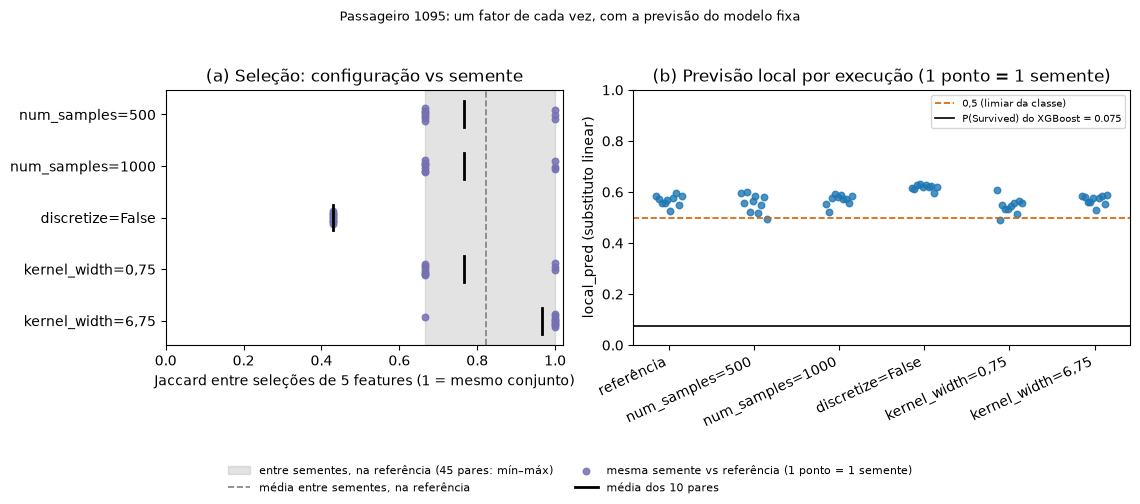

In [48]:
import matplotlib.pyplot as plt

OTHERS = [k for k in VARIANTS if k != 'referência']
ref_lo, ref_mean, ref_hi = min(seed_j['referência']), np.mean(seed_j['referência']), max(seed_j['referência'])
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 5.0), gridspec_kw={'width_ratios': [1, 1.25]})
ax1.axvspan(ref_lo, ref_hi, color='gray', alpha=.22, label='entre sementes, na referência (45 pares: mín–máx)')
ax1.axvline(ref_mean, color='gray', ls='--', lw=1.2, label='média entre sementes, na referência')
yy = np.arange(len(OTHERS))[::-1]
for y, k in zip(yy, OTHERS):
    ax1.scatter(pair_j[k], y + np.linspace(-0.12, 0.12, len(pair_j[k])), s=22, color='#7570b3', alpha=.85,
                label='mesma semente vs referência (1 ponto = 1 semente)' if k == OTHERS[0] else None)
    ax1.plot([np.mean(pair_j[k])] * 2, [y - 0.25, y + 0.25], color='black', lw=2, label='média dos 10 pares' if k == OTHERS[0] else None)
ax1.set_yticks(yy, OTHERS)
ax1.set_xlim(0, 1.02)
ax1.set_xlabel('Jaccard entre seleções de 5 features (1 = mesmo conjunto)')
ax1.set_title('(a) Seleção: configuração vs semente')

for k, name in enumerate(VARIANTS):
    y = [lp(e) for e in VARIANTS[name]]
    ax2.scatter(k + np.linspace(-0.15, 0.15, len(y)), y, s=22, color='#1f77b4', alpha=.8)
ax2.axhline(0.5, color='#d95f02', ls='--', lw=1.2, label='0,5 (limiar da classe)')
ax2.axhline(P1095, color='black', lw=1.2, label=f'P(Survived) do XGBoost = {P1095:.3f}')
ax2.set_xticks(range(len(VARIANTS)), list(VARIANTS), rotation=25, ha='right')
ax2.set_ylim(0, 1)
ax2.set_ylabel('local_pred (substituto linear)')
ax2.set_title('(b) Previsão local por execução (1 ponto = 1 semente)')
ax2.legend(fontsize=7, loc='upper right')
fig.suptitle(f'Passageiro {A7_ID}: um fator de cada vez, com a previsão do modelo fixa', fontsize=9)
fig.legend(*ax1.get_legend_handles_labels(), loc='lower center', ncol=2, fontsize=8, frameon=False)
plt.tight_layout(rect=(0, 0.11, 1, 0.95))
plt.show()

In [49]:
err = fid['Abs error'].sort_values(kind='stable')
CHECK_PIDS = [int(err.index[0]), int(err.index[len(err) // 2 - 1]), int(err.index[-1])]     # menor, mediano e maior erro (regra fixa)

rows, expsB = [], {}                                                       # expsB: explicações True, reutilizadas no complemento de localidade
for pid in ids20:
    rs = results[pid]
    ex = [run_variant(pid, s) for s in STAB_SEEDS]                          # 10 sementes, discretize=True (referência)
    exf = [run_variant(pid, s, discretize=False) for s in STAB_SEEDS]       # as mesmas 10 sementes, discretize=False
    expsB[pid] = ex
    st, stf = [sel_set(e) for e in ex], [sel_set(e) for e in exf]
    lps, lpf = np.array([lp(e) for e in ex]), np.array([lp(e) for e in exf])
    side = rs['p_model'] >= 0.5
    sj, pj = seed_pairs(st), same_seed(st, stf)
    rows.append({'PassengerId': pid, 'P(Survived)': rs['p_model'], 'R² (123)': rs['r2'],
                 '|P − local_pred| (123)': abs(rs['p_model'] - rs['local_pred']),
                 'erro médio (10 sementes)': np.abs(rs['p_model'] - lps).mean(),
                 'Jaccard sementes': np.mean(sj), 'sementes mín': np.min(sj), 'conjuntos distintos': len(set(st)),
                 'Jaccard emparelhado (média)': np.mean(pj), 'emparelhado mín': np.min(pj), 'emparelhado máx': np.max(pj),
                 'False: conjuntos distintos': len(set(stf)),
                 'cruza 0,5 com True (de 10)': int(((lps >= 0.5) != side).sum()), 'cruza 0,5 com False (de 10)': int(((lpf >= 0.5) != side).sum())})
chk = pd.DataFrame(rows).set_index('PassengerId')

print('Verificações (i)–(iii) nos 3 passageiros ilustrados (menor, mediano e maior erro)')
display(chk.loc[CHECK_PIDS].round(3))
fmt = lambda s: f'{s.median():.3f} ({s.min():.3f}–{s.max():.3f})'
print('Resumo nos 20 passageiros: mediana (mín–máx)')
display(chk.drop(columns=['sementes mín', 'emparelhado mín', 'emparelhado máx']).apply(fmt).to_frame('mediana (mín–máx)'))
sp = lambda a, b: chk[a].corr(chk[b], method='spearman')
print('Spearman (n = 20): Jaccard sementes vs erro médio %.2f | Jaccard sementes vs R² (123) %.2f' % (
    sp('Jaccard sementes', 'erro médio (10 sementes)'), sp('Jaccard sementes', 'R² (123)')))
diff = chk['Jaccard sementes'] - chk['Jaccard emparelhado (média)']
print('Sensibilidade à representação vs variabilidade entre sementes (n = 20): emparelhado < sementes em %d, igual em %d, maior em %d' % (
    (diff > 0).sum(), (diff == 0).sum(), (diff < 0).sum()))
print('Diferença (sementes − emparelhado): mediana %.3f (mín %.3f, máx %.3f) | emparelhado com mín < sementes mín em %d de 20' % (
    diff.median(), diff.min(), diff.max(), (chk['emparelhado mín'] < chk['sementes mín']).sum()))
print('Passageiros cuja local_pred cruza 0,5 em ≥ 1 semente: True %d | False %d' % (
    (chk['cruza 0,5 com True (de 10)'] > 0).sum(), (chk['cruza 0,5 com False (de 10)'] > 0).sum()))
print('Plausibilidade (Atividade 6, igual para todos): perturbações com violação, discretize=True: %.1f%% (mediana de 5 sementes)' % (100 * hood.loc[True, 'any'].median()))

Verificações (i)–(iii) nos 3 passageiros ilustrados (menor, mediano e maior erro)


,P(Survived),R² (123),|P − local_pred| (123),erro médio (10 sementes),Jaccard sementes,sementes mín,conjuntos distintos,Jaccard emparelhado (média),emparelhado mín,emparelhado máx,False: conjuntos distintos,"cruza 0,5 com True (de 10)","cruza 0,5 com False (de 10)"
PassengerId,,,,,,,,,,,,,
61,0.277,0.436,0.010,0.021,0.756,0.667,3,0.500,0.429,0.667,1,0,0
585,0.984,0.386,0.215,0.217,0.844,0.667,2,0.411,0.250,0.429,2,0,0
1095,0.075,0.457,0.508,0.492,0.822,0.667,2,0.429,0.429,0.429,1,10,10


Resumo nos 20 passageiros: mediana (mín–máx)


,mediana (mín–máx)
P(Survived),0.090 (0.000–1.000)
R² (123),0.439 (0.376–0.491)
|P − local_pred| (123),0.216 (0.010–0.508)
erro médio (10 sementes),0.219 (0.016–0.492)
Jaccard sementes,0.933 (0.741–1.000)
conjuntos distintos,2.000 (1.000–4.000)
Jaccard emparelhado (média),0.667 (0.411–1.000)
False: conjuntos distintos,1.000 (1.000–2.000)
"cruza 0,5 com True (de 10)",0.000 (0.000–10.000)
"cruza 0,5 com False (de 10)",0.000 (0.000–10.000)


Spearman (n = 20): Jaccard sementes vs erro médio 0.18 | Jaccard sementes vs R² (123) 0.47
Sensibilidade à representação vs variabilidade entre sementes (n = 20): emparelhado < sementes em 16, igual em 2, maior em 2
Diferença (sementes − emparelhado): mediana 0.267 (mín -0.033, máx 0.471) | emparelhado com mín < sementes mín em 12 de 20
Passageiros cuja local_pred cruza 0,5 em ≥ 1 semente: True 1 | False 2
Plausibilidade (Atividade 6, igual para todos): perturbações com violação, discretize=True: 50.3% (mediana de 5 sementes)


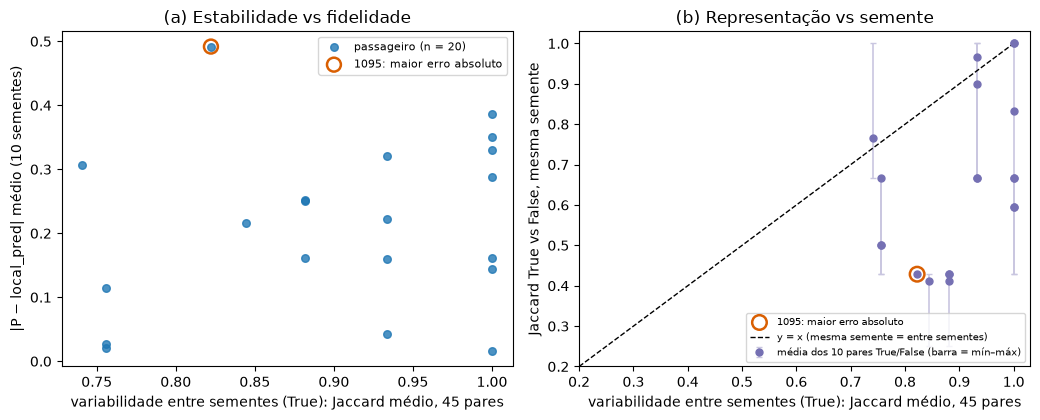

In [50]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 4.3))
ax1.scatter(chk['Jaccard sementes'], chk['erro médio (10 sementes)'], s=30, color='#1f77b4', alpha=.8, label='passageiro (n = 20)')
ax1.scatter(chk.loc[[A7_ID], 'Jaccard sementes'], chk.loc[[A7_ID], 'erro médio (10 sementes)'], s=100, facecolors='none',
            edgecolors='#d95f02', linewidths=1.8, label=f'{A7_ID}: maior erro absoluto')
ax1.set_ylabel('|P − local_pred| médio (10 sementes)')
ax1.set_title('(a) Estabilidade vs fidelidade')

yv = chk['Jaccard emparelhado (média)']
ax2.errorbar(chk['Jaccard sementes'], yv, yerr=[(yv - chk['emparelhado mín']).clip(lower=0), (chk['emparelhado máx'] - yv).clip(lower=0)], fmt='o', ms=5, color='#7570b3',
             ecolor='#c9c6e0', elinewidth=1.2, capsize=2, label='média dos 10 pares True/False (barra = mín–máx)')
ax2.scatter(chk.loc[[A7_ID], 'Jaccard sementes'], yv.loc[[A7_ID]], s=110, facecolors='none', edgecolors='#d95f02', linewidths=1.8,
            label=f'{A7_ID}: maior erro absoluto')
ax2.plot([0.2, 1], [0.2, 1], color='black', ls='--', lw=1, label='y = x (mesma semente = entre sementes)')
ax2.set_xlim(0.2, 1.03)
ax2.set_ylim(0.2, 1.03)
ax2.set_ylabel('Jaccard True vs False, mesma semente')
ax2.set_title('(b) Representação vs semente')
for ax in (ax1, ax2):
    ax.set_xlabel('variabilidade entre sementes (True): Jaccard médio, 45 pares')
ax1.legend(fontsize=8, loc='upper right')
ax2.legend(fontsize=7, loc='lower right')
plt.tight_layout()
plt.show()

In [51]:
# Validação da Atividade 7
assert A7_ID == int(fid['Abs error'].idxmax()) == 1095

# kernel_width: o valor por omissão é 2,25 e os valores pedidos são realmente aplicados
assert np.isclose(KW_DEFAULT, 2.25) and np.isclose(build_explainer(1, True).base.kernel_fn.keywords['kernel_width'], KW_DEFAULT)
for kw in (KW_DEFAULT / 3, KW_DEFAULT * 3):
    assert build_explainer(1, True, kw).base.kernel_fn.keywords['kernel_width'] == kw

# a configuração de referência reproduz exatamente a Atividade 1/3 (kernel_width=None não altera nada)
assert summarize(run_variant(A7_ID, 123), A7_ID) == results[A7_ID] and VARIANTS['referência'][0] is stab_exps[(5000, 123)]

# 6 variantes × 10 sementes, mesmo passageiro e mesma previsão do XGBoost, 5 features, só a classe Survived
p_ref = predict_fn(X_test.loc[[A7_ID]].values)[0]
for k, v in VARIANTS.items():
    assert len(v) == 10 and all(np.array_equal(np.asarray(e.predict_proba), p_ref) for e in v)
    assert all(len(s) == 5 for s in sets[k]) and all(set(e.local_exp) == {TARGET_CLASS} for e in v)

# emparelhamento (parte A): a posição i de cada variante usa a semente STAB_SEEDS[i], igual à da referência
for i, s in enumerate(STAB_SEEDS):
    assert VARIANTS['referência'][i] is stab_exps[(5000, s)] and VARIANTS['num_samples=500'][i] is stab_exps[(500, s)]
    assert VARIANTS['num_samples=1000'][i] is stab_exps[(1000, s)]
    for k, a in VARIANT_ARGS.items():                                      # recálculo por outro caminho, com a mesma semente
        if 'kernel_width' in a:
            e = explain_passenger(build_explainer(s, True, a['kernel_width']), A7_ID, LIME_CONFIG['num_samples'], LIME_CONFIG['num_features'])
        else:
            e = run_lime(A7_ID, random_state=s, discretize_continuous=a['discretize'])
        assert sel_set(e) == sets[k][i] and lp(e) == lp(VARIANTS[k][i])
for k in pair_j:
    assert len(pair_j[k]) == 10 and all(0 <= x <= 1 for x in pair_j[k])
    manual = [len(sets[k][i] & sets['referência'][i]) / len(sets[k][i] | sets['referência'][i]) for i in range(10)]
    assert np.allclose(pair_j[k], manual) and np.isclose(sel_tab.loc[k, 'mesma semente vs referência (10 pares): média'], np.mean(manual))
    assert np.isclose(sel_tab.loc[k, 'mediana'], np.median(manual))
for k in VARIANTS:                                                          # variabilidade entre sementes: 45 pares, = mean_jaccard da Atividade 3
    assert len(seed_j[k]) == 45 and np.isclose(np.mean(seed_j[k]), mean_jaccard(sets[k])[0])
assert np.isclose(np.mean(seed_j['referência']), stab.loc[5000, 'Jaccard médio']) and np.isclose(np.mean(seed_j['num_samples=500']), stab.loc[500, 'Jaccard médio'])
assert len(ALL5) == 126 and np.isclose(CHANCE, 0.402, atol=0.001) and (freq.sum(axis=0) == 5 * 10).all()

# parte B: 20 passageiros, 10 sementes True e as mesmas 10 sementes com False
assert list(chk.index) == ids20 and len(CHECK_PIDS) == 3 and A7_ID in CHECK_PIDS
assert np.array_equal(chk['R² (123)'], fid['Local R2']) and np.allclose(chk['|P − local_pred| (123)'], fid['Abs error'], rtol=0, atol=1e-12)
for pid in CHECK_PIDS:                                                      # recálculo por outro caminho (run_lime), semente a semente
    stT = [frozenset(f for f, _ in summarize(run_lime(pid, random_state=s), pid)['weights']) for s in STAB_SEEDS]
    stF = [frozenset(f for f, _ in summarize(run_lime(pid, random_state=s, discretize_continuous=False), pid)['weights']) for s in STAB_SEEDS]
    pj = [len(a & b) / len(a | b) for a, b in zip(stT, stF)]                 # mesma semente, mesma posição
    assert np.isclose(chk.loc[pid, 'Jaccard emparelhado (média)'], np.mean(pj)) and np.isclose(chk.loc[pid, 'emparelhado mín'], min(pj))
    assert np.isclose(chk.loc[pid, 'emparelhado máx'], max(pj)) and chk.loc[pid, 'False: conjuntos distintos'] == len(set(stF))
    assert np.isclose(chk.loc[pid, 'Jaccard sementes'], mean_jaccard(stT)[0]) and chk.loc[pid, 'conjuntos distintos'] == len(set(stT))
assert np.isclose(chk.loc[A7_ID, 'Jaccard sementes'], stab.loc[5000, 'Jaccard médio'])           # igual à Atividade 3
assert np.isclose(chk.loc[A7_ID, 'Jaccard emparelhado (média)'], np.mean(pair_j['discretize=False']))   # 1095: parte B = parte A
assert chk[['Jaccard sementes', 'sementes mín', 'Jaccard emparelhado (média)', 'emparelhado mín', 'emparelhado máx']].apply(lambda c: c.between(0, 1)).all().all()
assert ((chk['emparelhado mín'] - 1e-12 <= chk['Jaccard emparelhado (média)']) & (chk['Jaccard emparelhado (média)'] <= chk['emparelhado máx'] + 1e-12)).all()
assert hood.loc[True, 'any'].between(0, 1).all()

# atividades anteriores inalteradas
assert all(a.equals(b) for a, b in zip(snapshot7, (fid, fid13, runs, stat, stab, age_fare, hood)))
assert results[A7_ID] == summarize(run_lime(A7_ID), A7_ID) and list(fid.index) == ids20 == select_passengers()[0]
print('Validação da Atividade 7: OK')

Validação da Atividade 7: OK


### Complemento: localidade dos coeficientes

A Atividade 6 mostrou que, com a mesma configuração e semente, as perturbações enviadas ao XGBoost são iguais para todos os passageiros (exceto a linha da instância). Isso **não** torna as explicações globais: a representação binária usada no ajuste (1 = mesmo intervalo ou categoria que o passageiro) e as distâncias do kernel dependem do passageiro explicado. Mede-se aqui, sem novas explicações, quanto varia o coeficiente de uma **mesma condição concreta**. `Sex=female` e `Sex=male` são condições distintas e nunca se misturam.

- **Entre passageiros:** semente e configuração fixas. Amplitude (máx − mín) entre os passageiros cuja explicação inclui a condição, calculada em cada uma das 10 sementes.
- **Entre sementes:** passageiro e configuração fixos. Amplitude entre as 10 sementes, só para passageiros com a condição nas 10.

**Dados:** as 200 explicações `discretize_continuous=True` da parte B (20 passageiros da Atividade 1 × 10 sementes, `num_samples=5000`, `num_features=5`). A semente 123 reproduz a Atividade 1 e o 1095 reproduz a Atividade 3. Só entram condições com ≥ 5 passageiros em cada semente e ≥ 5 passageiros com a condição nas 10 sementes. Os 13 da Atividade 2b ficam de fora porque só têm a semente 123. Uma condição fora do top 5 não tem peso observado, o que é diferente de peso zero.


In [52]:
# Coeficiente de uma mesma condição: entre passageiros (semente fixa) vs entre sementes (passageiro fixo).
# Reutiliza as 200 explicações True da parte B (expsB); não gera explicações novas.
import inspect
import lime.lime_tabular as lime_tabular

LOC_MIN = 5                                                    # mínimo de observações por grupo (só descritivo)
loc_df = pd.DataFrame([dict(PassengerId=pid, seed=s, condição=c, peso=w)
                       for pid, ex in expsB.items() for s, e in zip(STAB_SEEDS, ex) for c, w in e.as_list(label=TARGET_CLASS)])
amp = lambda s: s.max() - s.min()
by_seed = loc_df.groupby(['condição', 'seed'])['peso'].agg(n='size', amplitude=amp)        # semente fixa: entre passageiros
by_pid = loc_df.groupby(['condição', 'PassengerId'])['peso'].agg(n='size', amplitude=amp)  # passageiro fixo: entre sementes
by_pid10 = by_pid[by_pid['n'] == len(STAB_SEEDS)]                                            # condição presente nas 10 sementes
n_seed = by_seed['n'].groupby('condição').agg(['min', 'max', 'size'])
n_pid10 = by_pid10.groupby('condição').size()
eligible = [c for c in n_seed.index if n_seed.loc[c, 'size'] == len(STAB_SEEDS) and n_seed.loc[c, 'min'] >= LOC_MIN
            and n_pid10.get(c, 0) >= LOC_MIN]

loc_tab = pd.DataFrame({
    'peso médio': loc_df.groupby('condição')['peso'].mean(),
    'n passageiros por semente': n_seed.apply(lambda r: f"{int(r['min'])}–{int(r['max'])}", axis=1),
    'entre passageiros: amplitude mediana': by_seed['amplitude'].groupby('condição').median(),
    'entre passageiros: amplitude máx': by_seed['amplitude'].groupby('condição').max(),
    'n passageiros (10/10 sementes)': n_pid10,
    'entre sementes: amplitude mediana': by_pid10['amplitude'].groupby('condição').median(),
    'entre sementes: amplitude máx': by_pid10['amplitude'].groupby('condição').max(),
}).loc[eligible].astype({'n passageiros (10/10 sementes)': int}).sort_values('peso médio')
print('Amplitude (máx − mín) do coeficiente de cada condição. Entre passageiros: mediana e máximo sobre as 10 sementes;')
print('entre sementes: mediana e máximo sobre os passageiros com a condição nas 10 sementes.')
display(loc_tab.round(3))
print('Condições excluídas por terem poucas observações:', sorted(set(n_seed.index) - set(eligible)))
lower = int((loc_tab['entre passageiros: amplitude mediana'] < loc_tab['entre sementes: amplitude mediana']).sum())
print(f'Amplitude mediana entre passageiros < entre sementes em {lower} de {len(loc_tab)} condições')

# Mecanismo do kernel, lido no código instalado e confirmado no explainer usado
src_init = inspect.getsource(lime_tabular.LimeTabularExplainer.__init__)
src_expl = inspect.getsource(lime_tabular.LimeTabularExplainer.explain_instance)
assert 'kernel_width = np.sqrt(training_data.shape[1]) * .75' in src_init
assert 'return np.sqrt(np.exp(-(d ** 2) / kernel_width ** 2))' in src_init
assert 'scaled_data = (data - self.scaler.mean_) / self.scaler.scale_' in src_expl and 'scaled_data[0].reshape(1, -1)' in src_expl
ref_expl = build_explainer(LIME_CONFIG['random_state'], True)                 # só o explainer; não gera explicações
kw_ref = ref_expl.base.kernel_fn.keywords['kernel_width']
assert (ref_expl.scaler.mean_ == 0).all() and (ref_expl.scaler.scale_ == 1).all()   # com discretização, distância sobre os indicadores 0/1
d_k = np.sqrt(np.arange(len(FEATURES) + 1))                                  # k indicadores diferentes dos do passageiro -> distância √k
w_k = ref_expl.base.kernel_fn(d_k)
assert np.isclose(kw_ref, 2.25) and np.allclose(w_k, np.exp(-d_k ** 2 / (2 * kw_ref ** 2))) and np.isclose(w_k[-1], 0.411, atol=5e-4)
print(f'\nlime {version("lime")}: kernel_width = {kw_ref:.2f}; peso = √exp(−d²/kw²) = exp(−d²/(2·kw²)); '
      f'd = √(nº de indicadores diferentes dos do passageiro), máximo √{len(FEATURES)} = 3')
print('Peso teórico por nº de indicadores diferentes (0 a 9):', ' '.join(f'{v:.3f}' for v in w_k))

# validação: sem explicações novas, condições não misturadas, amplitudes recalculadas
for pid, ex in expsB.items():
    assert len(ex) == len(STAB_SEEDS) and summarize(ex[0], pid) == results[pid]          # semente 123 = Atividade 1
for i, s in enumerate(STAB_SEEDS):
    assert expsB[A7_ID][i].as_list(label=TARGET_CLASS) == stab_exps[(5000, s)].as_list(label=TARGET_CLASS)   # = Atividade 3
assert len(loc_df) == 20 * 10 * LIME_CONFIG['num_features'] and not loc_df.duplicated(['PassengerId', 'seed', 'condição']).any()
assert {'Sex=female', 'Sex=male'} <= set(loc_tab.index)                                   # condições da mesma feature em linhas separadas
for c in loc_tab.index:
    per_seed = [loc_df[(loc_df['condição'] == c) & (loc_df['seed'] == s)]['peso'] for s in STAB_SEEDS]
    full = [g['peso'] for _, g in loc_df[loc_df['condição'] == c].groupby('PassengerId') if len(g) == len(STAB_SEEDS)]
    assert min(map(len, per_seed)) >= LOC_MIN and len(full) >= LOC_MIN
    assert np.isclose(loc_tab.loc[c, 'entre passageiros: amplitude mediana'], np.median([amp(x) for x in per_seed]))
    assert np.isclose(loc_tab.loc[c, 'entre passageiros: amplitude máx'], max(amp(x) for x in per_seed))
    assert np.isclose(loc_tab.loc[c, 'entre sementes: amplitude mediana'], np.median([amp(x) for x in full]))
    assert np.isclose(loc_tab.loc[c, 'entre sementes: amplitude máx'], max(amp(x) for x in full))
print('Validação do complemento de localidade: OK')


Amplitude (máx − mín) do coeficiente de cada condição. Entre passageiros: mediana e máximo sobre as 10 sementes;
entre sementes: mediana e máximo sobre os passageiros com a condição nas 10 sementes.


,peso médio,n passageiros por semente,entre passageiros: amplitude mediana,entre passageiros: amplitude máx,n passageiros (10/10 sementes),entre sementes: amplitude mediana,entre sementes: amplitude máx
condição,,,,,,,
Sex=male,-0.497,10–10,0.014,0.028,10,0.045,0.054
Pclass=3,-0.247,8–8,0.027,0.033,8,0.024,0.027
Age > 38.00,-0.153,6–6,0.008,0.013,6,0.029,0.035
Embarked_C=0,-0.108,19–19,0.010,0.018,19,0.032,0.038
SibSp <= 0.00,0.071,10–12,0.011,0.016,10,0.010,0.015
Pclass=2,0.088,9–9,0.017,0.021,9,0.038,0.041
Sex=female,0.494,10–10,0.020,0.037,10,0.045,0.054


Condições excluídas por terem poucas observações: ['0.00 < SibSp <= 1.00', '15.02 < Fare <= 34.38', 'Age <= 21.00', 'Embarked_C=1', 'Embarked_Q=0', 'Fare <= 8.05', 'Fare > 34.38', 'Parch <= 0.00', 'Pclass=1', 'SibSp > 1.00']
Amplitude mediana entre passageiros < entre sementes em 5 de 7 condições

lime 0.2.0.1: kernel_width = 2.25; peso = √exp(−d²/kw²) = exp(−d²/(2·kw²)); d = √(nº de indicadores diferentes dos do passageiro), máximo √9 = 3
Peso teórico por nº de indicadores diferentes (0 a 9): 1.000 0.906 0.821 0.744 0.674 0.610 0.553 0.501 0.454 0.411
Validação do complemento de localidade: OK


**Observado (variabilidade dos coeficientes).** Nas 7 condições com observações suficientes, a amplitude do coeficiente entre passageiros, com a semente fixa, é pequena face ao próprio coeficiente: no máximo 0,037, para pesos médios entre 0,07 e 0,50 em valor absoluto. Em 5 das 7 condições é menor do que a amplitude entre sementes para o mesmo passageiro, por exemplo `Sex=female` (0,020 contra 0,045), `Embarked_C=0` (0,010 contra 0,032) e `Age > 38.00` (0,008 contra 0,029). Nas outras duas as amplitudes são semelhantes: `Pclass=3` (0,027 contra 0,024) e `SibSp <= 0.00` (0,011 contra 0,010). A amplitude cresce com o número de observações e há até 19 passageiros por semente contra 10 sementes, por isso um eventual enviesamento da comparação favorece mais variação entre passageiros, não menos. Nestas explicações, mudar de passageiro mantendo a condição altera o coeficiente tanto ou menos do que mudar de semente. As explicações diferem entre passageiros sobretudo porque se aplicam **condições diferentes** (`Sex=male` −0,50, `Sex=female` +0,49), e não porque a mesma condição receba coeficientes diferentes.

**Mecanismo (lido no código do `lime` 0.2.0.1 e confirmado no explainer usado).** Com discretização, o kernel usa a distância euclidiana entre a representação binária de cada perturbação e a da instância. Como o `scaler` tem média 0 e escala 1, essa distância é √(nº de indicadores diferentes dos do passageiro). O `kernel_width` por omissão é 0,75·√9 = 2,25 e o peso é √exp(−d²/kw²). Com 9 indicadores, d ≤ 3 e o peso mínimo **teórico** é 0,411: nenhuma perturbação pesa menos de cerca de 41% do peso da instância.

**Não medido.** A distribuição efetiva das distâncias, ou seja, quantas perturbações ficam perto de 0,41 e quantas perto de 1.

**Interpretação (hipótese).** Três fatores são compatíveis com uma localidade fraca nesta configuração: as perturbações e as respostas do XGBoost são iguais para todos os passageiros, os pesos estão limitados a [0,41; 1] e a representação só muda nas features em que os passageiros diferem. O substituto ajusta-se a uma vizinhança larga, amostrada da distribuição do treino, e não a uma região estreita à volta de cada passageiro, o que é coerente com coeficientes por condição quase constantes. Isto não faz do LIME um modelo global, porque a representação e os pesos continuam a depender do passageiro. Também não se demonstrou que a largura do kernel cause a fidelidade moderada: na Atividade 7, reduzir `kernel_width` para 0,75 não reduziu de forma clara o erro do 1095 (0,47 contra 0,49, num só passageiro).

**Limites.** 20 passageiros aleatórios, uma configuração e 7 condições. A amplitude depende do número de observações. O coeficiente de uma condição também depende das restantes features escolhidas para o top 5 (seleção *forward* do LIME com `num_features=5`), o que não foi controlado.


### Observações (Atividade 7)

Cada afirmação está marcada como **Observado** (valor obtido), **Interpretação** (leitura dos valores, não demonstrada aqui) ou **Limite**. Tudo é descritivo: 20 passageiros aleatórios, nenhum com 0,4 ≤ P ≤ 0,6, e um só passageiro na parte A. Os Jaccard são entre conjuntos de 5 features (valores discretos: 1; 0,67; 0,43; …), por isso se comparam **médias** e mín–máx. «Entre sementes» = sementes diferentes na mesma configuração; «emparelhado» = mesma semente, configurações diferentes.

**1. Porque pode a explicação mudar quando a previsão não muda?**

- **Observado (1095, P = 0,0753 fixa).** Variabilidade entre sementes na referência: Jaccard médio **0,82** (2 conjuntos distintos em 10; mín 0,67). Sensibilidade à configuração (mesma semente vs referência, 10 pares): `num_samples` = 500 → **0,77**, 1000 → **0,77**; `kernel_width` = 0,75 → **0,77**; `kernel_width` = 6,75 → **0,97** (9 dos 10 pares idênticos); `discretize_continuous=False` → **0,43**, igual nos 10 pares. Sem discretização a seleção é sempre a mesma (1 conjunto em 10): `Age` e `Fare` entram em 10/10 execuções (0/10 na referência), e saem `SibSp` (10/10 → 0/10), `Parch` e `Embarked_Q`. `Sex`, `Pclass` e `Embarked_C` mantêm-se em todas as variantes. A variabilidade entre sementes dentro das outras variantes é 0,73 (500), 0,73 (1000), 0,76 (`kernel_width` 0,75) e 0,79 (6,75).
- **Comparação com a primeira versão (todas as combinações de sementes).** 0,75; 0,74; 0,43; 0,75 e 0,82 para as mesmas variantes pela ordem acima. O emparelhamento quase não altera os valores, exceto em `kernel_width` = 6,75 (0,82 → 0,97).
- **H1, reavaliada.** Para a **representação** confirma-se neste passageiro: 0,43 face a 0,82 de variabilidade entre sementes, e os 10 pares ficam abaixo do mínimo entre sementes (0,67). Para `num_samples` e `kernel_width` = 0,75 a sensibilidade (0,77) não se distingue da variabilidade entre sementes (0,73–0,82), e com `kernel_width` = 6,75 a seleção quase não muda com a mesma semente (0,97). **H1 só se sustenta para a representação.**
- **Observado (20 passageiros).** Jaccard médio entre sementes: mediana 0,93 (0,74–1,00). Jaccard emparelhado `True` vs `False` (média dos 10 pares de cada passageiro): mediana **0,67** (0,41–1,00). O emparelhado é menor do que o da semente em **16 de 20** passageiros, igual em 2 e maior em 2 (por 0,03 no máximo); diferença mediana 0,27. Com `False` a seleção é quase determinística (mediana de 1 conjunto distinto em 10; máximo 2).
- **H3, reavaliada.** Sustenta-se descritivamente: **16 de 20** (a primeira versão, com uma só explicação `False`, dava 15 de 20). A conclusão não mudou, mas agora assenta em comparações emparelhadas.
- **Interpretação.** Entre os fatores variados, o que mais altera a seleção é a representação das contínuas, e não a semente. É coerente com as Atividades 4 e 6 (as contínuas entram padronizadas e a vizinhança é gerada de forma diferente), mas o mecanismo não foi isolado. No código instalado, `kernel_width` só entra na ponderação das distâncias, não na geração da vizinhança (ver complemento de localidade): com a mesma semente as perturbações são as mesmas e mudam só os pesos, o que é coerente com a quase igualdade com 6,75. Isto foi lido no código; as perturbações destas variantes não foram capturadas.
- **Observado, distinto da seleção.** Em todas as variantes a *local prediction* do 1095 fica entre 0,49 e 0,63 (≥ 0,5 em 9 ou 10 de 10 execuções), contra P = 0,075, e o erro absoluto médio fica entre 0,47 e 0,54. A seleção varia com a configuração; o desalinhamento com o modelo não. A variante mais estável (`False`, 1 conjunto) tem o maior erro (0,54).

**2. O que verificar antes de mostrar uma explicação a quem decide?**

- **Observado.** Para o 1095, a verificação (i) (fidelidade no ponto) é a única que o assinala: erro 0,49 e `local_pred` do outro lado de 0,5 em 10/10 sementes, com `True` e com `False`. Entre os 20, só ele cruza com `True`; com `False` cruzam 2. A estabilidade (ii) não o distingue: 0,82, abaixo da mediana (0,93), mas acima do passageiro 61, de **menor** erro (0,02) e com 0,76 (3 conjuntos). A sensibilidade à representação (iii) dá 0,43 ao 1095, 0,50 ao 61 e 0,41 ao 585 (erro 0,22, intermédio). A plausibilidade (iv) é igual para todos (50,3% de perturbações com violação).
- **Observado.** Spearman entre o Jaccard entre sementes e o erro médio: **0,18** (n = 20); com o R² local: 0,47.
- **H2, reavaliada.** Há contraexemplos: o 1095 é estável e tem erro grande, e o 61 é menos estável e quase fiel. Logo a estabilidade **não é suficiente** para assegurar fidelidade. A afirmação mais forte, de que a estabilidade não tem *nenhum* valor preditivo, **não está demonstrada nem refutada**: ρ = 0,18 com o erro não se distingue de zero com n = 20, ρ = 0,47 com o R² é exploratório (sem correção para comparações múltiplas, e o R² mede ajuste na vizinhança, não concordância no ponto).
- **Interpretação.** As verificações medem coisas diferentes: (i) diz se o substituto reproduz o modelo naquele ponto (o LIME já devolve `score` e `local_pred`); (ii) e (iii) dizem se a *leitura* depende da semente ou da representação; (iv) diz se a vizinhança é realista. Organizam-se a seguir em dois níveis.

**Recomendações práticas antes de mostrar explicações a quem decide.**

*Nível 1: auditoria da configuração do explainer (uma vez, antes de usar o sistema).*
- Representação adequada a cada feature: contagens, indicadores one-hot e contínuas (Atividades 4 e 6).
- Plausibilidade das perturbações face a restrições do domínio (Atividade 6).
- Sensibilidade da leitura à representação, a `num_samples` e a `kernel_width` (Atividades 3, 4 e 7).
- Fidelidade e estabilidade em casos de referência, incluindo casos difíceis e com P perto de 0,5 (Atividades 2, 2b e 3).

*Nível 2: verificação de cada explicação (antes de a mostrar).*
- Diferença entre P do modelo e `local_pred`, e se ficam do mesmo lado do limiar de decisão.
- Qualidade do ajuste na vizinhança (R² local).
- Estabilidade entre sementes, quando a relevância da decisão justificar o custo de várias explicações.
- Comunicação das limitações: a explicação descreve um substituto linear numa configuração declarada, com as métricas acima, e não «o que o modelo fez».

As verificações não se substituem umas às outras. Um erro pequeno no ponto não garante coeficientes localmente fiéis, porque o substituto pode coincidir com o modelo no ponto e afastar-se dele na vizinhança. Um R² elevado não garante erro pequeno no ponto: as mulheres de 3.ª classe da Atividade 2b têm o R² mediano mais alto e o maior erro. Uma explicação estável não é necessariamente fiel (1095). E a auditoria da configuração não substitui a avaliação individual, porque com a mesma configuração o erro varia entre 0,01 e 0,51 nos 20 passageiros.

**Limites.** (a) Parte A: um passageiro (o de maior erro, escolhido por esse critério), 10 sementes, 2 valores de `kernel_width`; não se testou se outros valores alteram a seleção. (b) A mesma semente controla a inicialização aleatória mas não garante perturbações idênticas quando os mecanismos diferem (`discretize_continuous`, e possivelmente `num_samples`): o emparelhamento reduz o ruído, não isola um efeito causal. (c) Parte B: 20 passageiros aleatórios e não estratificados; nenhum incerto. (d) Compara-se só o top 5 (Jaccard, com valores discretos) e a *local prediction*, não a magnitude dos pesos entre representações. (e) O Jaccard de ≈ 0,40 entre dois conjuntos de 5 sorteados ao acaso supõe conjuntos equiprováveis; é só uma referência ilustrativa e não prova que uma seleção seja aleatória. (f) Sem testes de significância; correlações não implicam causa. (g) Nada aqui diz que `False` é pior do que `True`: só que as explicações diferem e que nenhuma reproduz o modelo no 1095.

## Reference

1. Titanic Dataset - OpenML - https://www.openml.org/search?type=data&sort=runs&id=40945&status=active
2. LIME Open Source Python Framework in GitHub - https://github.com/marcotcr/lime
3. Research paper on LIME - [“Why Should I Trust You?”
Explaining the Predictions of Any Classifier](https://arxiv.org/pdf/1602.04938.pdf)
4. Original blog post on LIME by the author - https://homes.cs.washington.edu/~marcotcr/blog/lime/
5. Some of the utility functions and code are taken from the GitHub Repository of the author - Aditya Bhattacharya https://github.com/adib0073